In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from PwpTetra_class import PiecewiseLinearPolynomialsTetra
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 10
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=3, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=1000, plt_err_dist=True, plt_mesh=True,
    partition='hex', dg_type='Q1', use_importance_sampling=True, u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Updating importance sampling probabilities...
Grade 0, Iter 0, lambda_ic: 18.723894, lambda_bc: 18.327168, lambda_eqn: 1.079790
Updating importance sampling probabilities...
Grade 0, Iter 0, loss_eqn: 0.410656, loss_eqn_from_kh: 0.410656 loss_l1: 0.410656, loss_ibc: 2.542315


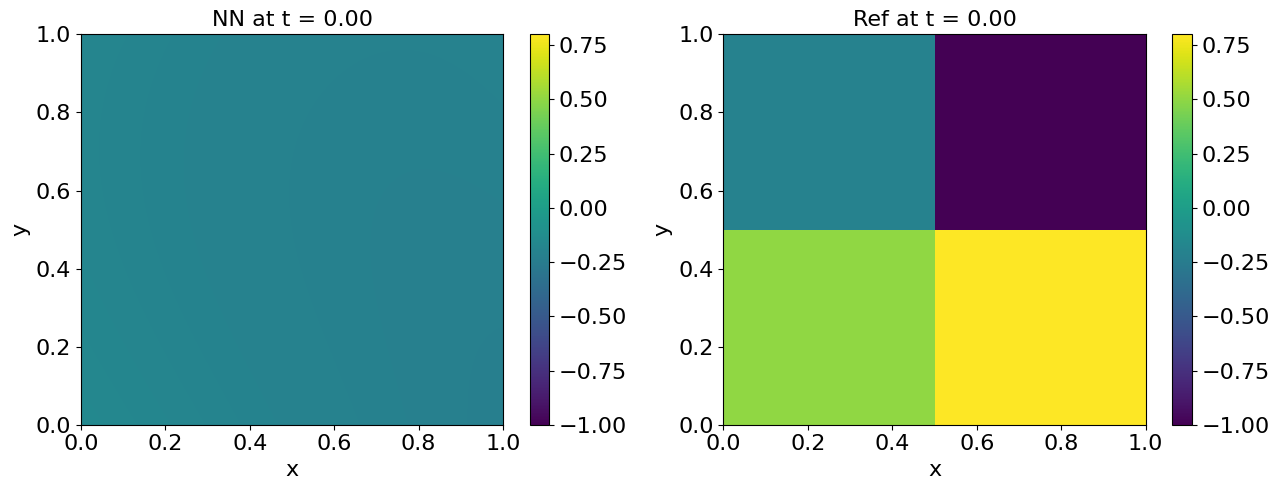

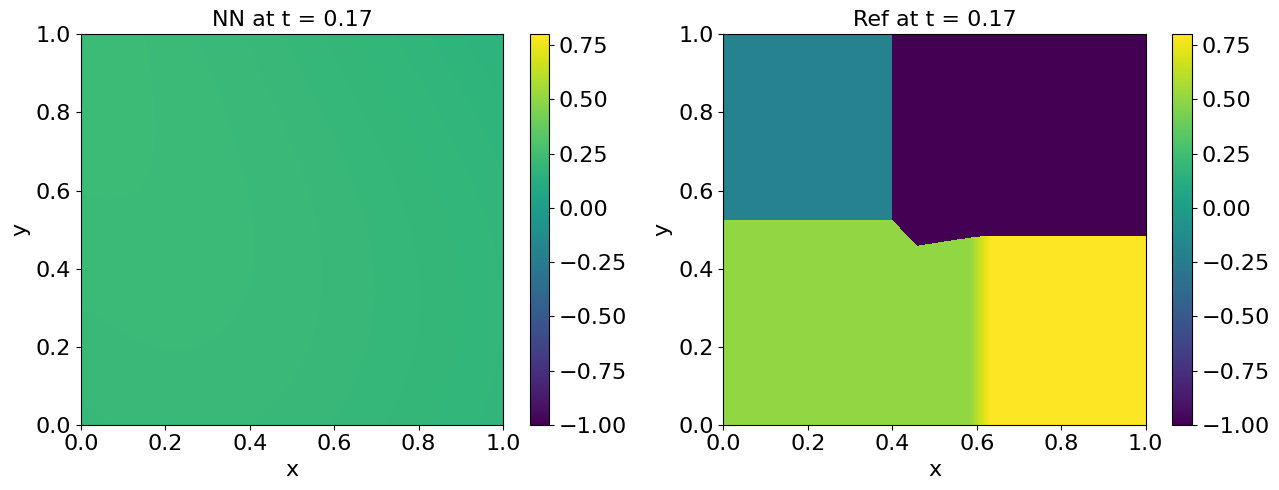

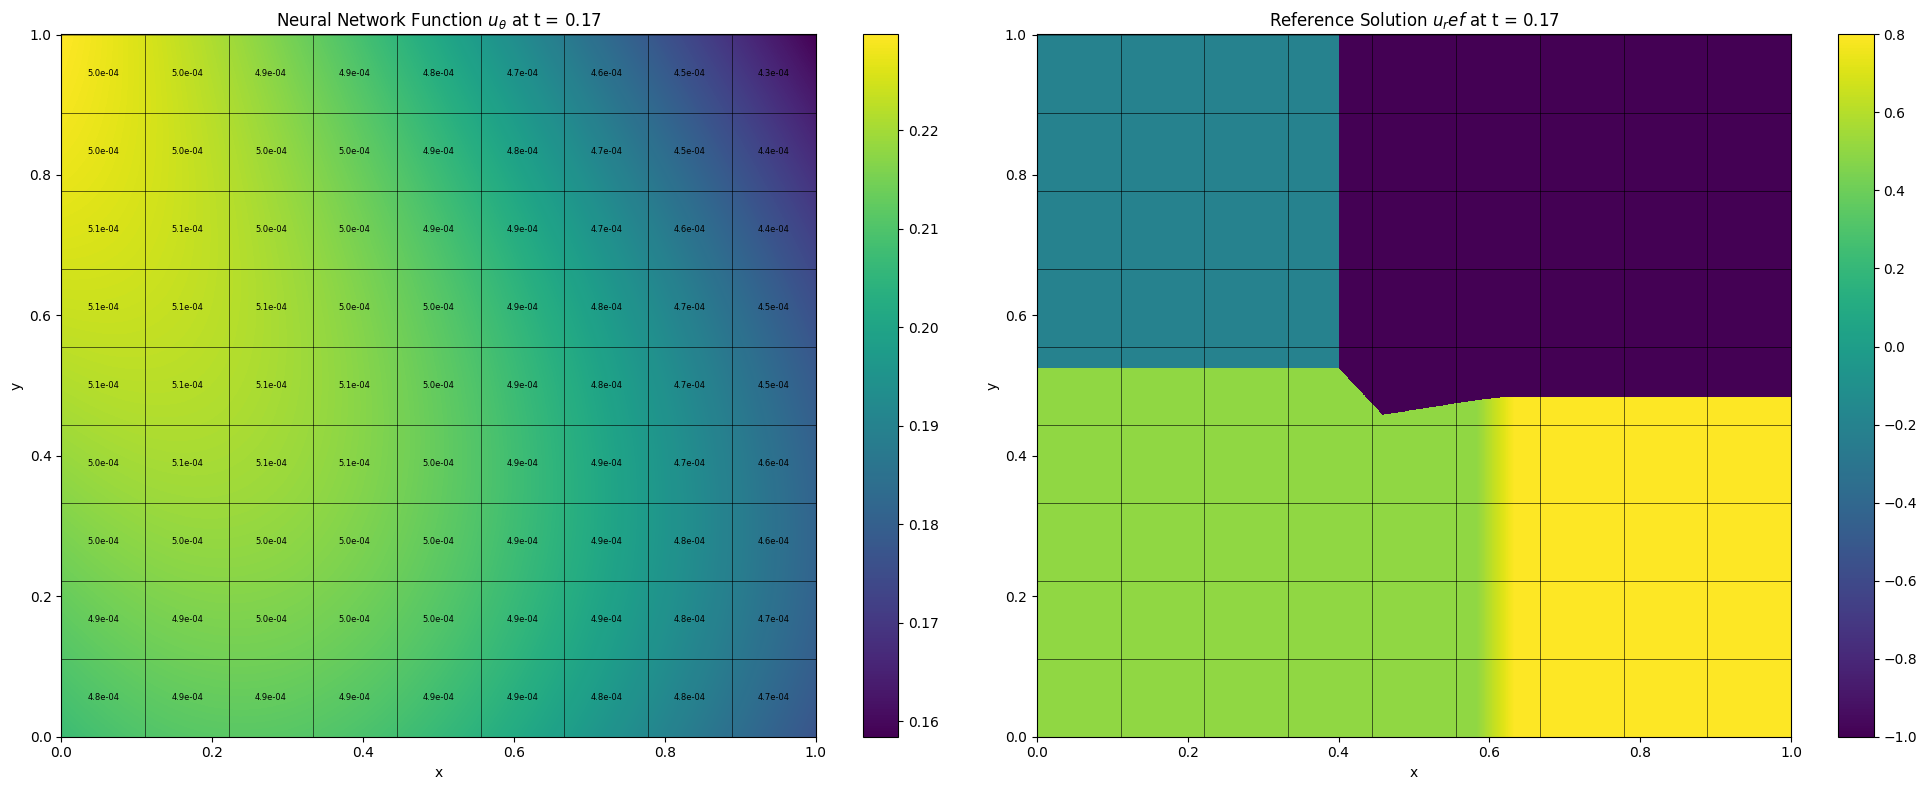

Updating importance sampling probabilities...
Grade 0, Iter 100, loss_eqn: 0.106884, loss_eqn_from_kh: 0.106884 loss_l1: 0.106884, loss_ibc: 0.512065
Updating importance sampling probabilities...
Grade 0, Iter 200, loss_eqn: 0.160752, loss_eqn_from_kh: 0.160752 loss_l1: 0.160752, loss_ibc: 0.124808
Updating importance sampling probabilities...
Grade 0, Iter 300, loss_eqn: 0.156079, loss_eqn_from_kh: 0.156079 loss_l1: 0.156079, loss_ibc: 0.054533
Updating importance sampling probabilities...
Grade 0, Iter 400, loss_eqn: 0.097712, loss_eqn_from_kh: 0.097712 loss_l1: 0.097712, loss_ibc: 0.028550
Updating importance sampling probabilities...
Grade 0, Iter 500, loss_eqn: 0.055563, loss_eqn_from_kh: 0.055563 loss_l1: 0.055563, loss_ibc: 0.016519
Updating importance sampling probabilities...
Grade 0, Iter 600, loss_eqn: 0.041612, loss_eqn_from_kh: 0.041612 loss_l1: 0.041612, loss_ibc: 0.011331
Updating importance sampling probabilities...
Grade 0, Iter 700, loss_eqn: 0.033519, loss_eqn_from_k

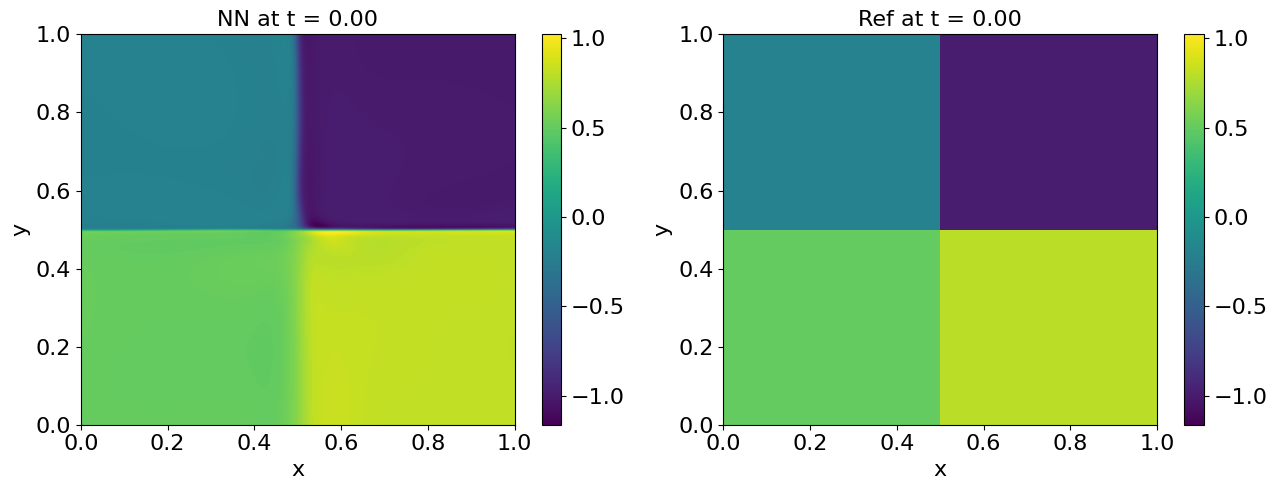

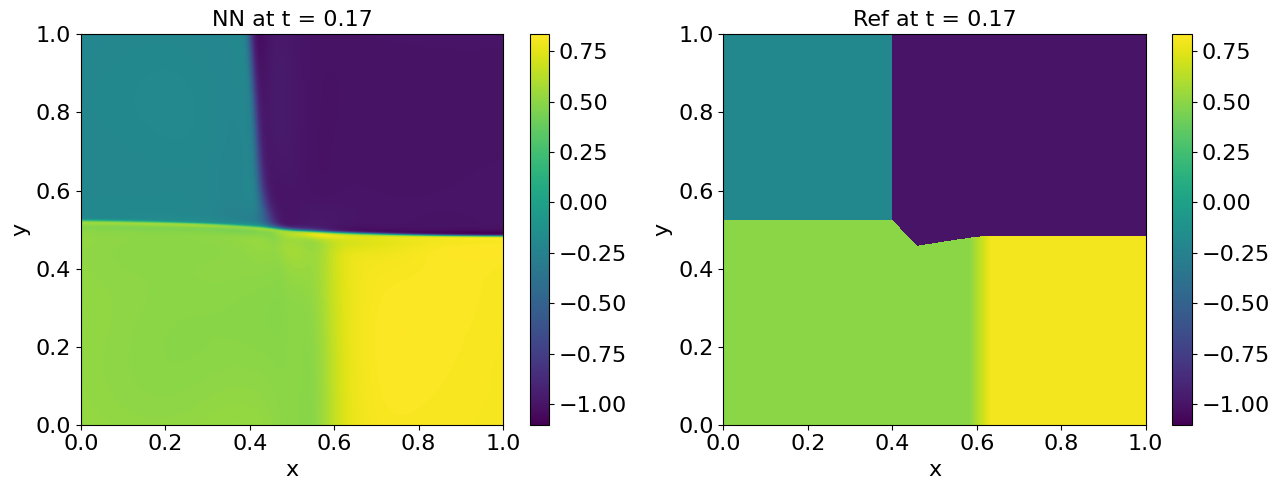

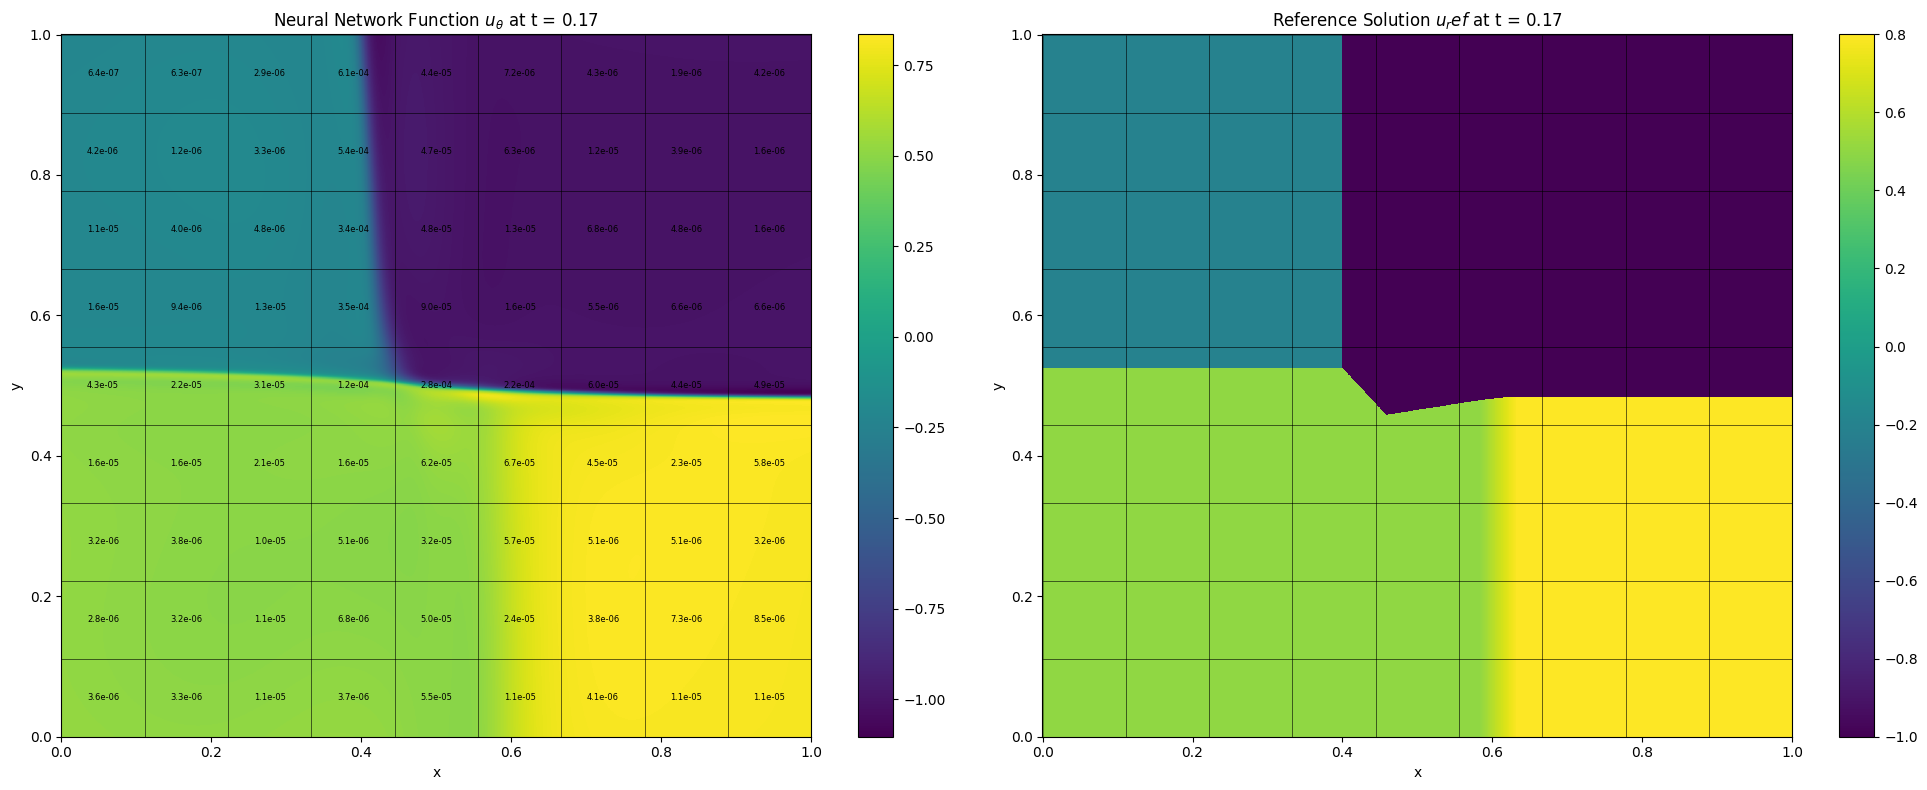

Updating importance sampling probabilities...
Grade 0, Iter 1100, loss_eqn: 0.024862, loss_eqn_from_kh: 0.024862 loss_l1: 0.024862, loss_ibc: 0.003868
Updating importance sampling probabilities...
Grade 0, Iter 1200, loss_eqn: 0.023899, loss_eqn_from_kh: 0.023899 loss_l1: 0.023899, loss_ibc: 0.003591
Updating importance sampling probabilities...
Grade 0, Iter 1300, loss_eqn: 0.022443, loss_eqn_from_kh: 0.022443 loss_l1: 0.022443, loss_ibc: 0.003255
Updating importance sampling probabilities...
Grade 0, Iter 1400, loss_eqn: 0.022236, loss_eqn_from_kh: 0.022236 loss_l1: 0.022236, loss_ibc: 0.003048
Updating importance sampling probabilities...
Grade 0, Iter 1500, loss_eqn: 0.021789, loss_eqn_from_kh: 0.021789 loss_l1: 0.021789, loss_ibc: 0.002917
Updating importance sampling probabilities...
Grade 0, Iter 1600, loss_eqn: 0.022278, loss_eqn_from_kh: 0.022278 loss_l1: 0.022278, loss_ibc: 0.002746
Updating importance sampling probabilities...
Grade 0, Iter 1700, loss_eqn: 0.021111, loss_eqn

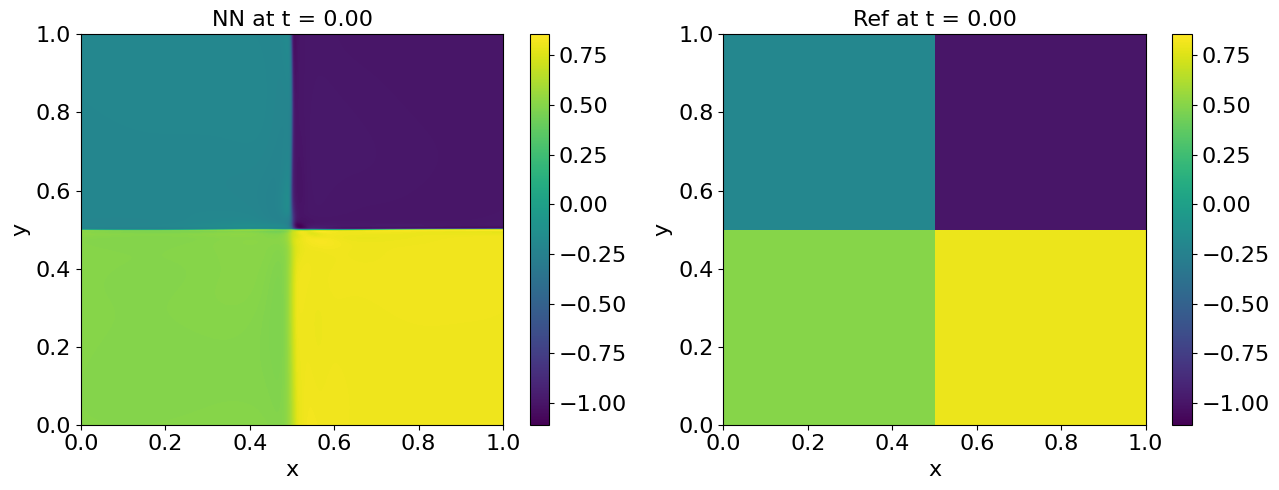

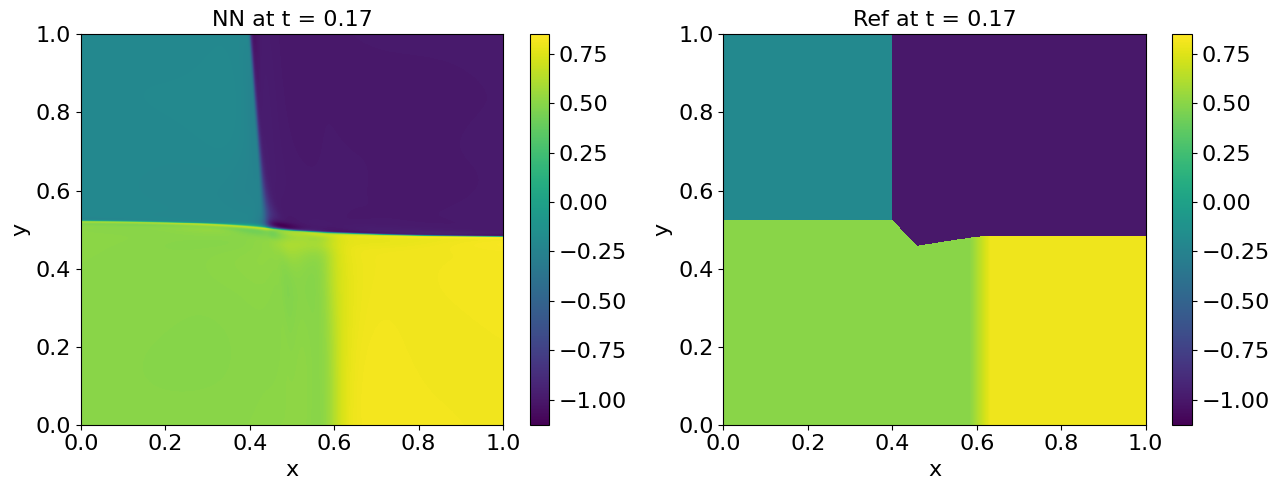

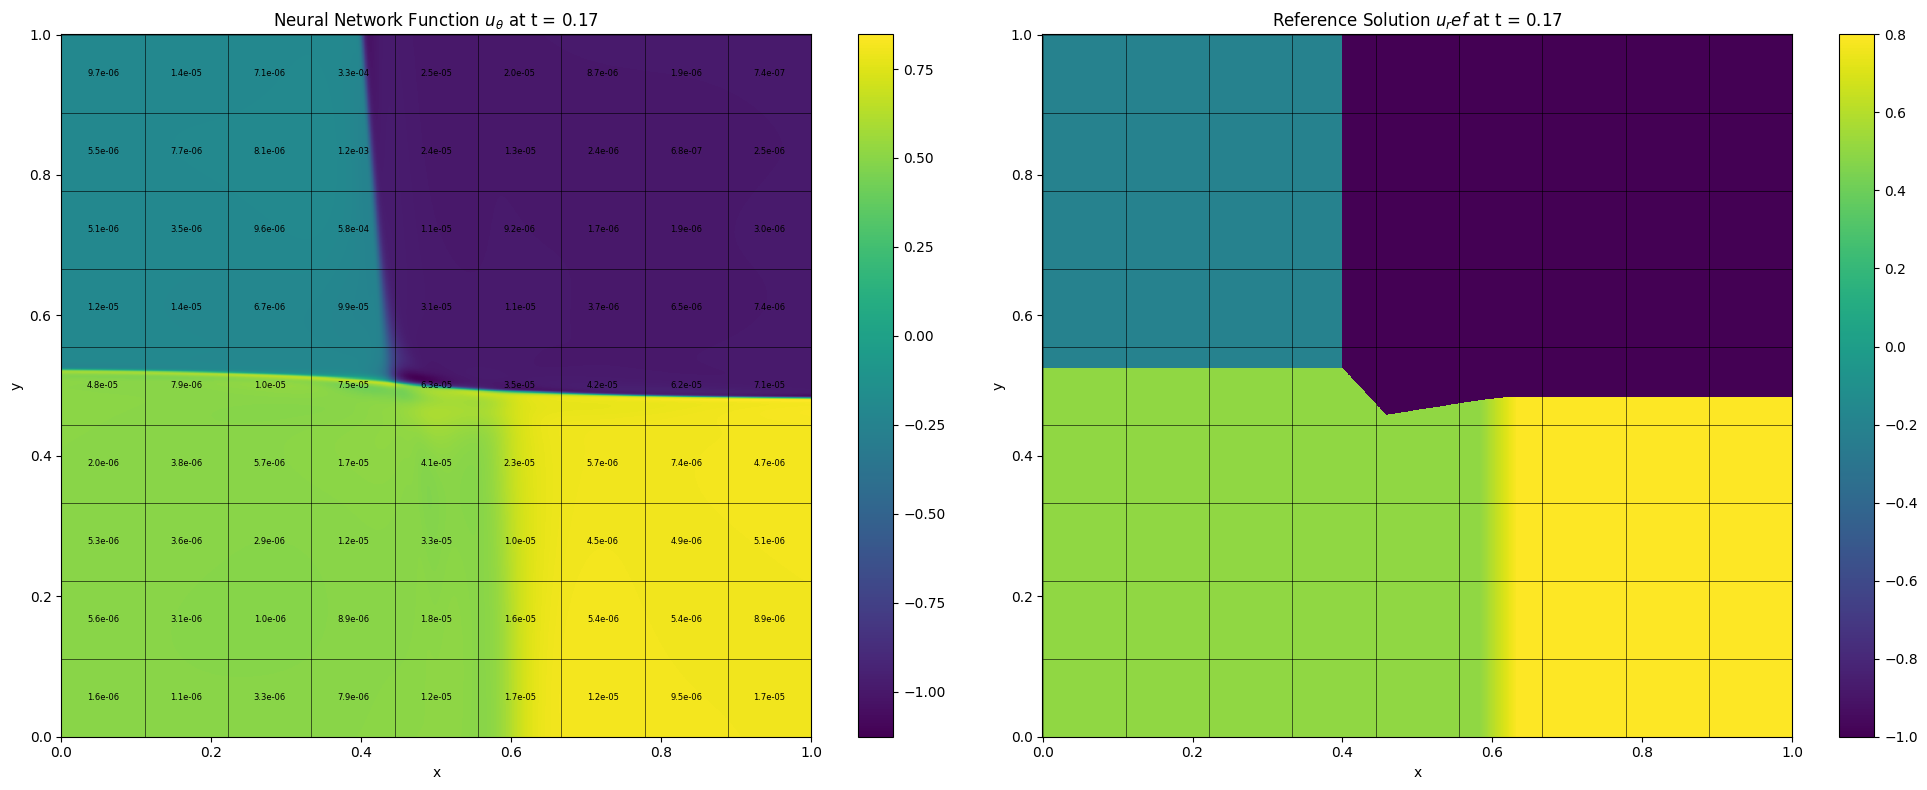

Updating importance sampling probabilities...
Grade 0, Iter 2100, loss_eqn: 0.018019, loss_eqn_from_kh: 0.018019 loss_l1: 0.018019, loss_ibc: 0.001519
Updating importance sampling probabilities...
Grade 0, Iter 2200, loss_eqn: 0.018671, loss_eqn_from_kh: 0.018671 loss_l1: 0.018671, loss_ibc: 0.001504
Updating importance sampling probabilities...
Grade 0, Iter 2300, loss_eqn: 0.017584, loss_eqn_from_kh: 0.017584 loss_l1: 0.017584, loss_ibc: 0.001430
Updating importance sampling probabilities...
Grade 0, Iter 2400, loss_eqn: 0.017439, loss_eqn_from_kh: 0.017439 loss_l1: 0.017439, loss_ibc: 0.001329
Updating importance sampling probabilities...
Grade 0, Iter 2500, loss_eqn: 0.017397, loss_eqn_from_kh: 0.017397 loss_l1: 0.017397, loss_ibc: 0.001469
Updating importance sampling probabilities...
Grade 0, Iter 2600, loss_eqn: 0.015199, loss_eqn_from_kh: 0.015199 loss_l1: 0.015199, loss_ibc: 0.001352
Updating importance sampling probabilities...
Grade 0, Iter 2700, loss_eqn: 0.014635, loss_eqn

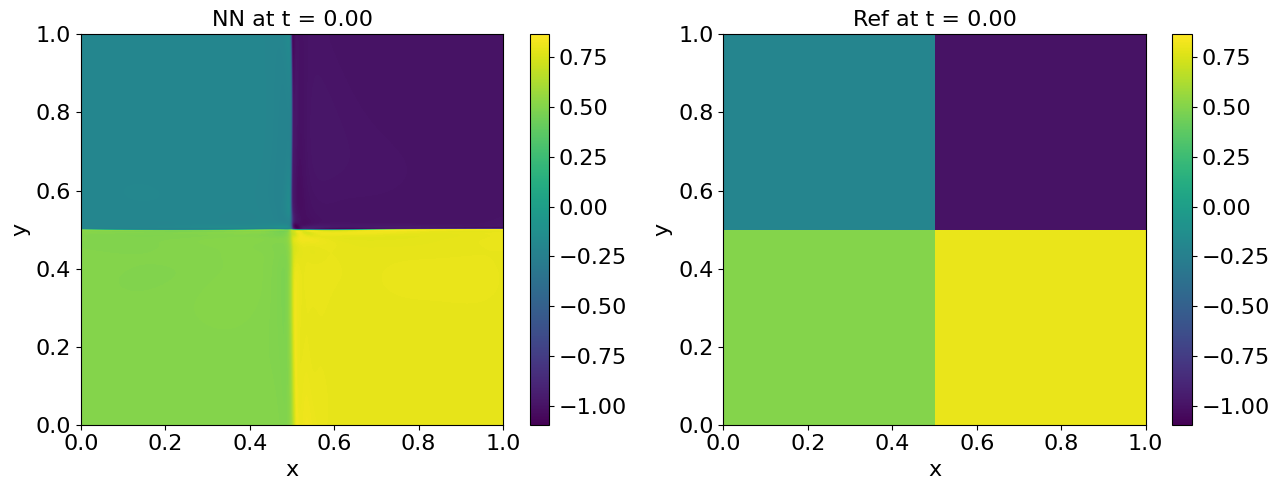

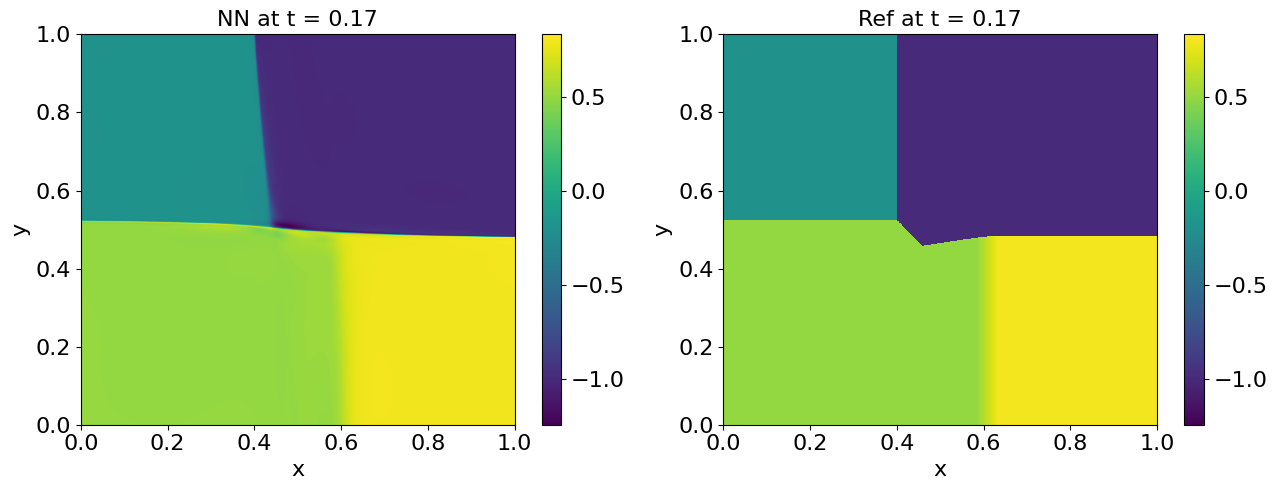

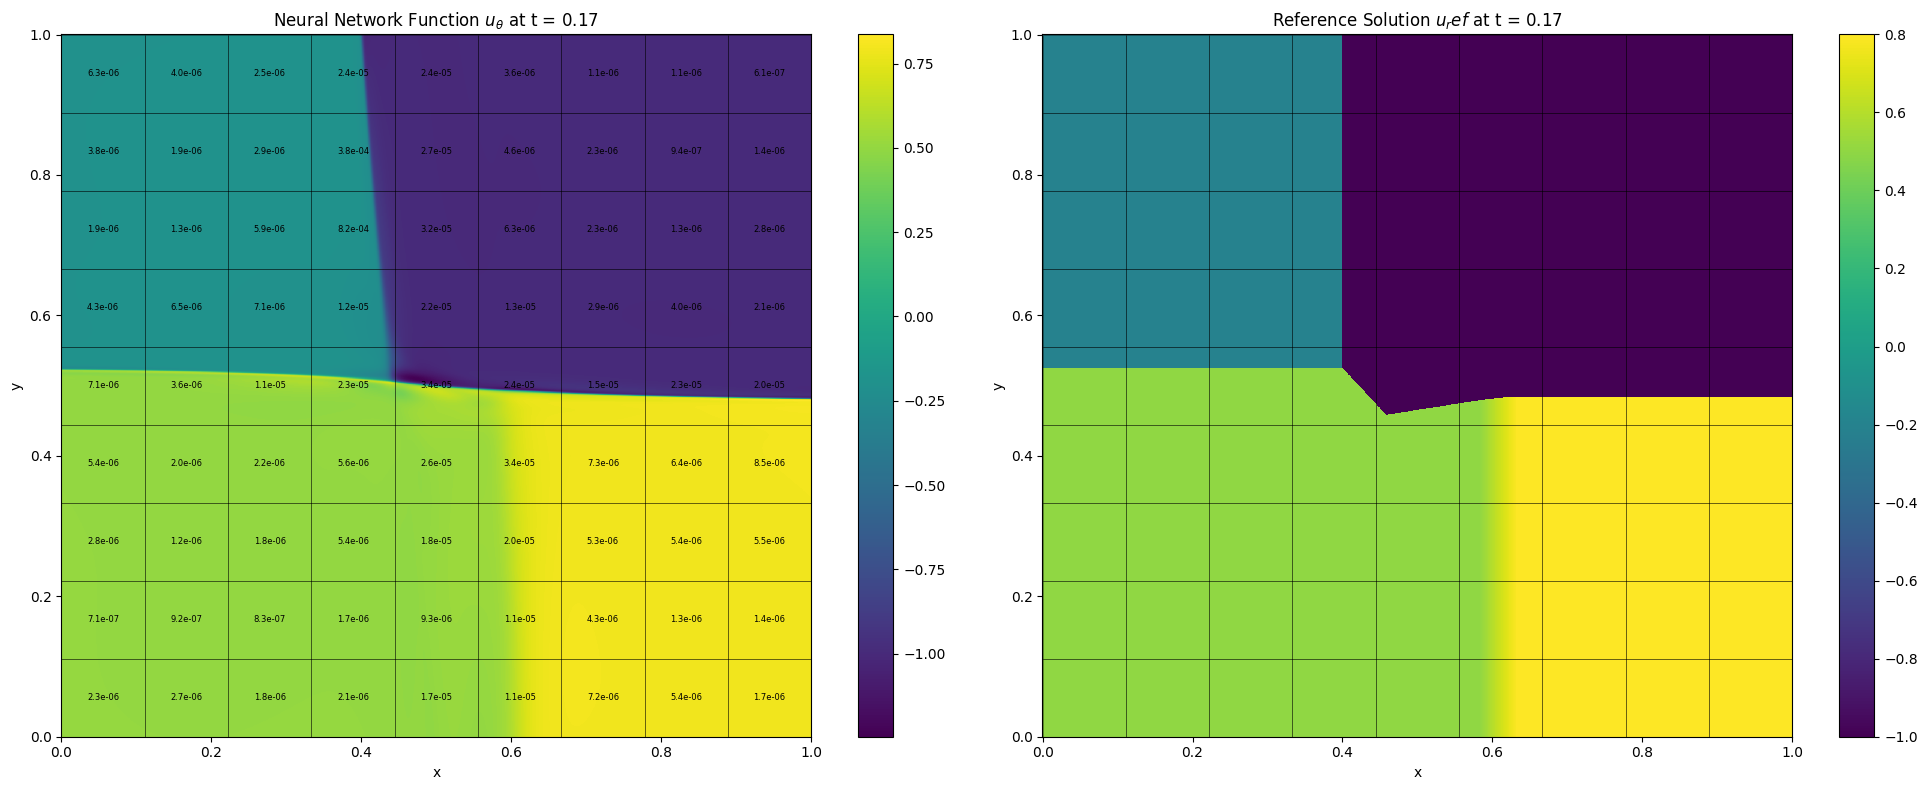

Updating importance sampling probabilities...
Grade 0, Iter 3100, loss_eqn: 0.014151, loss_eqn_from_kh: 0.014151 loss_l1: 0.014151, loss_ibc: 0.001385
Updating importance sampling probabilities...
Grade 0, Iter 3200, loss_eqn: 0.012992, loss_eqn_from_kh: 0.012992 loss_l1: 0.012992, loss_ibc: 0.001048
Updating importance sampling probabilities...
Grade 0, Iter 3300, loss_eqn: 0.012717, loss_eqn_from_kh: 0.012717 loss_l1: 0.012717, loss_ibc: 0.000828
Updating importance sampling probabilities...
Grade 0, Iter 3400, loss_eqn: 0.011943, loss_eqn_from_kh: 0.011943 loss_l1: 0.011943, loss_ibc: 0.000809
Updating importance sampling probabilities...
Grade 0, Iter 3500, loss_eqn: 0.011608, loss_eqn_from_kh: 0.011608 loss_l1: 0.011608, loss_ibc: 0.001147
Updating importance sampling probabilities...
Grade 0, Iter 3600, loss_eqn: 0.010995, loss_eqn_from_kh: 0.010995 loss_l1: 0.010995, loss_ibc: 0.000848
Updating importance sampling probabilities...
Grade 0, Iter 3700, loss_eqn: 0.010615, loss_eqn

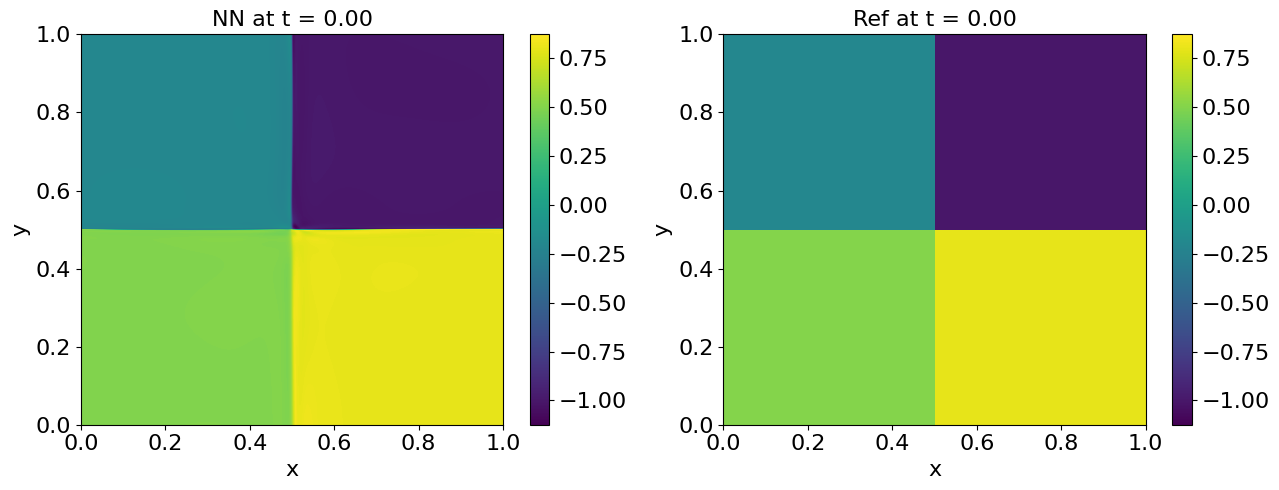

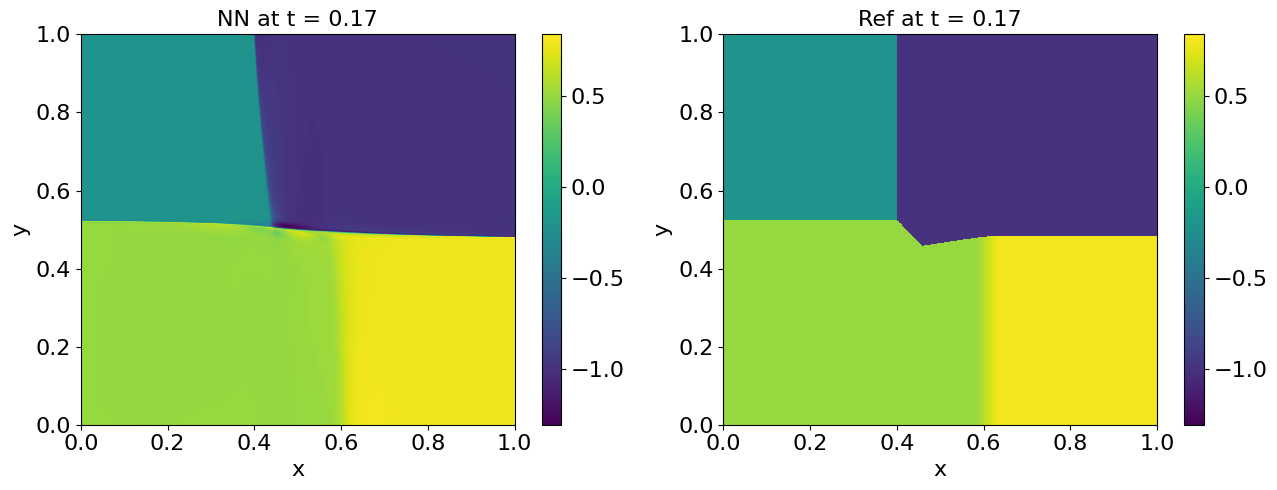

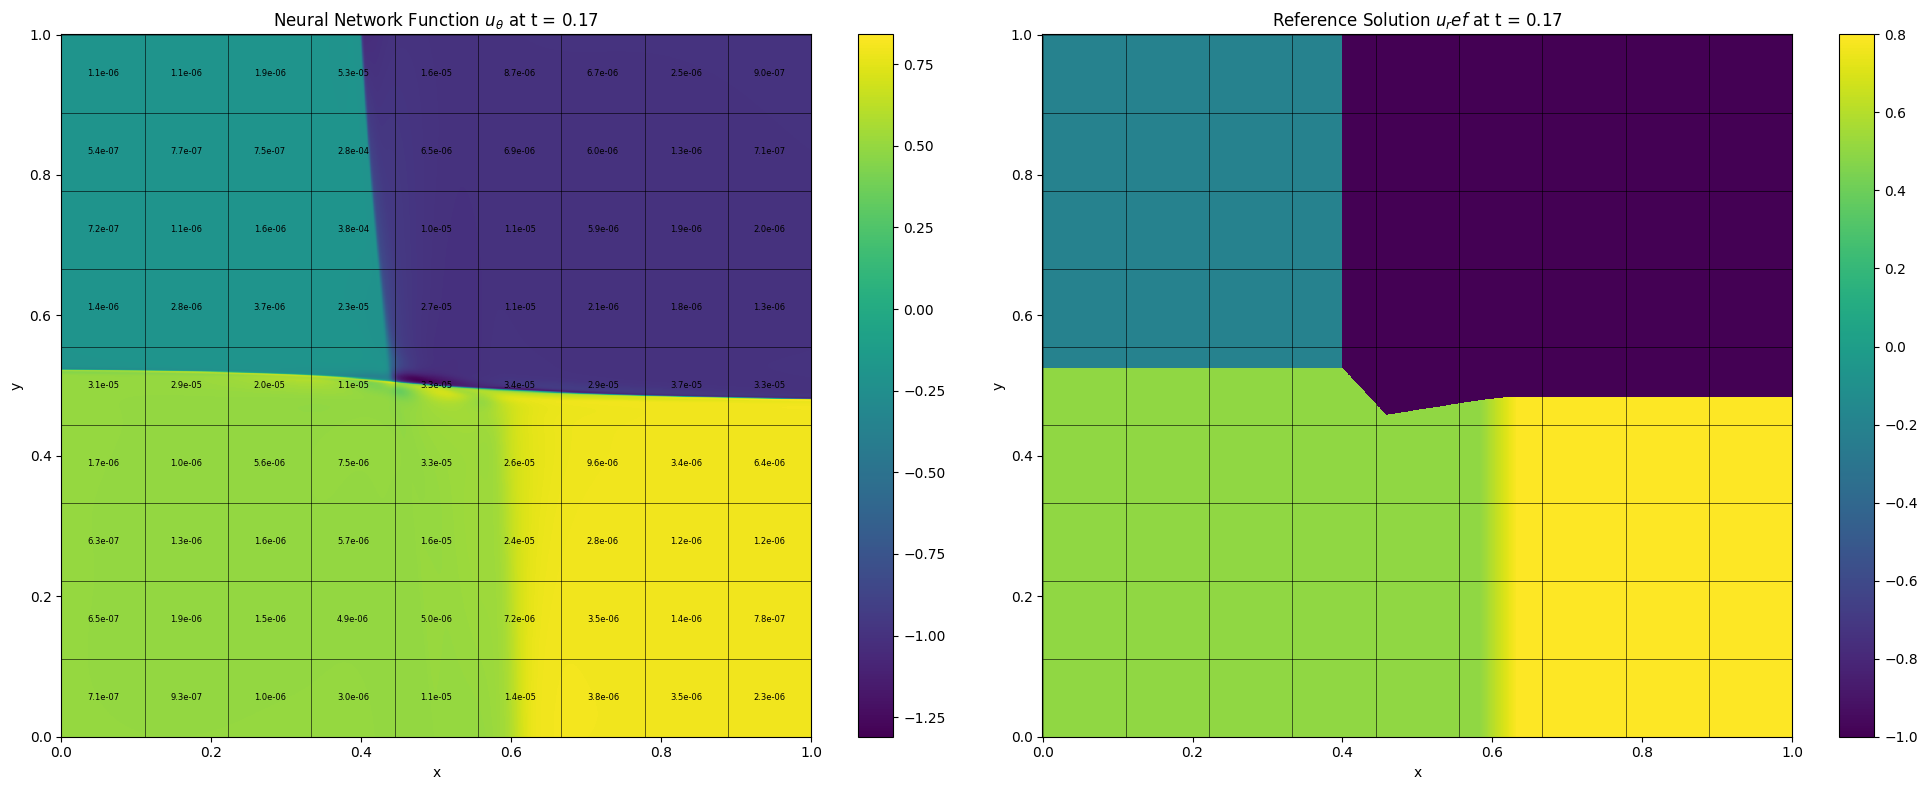

Updating importance sampling probabilities...
Grade 0, Iter 4100, loss_eqn: 0.009726, loss_eqn_from_kh: 0.009726 loss_l1: 0.009726, loss_ibc: 0.000654
Updating importance sampling probabilities...
Grade 0, Iter 4200, loss_eqn: 0.008690, loss_eqn_from_kh: 0.008690 loss_l1: 0.008690, loss_ibc: 0.000825
Updating importance sampling probabilities...
Grade 0, Iter 4300, loss_eqn: 0.008489, loss_eqn_from_kh: 0.008489 loss_l1: 0.008489, loss_ibc: 0.000642
Updating importance sampling probabilities...
Grade 0, Iter 4400, loss_eqn: 0.008569, loss_eqn_from_kh: 0.008569 loss_l1: 0.008569, loss_ibc: 0.000709
Updating importance sampling probabilities...
Grade 0, Iter 4500, loss_eqn: 0.008686, loss_eqn_from_kh: 0.008686 loss_l1: 0.008686, loss_ibc: 0.000857
Updating importance sampling probabilities...
Grade 0, Iter 4600, loss_eqn: 0.008352, loss_eqn_from_kh: 0.008352 loss_l1: 0.008352, loss_ibc: 0.000600
Updating importance sampling probabilities...
Grade 0, Iter 4700, loss_eqn: 0.008375, loss_eqn

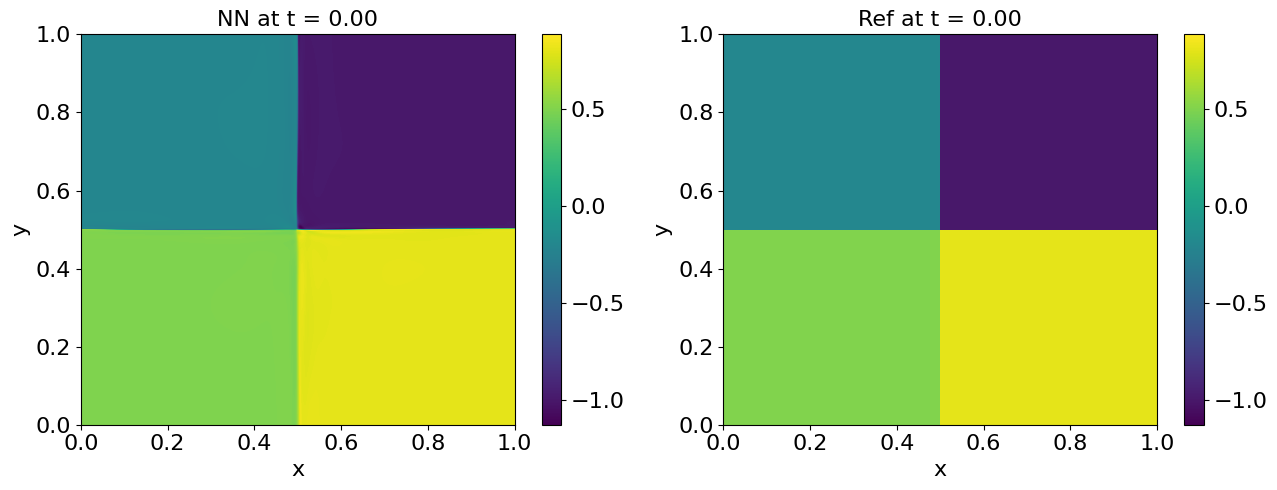

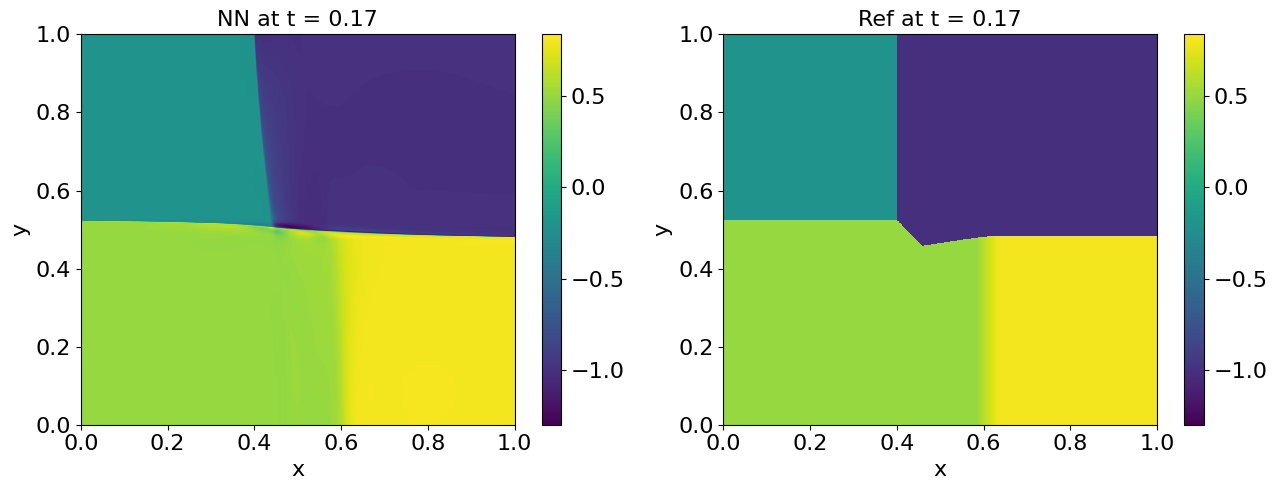

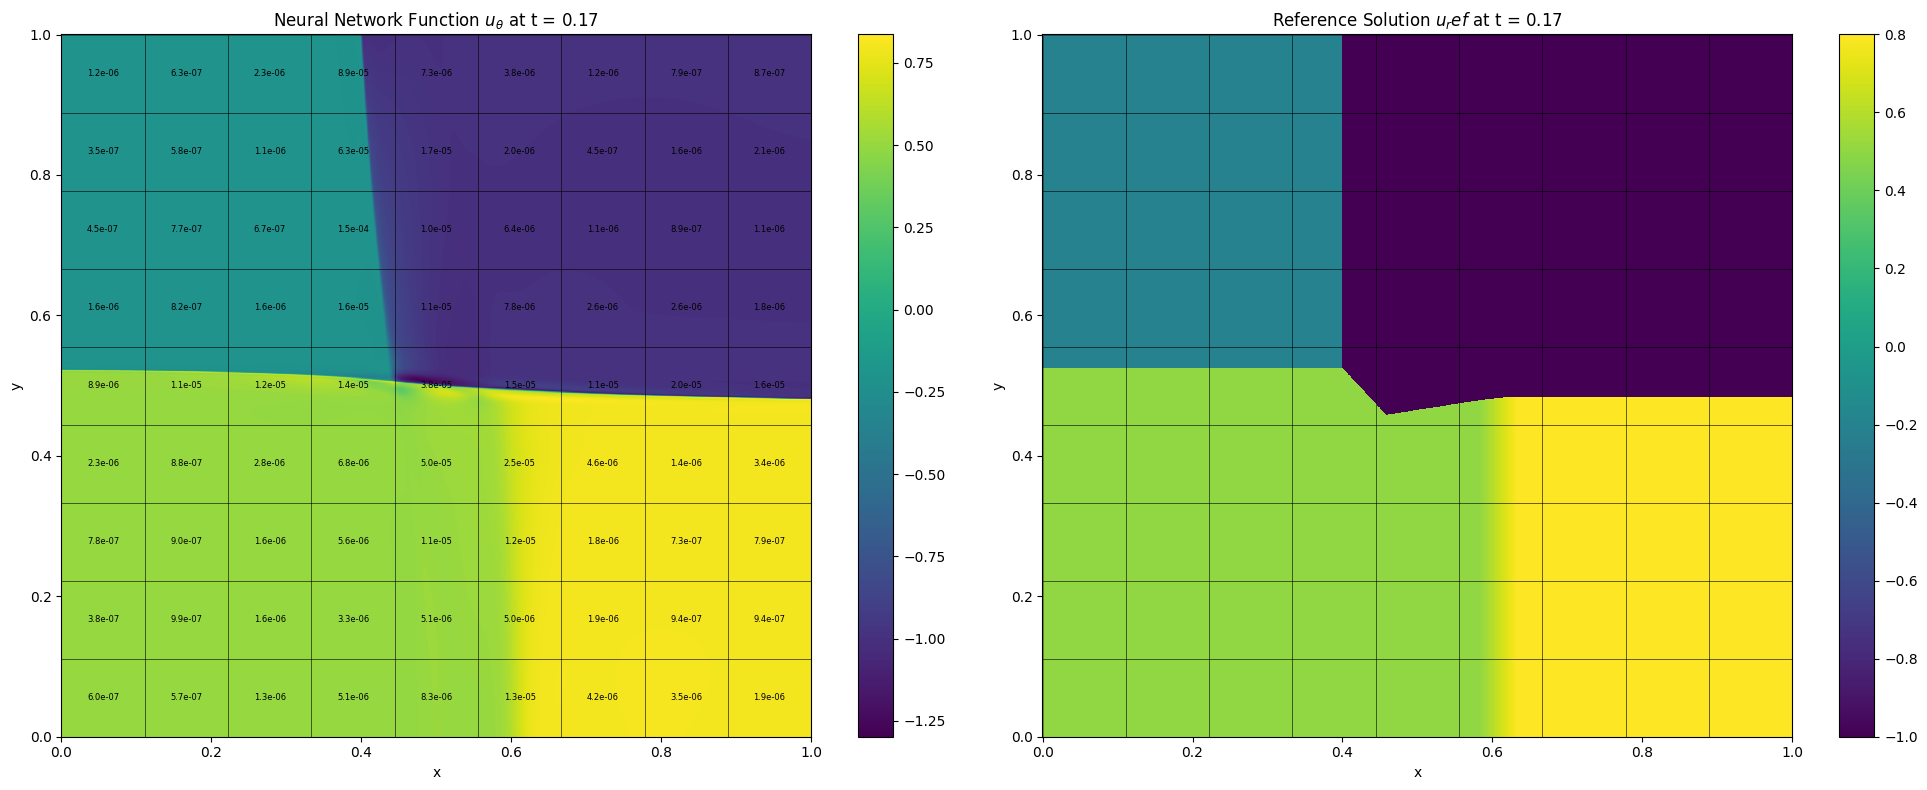

Updating importance sampling probabilities...
Grade 0, Iter 5100, loss_eqn: 0.006316, loss_eqn_from_kh: 0.006316 loss_l1: 0.006316, loss_ibc: 0.000569
Updating importance sampling probabilities...
Grade 0, Iter 5200, loss_eqn: 0.007112, loss_eqn_from_kh: 0.007112 loss_l1: 0.007112, loss_ibc: 0.000517
Updating importance sampling probabilities...
Grade 0, Iter 5300, loss_eqn: 0.006542, loss_eqn_from_kh: 0.006542 loss_l1: 0.006542, loss_ibc: 0.000510
Updating importance sampling probabilities...
Grade 0, Iter 5400, loss_eqn: 0.006129, loss_eqn_from_kh: 0.006129 loss_l1: 0.006129, loss_ibc: 0.000440
Updating importance sampling probabilities...
Grade 0, Iter 5500, loss_eqn: 0.005284, loss_eqn_from_kh: 0.005284 loss_l1: 0.005284, loss_ibc: 0.000484
Updating importance sampling probabilities...
Grade 0, Iter 5600, loss_eqn: 0.005796, loss_eqn_from_kh: 0.005796 loss_l1: 0.005796, loss_ibc: 0.000415
Updating importance sampling probabilities...
Grade 0, Iter 5700, loss_eqn: 0.005452, loss_eqn

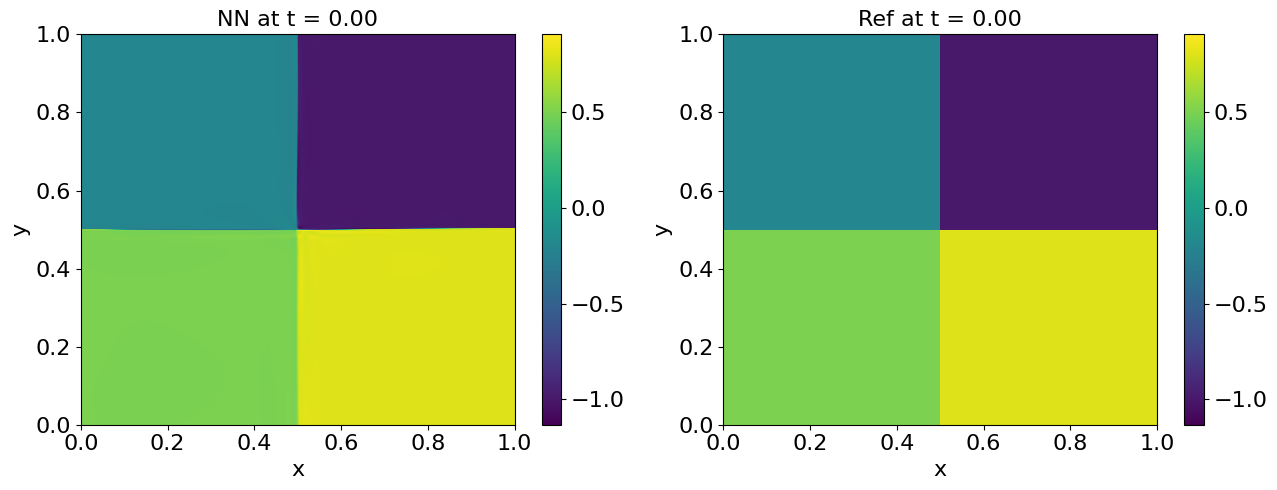

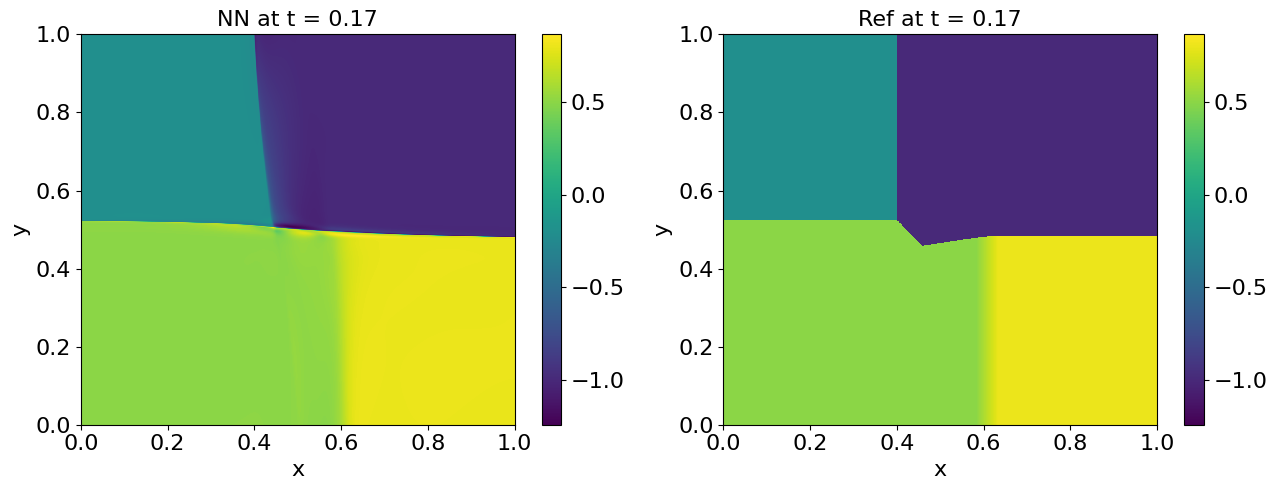

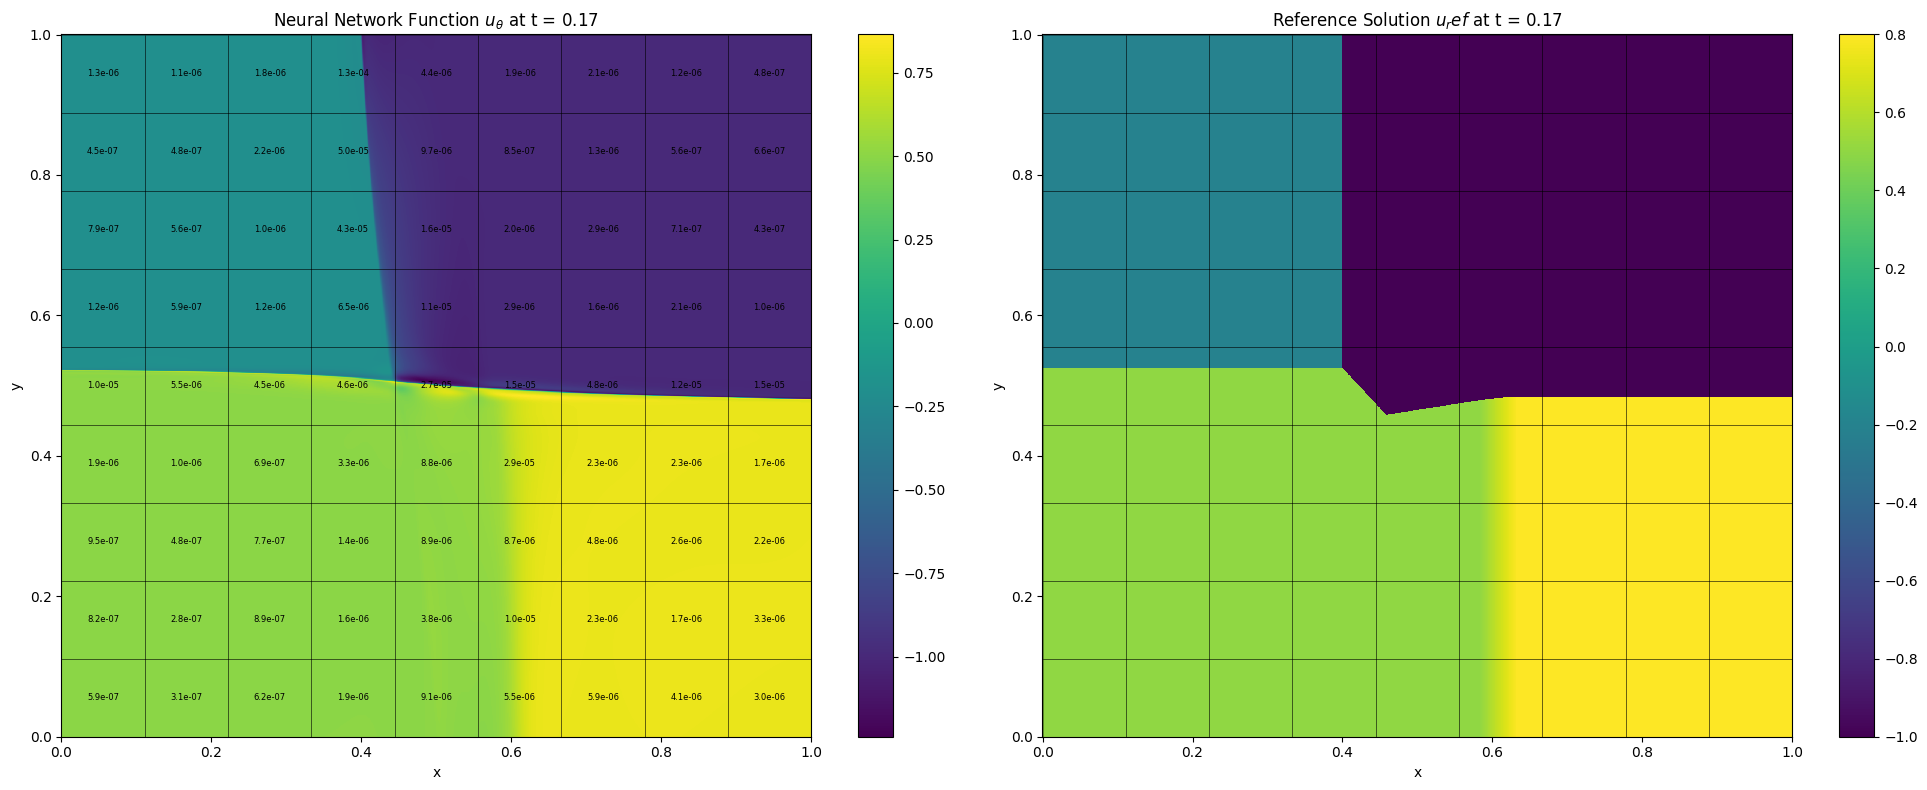

Updating importance sampling probabilities...
Grade 0, Iter 6100, loss_eqn: 0.004207, loss_eqn_from_kh: 0.004207 loss_l1: 0.004207, loss_ibc: 0.000334
Updating importance sampling probabilities...
Grade 0, Iter 6200, loss_eqn: 0.003987, loss_eqn_from_kh: 0.003987 loss_l1: 0.003987, loss_ibc: 0.000348
Updating importance sampling probabilities...
Grade 0, Iter 6300, loss_eqn: 0.003778, loss_eqn_from_kh: 0.003778 loss_l1: 0.003778, loss_ibc: 0.000324
Updating importance sampling probabilities...
Grade 0, Iter 6400, loss_eqn: 0.003593, loss_eqn_from_kh: 0.003593 loss_l1: 0.003593, loss_ibc: 0.000335
Updating importance sampling probabilities...
Grade 0, Iter 6500, loss_eqn: 0.003761, loss_eqn_from_kh: 0.003761 loss_l1: 0.003761, loss_ibc: 0.000290
Updating importance sampling probabilities...
Grade 0, Iter 6600, loss_eqn: 0.003380, loss_eqn_from_kh: 0.003380 loss_l1: 0.003380, loss_ibc: 0.000291
Updating importance sampling probabilities...
Grade 0, Iter 6700, loss_eqn: 0.004578, loss_eqn

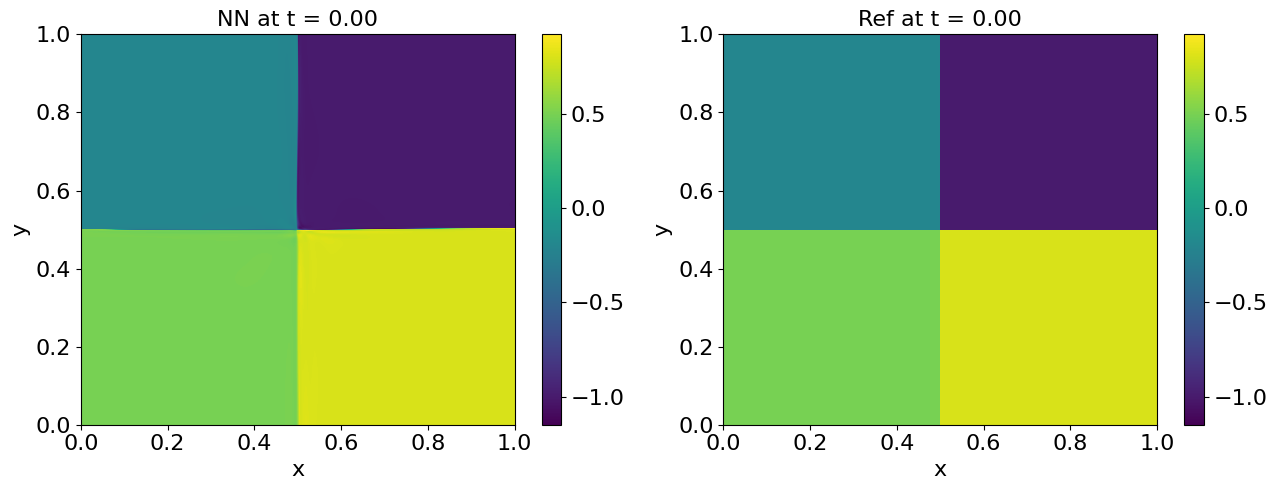

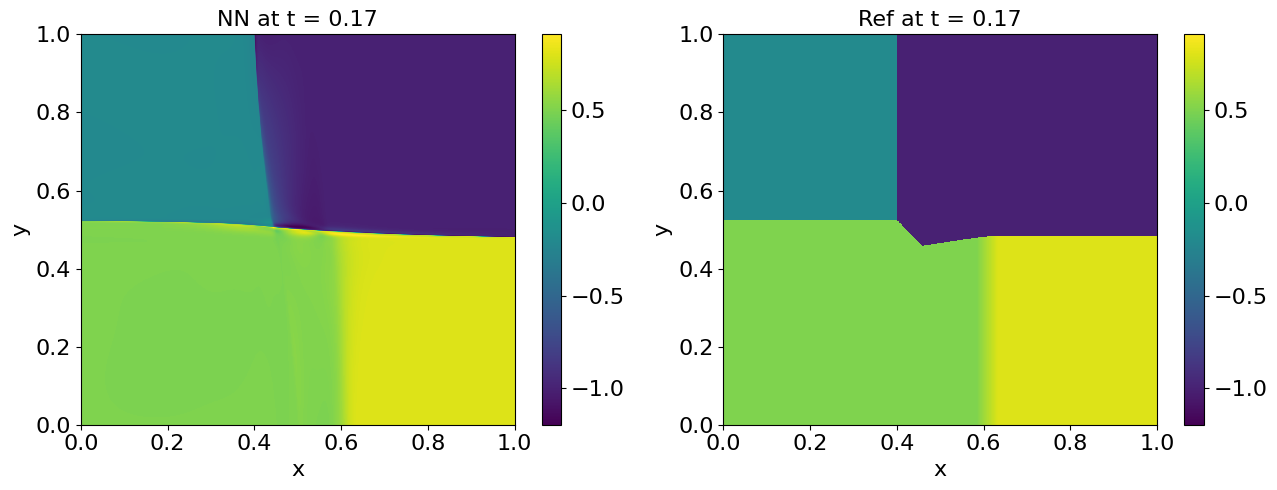

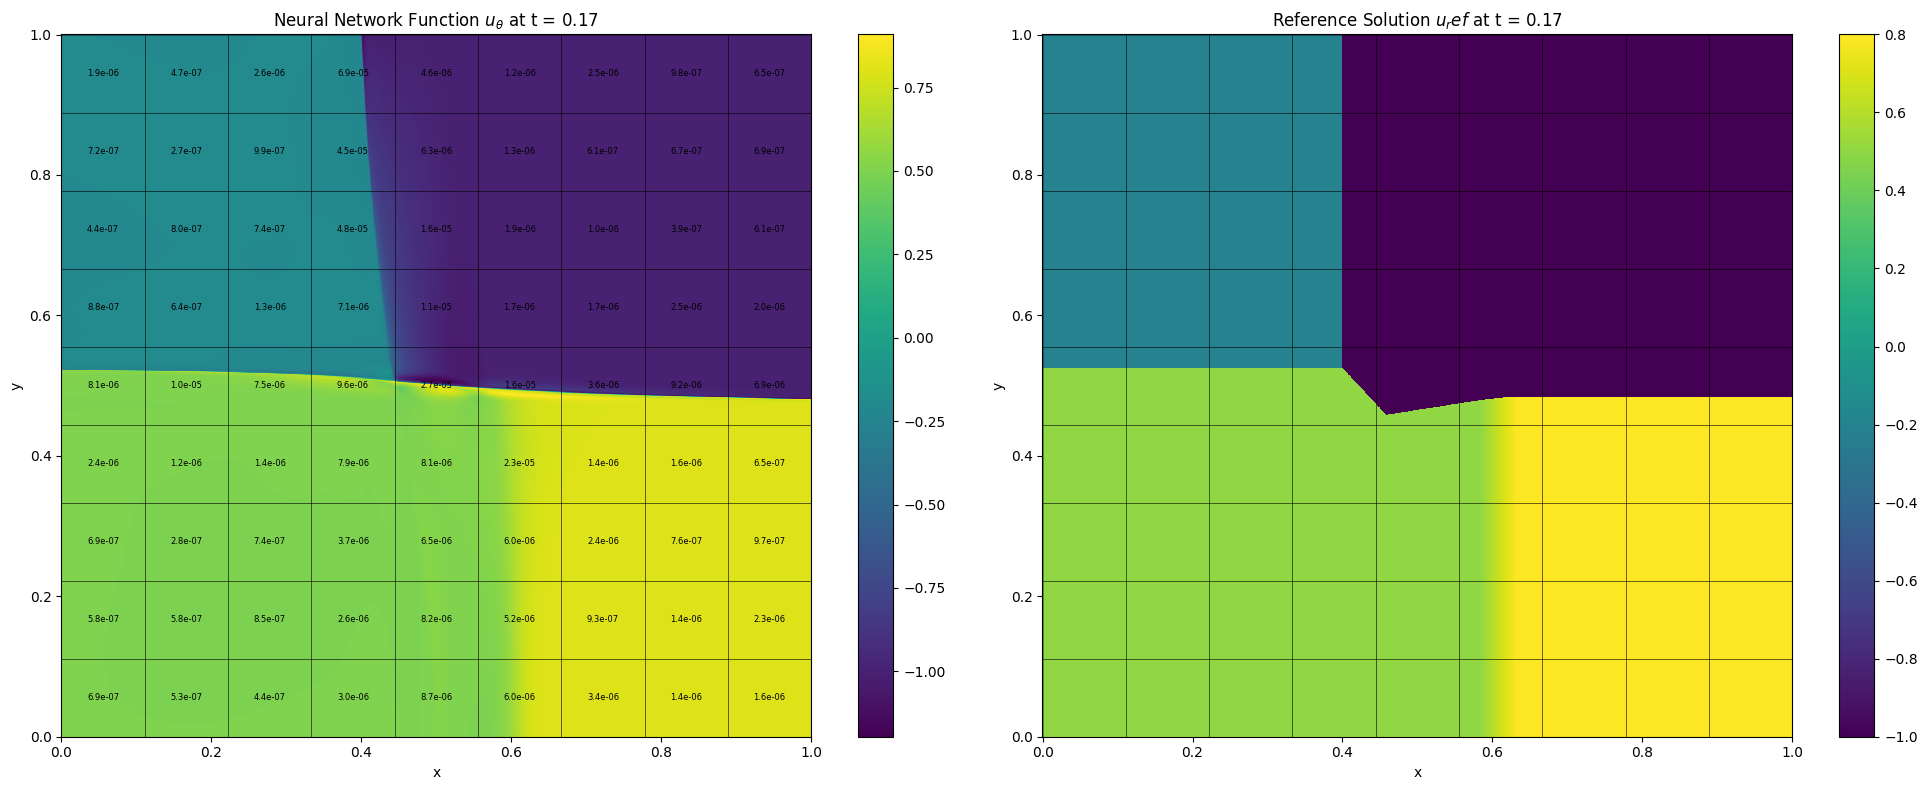

Updating importance sampling probabilities...
Grade 0, Iter 7100, loss_eqn: 0.003228, loss_eqn_from_kh: 0.003228 loss_l1: 0.003228, loss_ibc: 0.000276
Updating importance sampling probabilities...
Grade 0, Iter 7200, loss_eqn: 0.002894, loss_eqn_from_kh: 0.002894 loss_l1: 0.002894, loss_ibc: 0.000248
Updating importance sampling probabilities...
Grade 0, Iter 7300, loss_eqn: 0.002632, loss_eqn_from_kh: 0.002632 loss_l1: 0.002632, loss_ibc: 0.000243
Updating importance sampling probabilities...
Grade 0, Iter 7400, loss_eqn: 0.002596, loss_eqn_from_kh: 0.002596 loss_l1: 0.002596, loss_ibc: 0.000232
Updating importance sampling probabilities...
Grade 0, Iter 7500, loss_eqn: 0.002478, loss_eqn_from_kh: 0.002478 loss_l1: 0.002478, loss_ibc: 0.000257
Updating importance sampling probabilities...
Grade 0, Iter 7600, loss_eqn: 0.002254, loss_eqn_from_kh: 0.002254 loss_l1: 0.002254, loss_ibc: 0.000229
Updating importance sampling probabilities...
Grade 0, Iter 7700, loss_eqn: 0.002303, loss_eqn

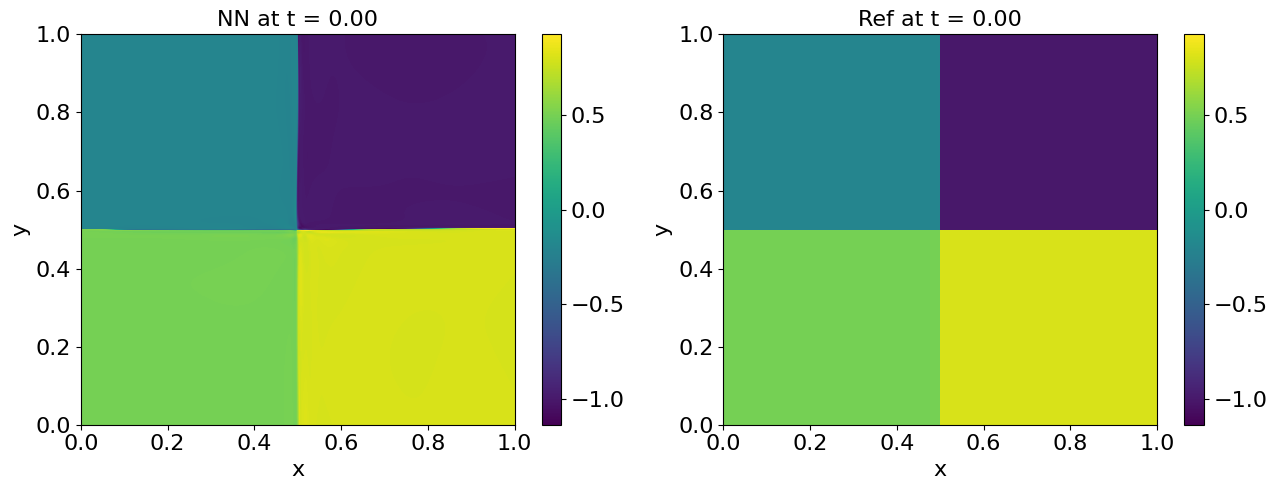

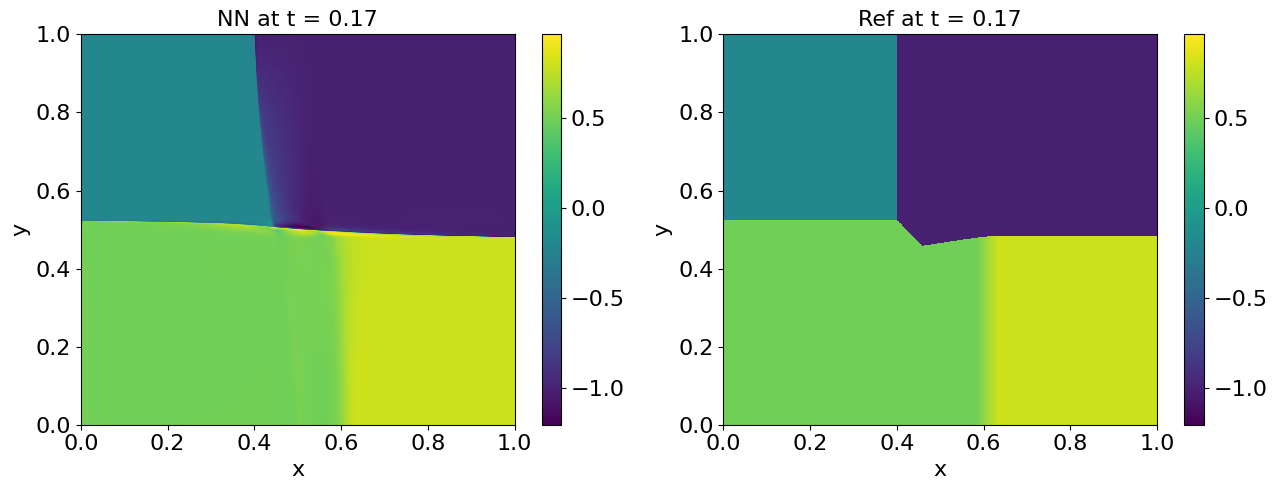

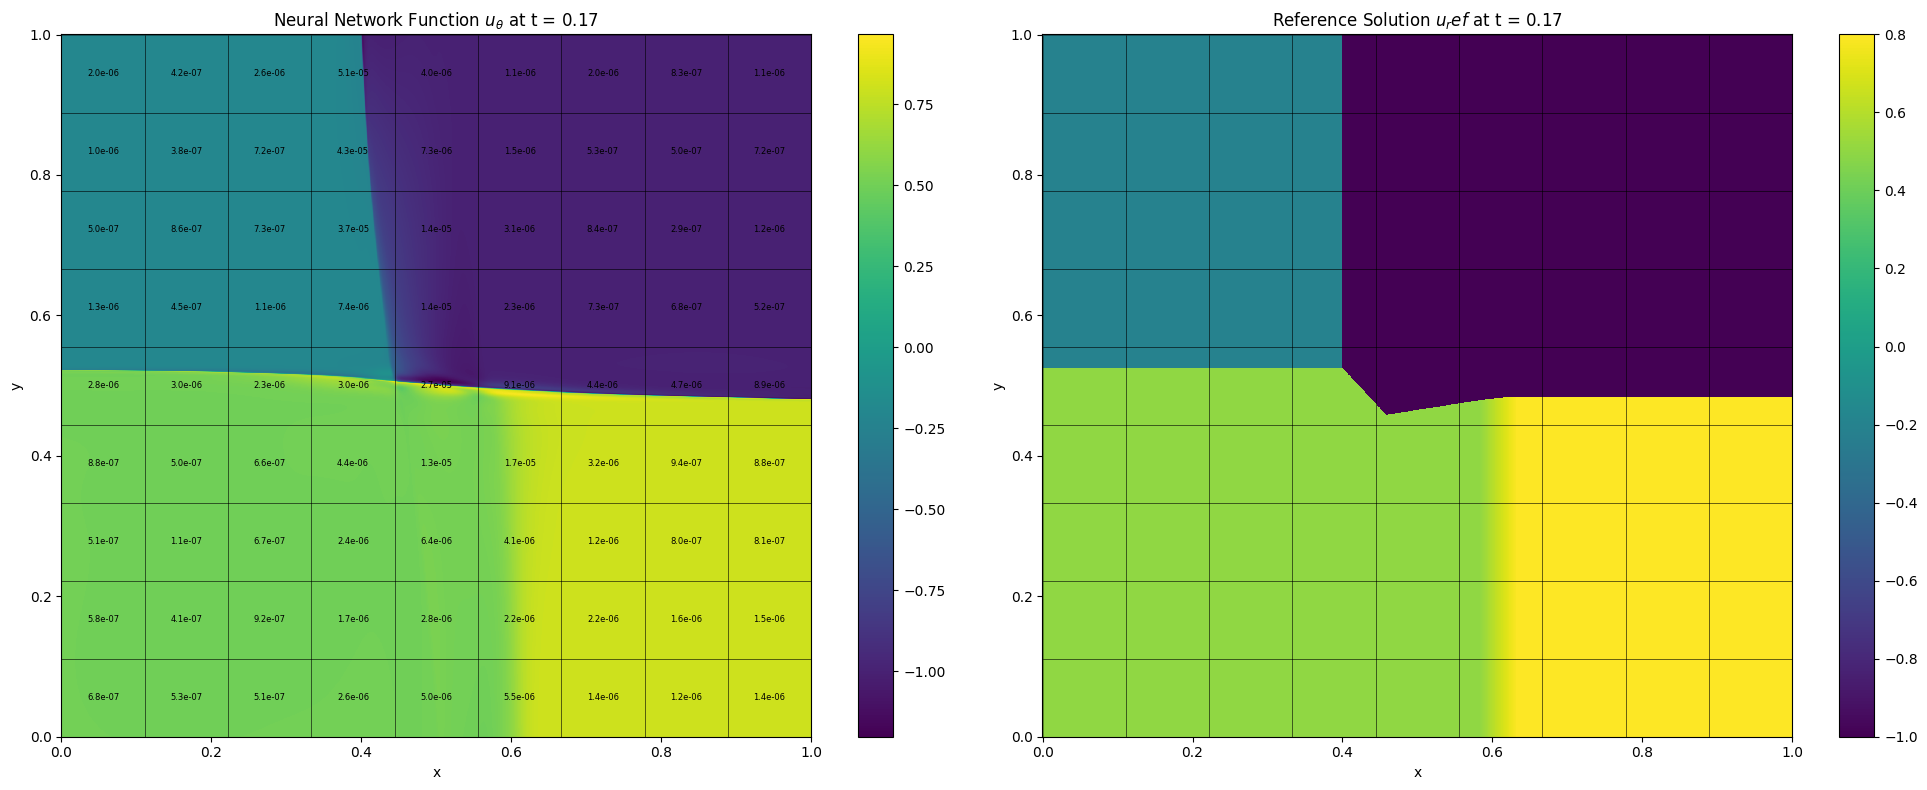

Updating importance sampling probabilities...
Grade 0, Iter 8100, loss_eqn: 0.002035, loss_eqn_from_kh: 0.002035 loss_l1: 0.002035, loss_ibc: 0.000211
Updating importance sampling probabilities...
Grade 0, Iter 8200, loss_eqn: 0.002008, loss_eqn_from_kh: 0.002008 loss_l1: 0.002008, loss_ibc: 0.000219
Updating importance sampling probabilities...
Grade 0, Iter 8300, loss_eqn: 0.001966, loss_eqn_from_kh: 0.001966 loss_l1: 0.001966, loss_ibc: 0.000207
Updating importance sampling probabilities...
Grade 0, Iter 8400, loss_eqn: 0.001913, loss_eqn_from_kh: 0.001913 loss_l1: 0.001913, loss_ibc: 0.000208
Updating importance sampling probabilities...
Grade 0, Iter 8500, loss_eqn: 0.002013, loss_eqn_from_kh: 0.002013 loss_l1: 0.002013, loss_ibc: 0.000202
Updating importance sampling probabilities...
Grade 0, Iter 8600, loss_eqn: 0.001897, loss_eqn_from_kh: 0.001897 loss_l1: 0.001897, loss_ibc: 0.000201
Updating importance sampling probabilities...
Grade 0, Iter 8700, loss_eqn: 0.001889, loss_eqn

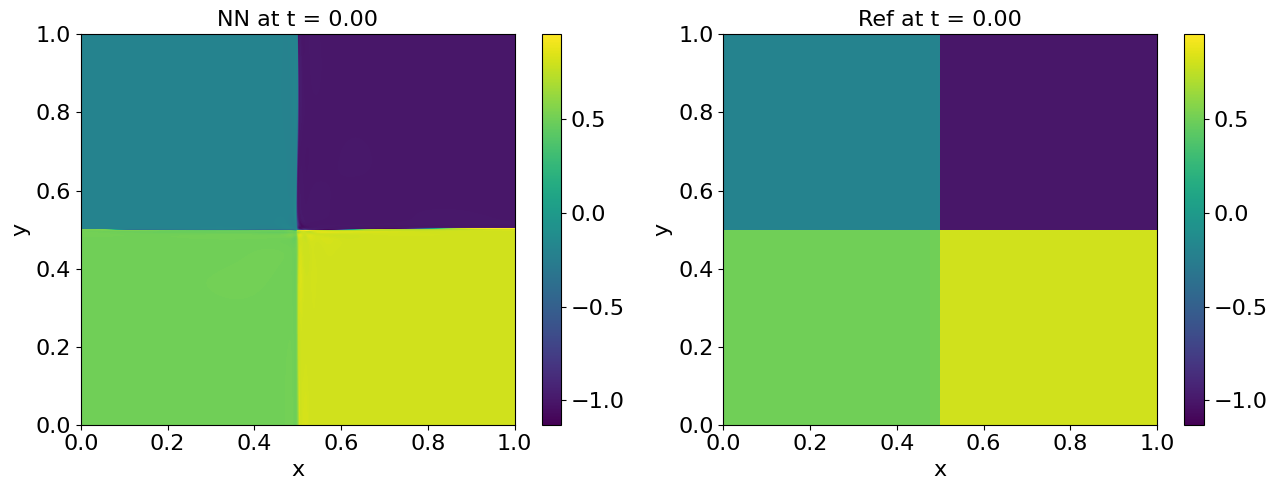

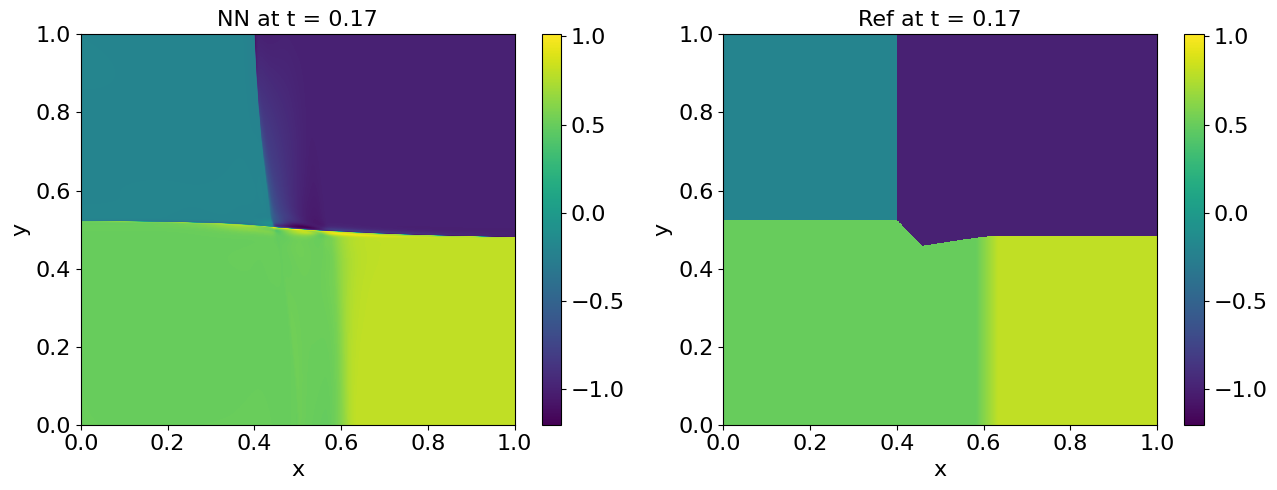

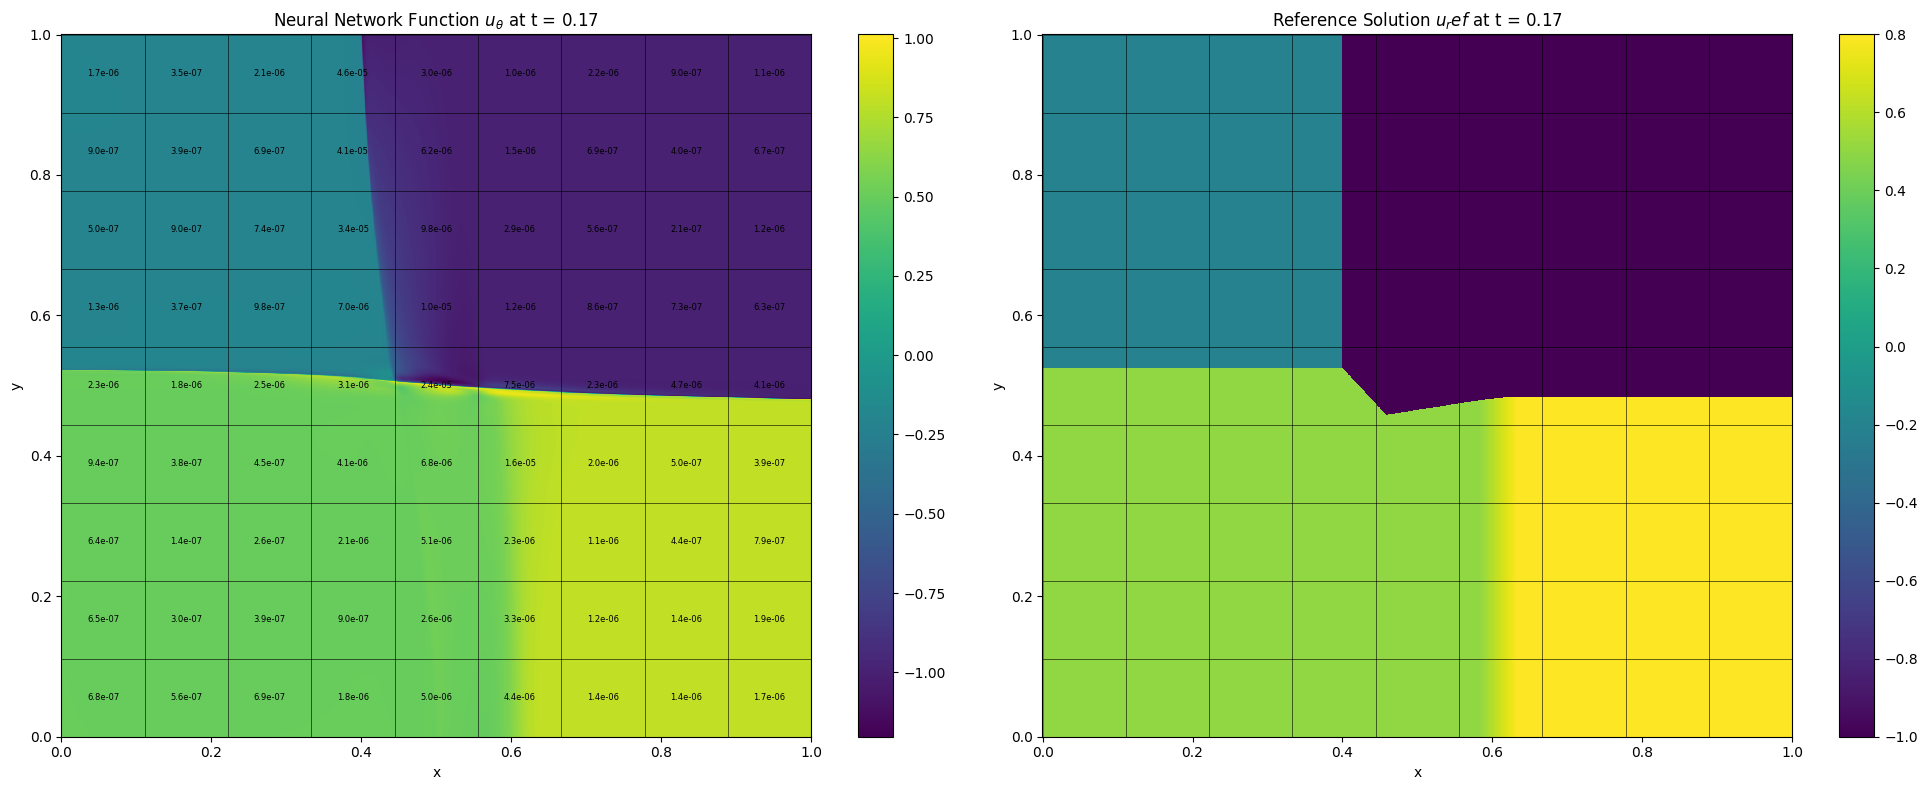

Updating importance sampling probabilities...
Grade 0, Iter 9100, loss_eqn: 0.001737, loss_eqn_from_kh: 0.001737 loss_l1: 0.001737, loss_ibc: 0.000195
Updating importance sampling probabilities...
Grade 0, Iter 9200, loss_eqn: 0.001734, loss_eqn_from_kh: 0.001734 loss_l1: 0.001734, loss_ibc: 0.000196
Updating importance sampling probabilities...
Grade 0, Iter 9300, loss_eqn: 0.001689, loss_eqn_from_kh: 0.001689 loss_l1: 0.001689, loss_ibc: 0.000193
Updating importance sampling probabilities...
Grade 0, Iter 9400, loss_eqn: 0.001747, loss_eqn_from_kh: 0.001747 loss_l1: 0.001747, loss_ibc: 0.000195
Updating importance sampling probabilities...
Grade 0, Iter 9500, loss_eqn: 0.001699, loss_eqn_from_kh: 0.001699 loss_l1: 0.001699, loss_ibc: 0.000193
Updating importance sampling probabilities...
Grade 0, Iter 9600, loss_eqn: 0.001659, loss_eqn_from_kh: 0.001659 loss_l1: 0.001659, loss_ibc: 0.000194
Updating importance sampling probabilities...
Grade 0, Iter 9700, loss_eqn: 0.001625, loss_eqn

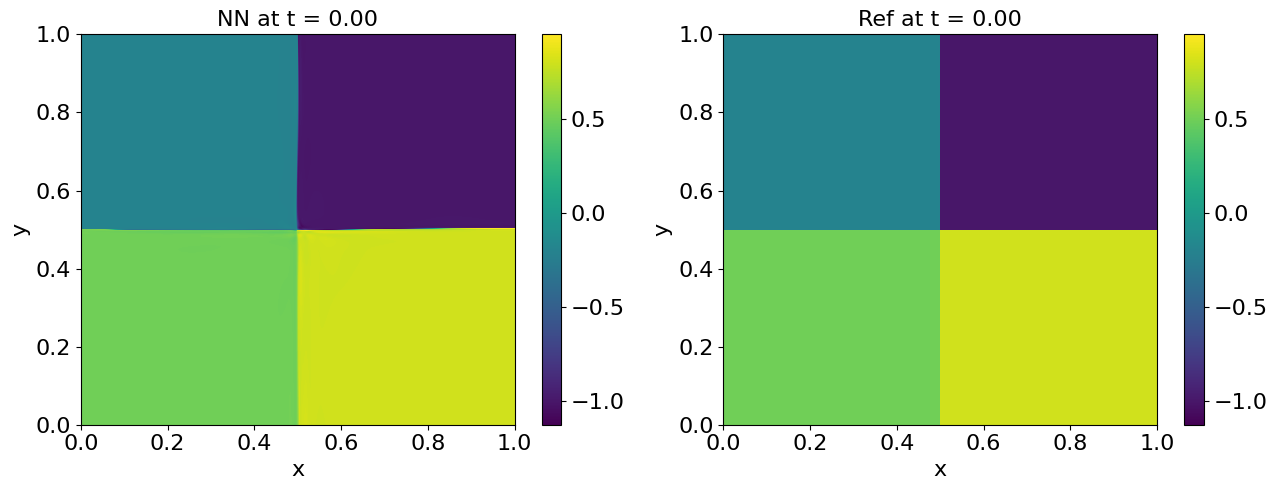

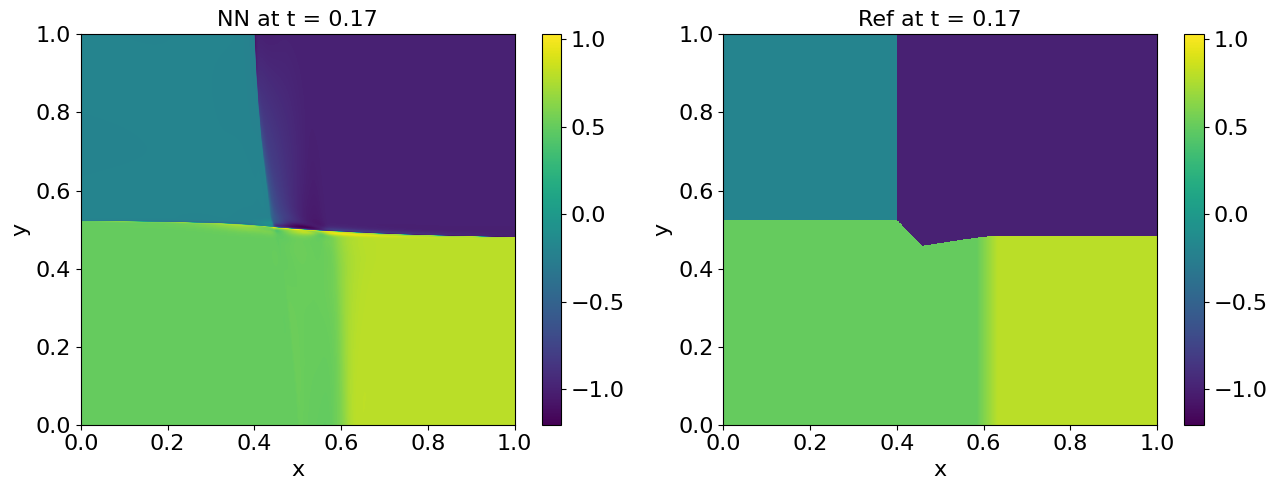

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.1667, 0.3333]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Updating importance sampling probabilities...
Grade 0, Iter 0, lambda_ic: 18.872595, lambda_bc: 18.314548, lambda_eqn: 1.076217
Updating importance sampling probabilities...
Grade 0, Iter 0, loss_eqn: 0.410669, loss_eqn_from_kh: 0.410669 loss_l1: 0.410669, loss_ibc: 2.600930


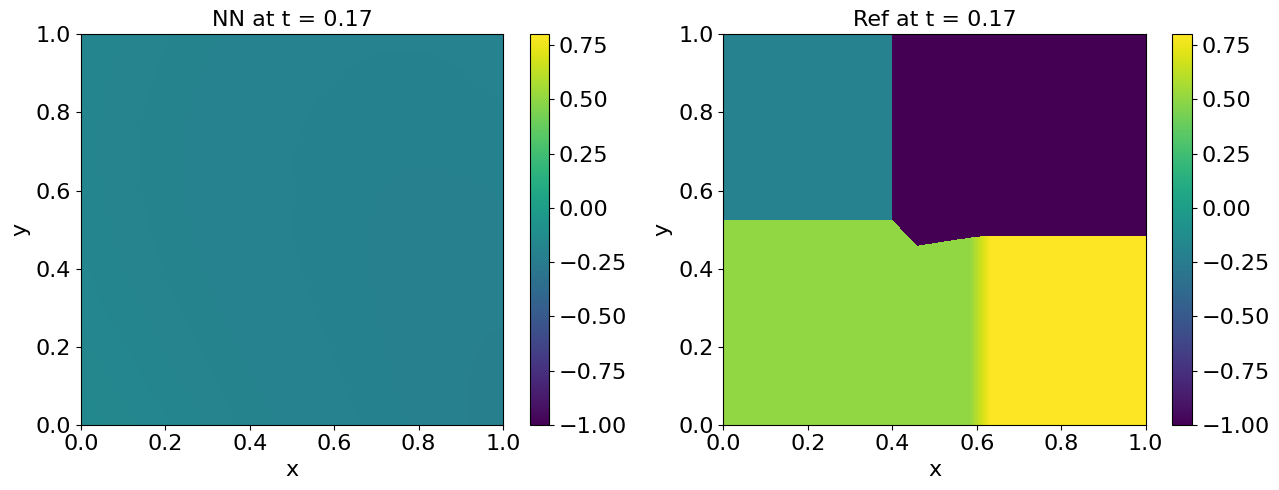

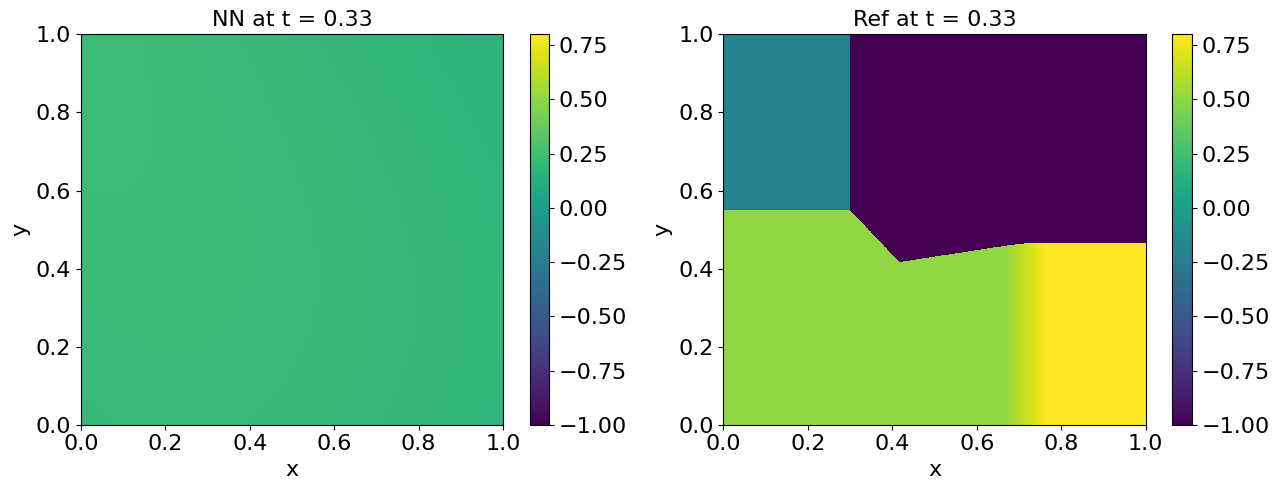

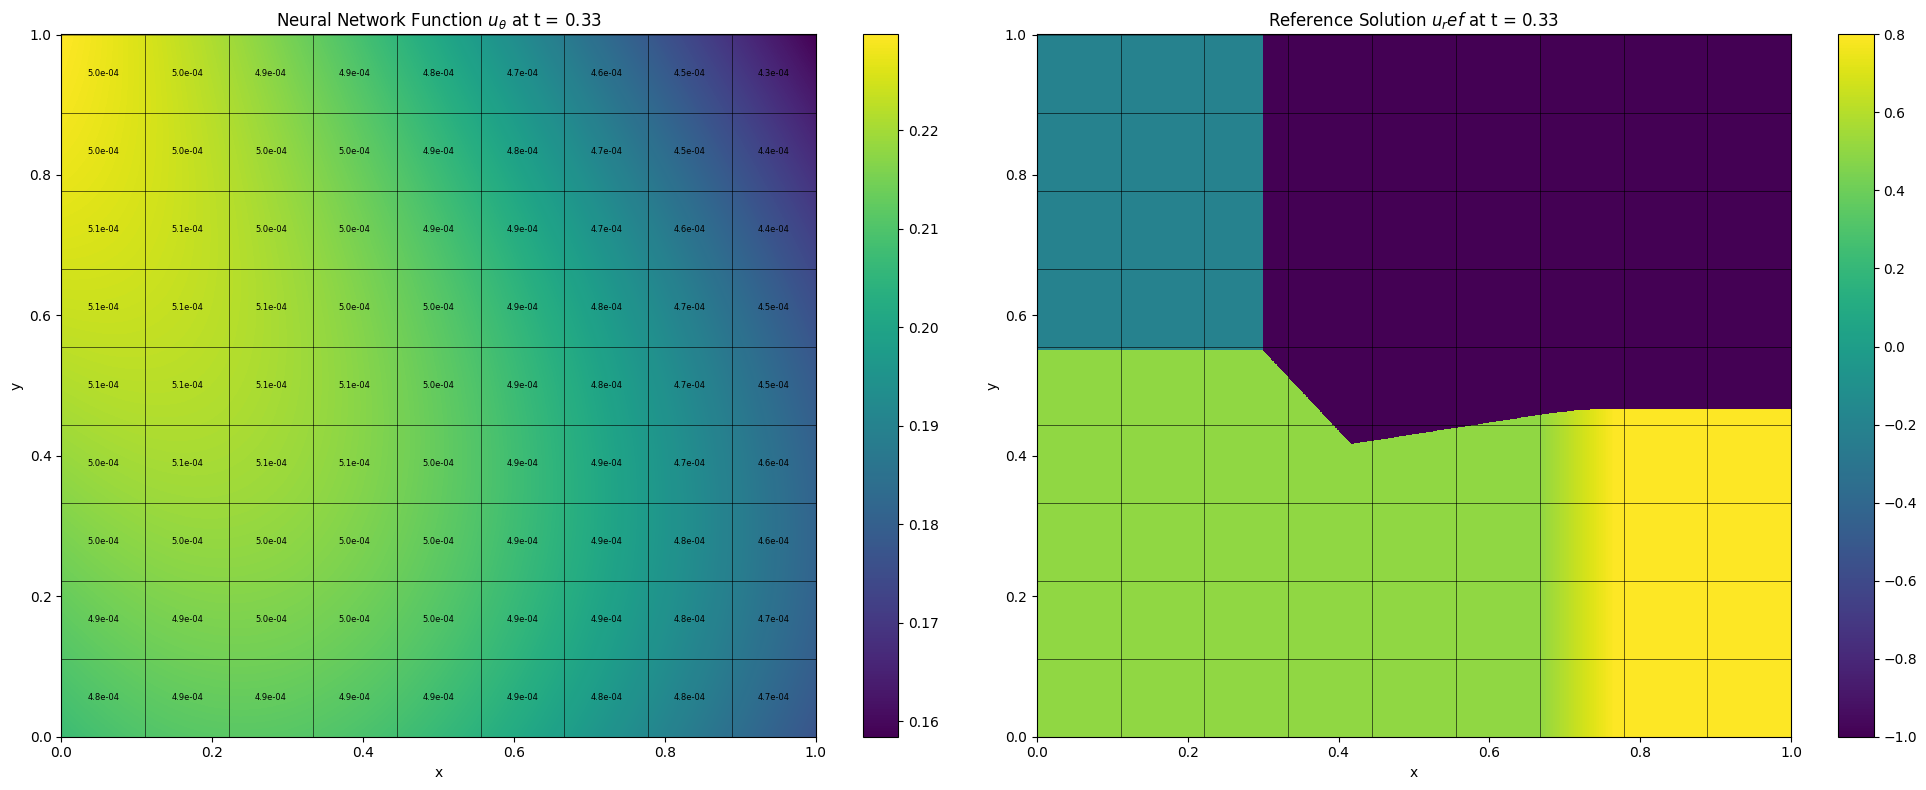

Updating importance sampling probabilities...
Grade 0, Iter 100, loss_eqn: 0.141057, loss_eqn_from_kh: 0.141057 loss_l1: 0.141057, loss_ibc: 0.445182
Updating importance sampling probabilities...
Grade 0, Iter 200, loss_eqn: 0.172408, loss_eqn_from_kh: 0.172408 loss_l1: 0.172408, loss_ibc: 0.119885
Updating importance sampling probabilities...
Grade 0, Iter 300, loss_eqn: 0.141279, loss_eqn_from_kh: 0.141278 loss_l1: 0.141278, loss_ibc: 0.054369
Updating importance sampling probabilities...
Grade 0, Iter 400, loss_eqn: 0.128612, loss_eqn_from_kh: 0.128612 loss_l1: 0.128612, loss_ibc: 0.029314
Updating importance sampling probabilities...
Grade 0, Iter 500, loss_eqn: 0.114655, loss_eqn_from_kh: 0.114655 loss_l1: 0.114655, loss_ibc: 0.018824
Updating importance sampling probabilities...
Grade 0, Iter 600, loss_eqn: 0.097661, loss_eqn_from_kh: 0.097661 loss_l1: 0.097661, loss_ibc: 0.012878
Updating importance sampling probabilities...
Grade 0, Iter 700, loss_eqn: 0.086324, loss_eqn_from_k

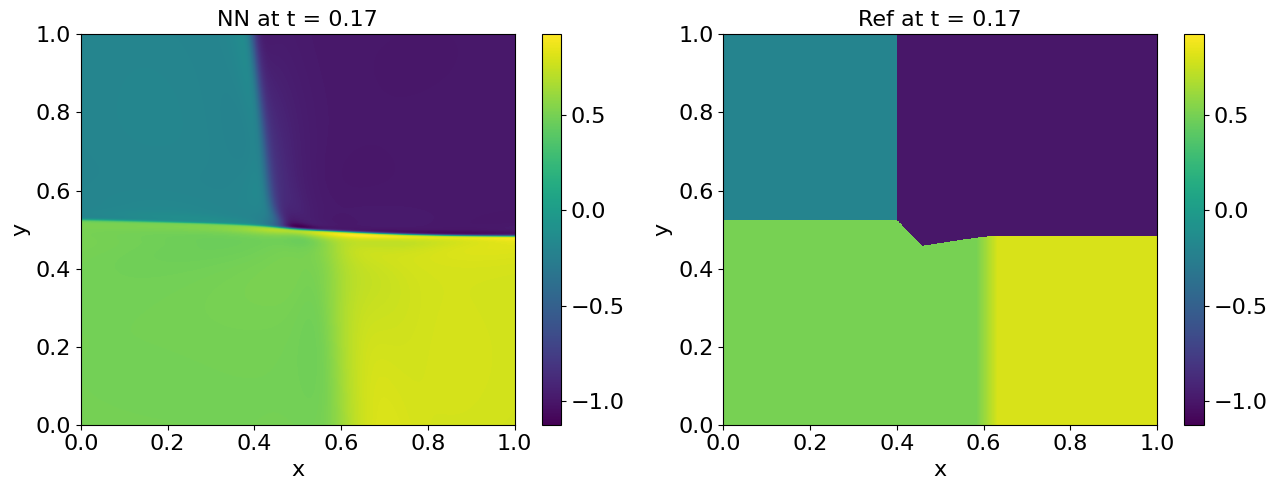

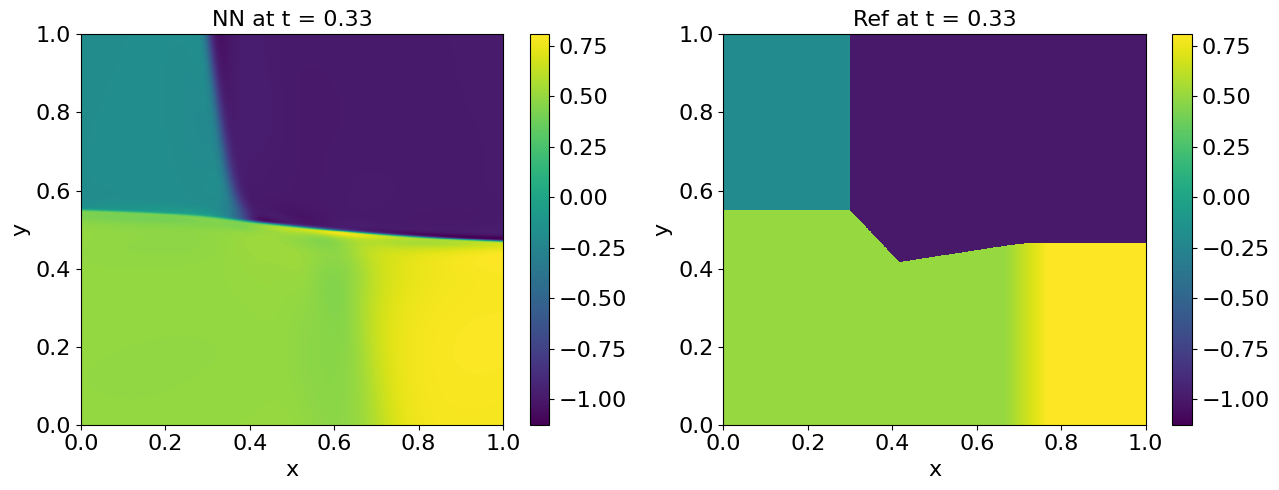

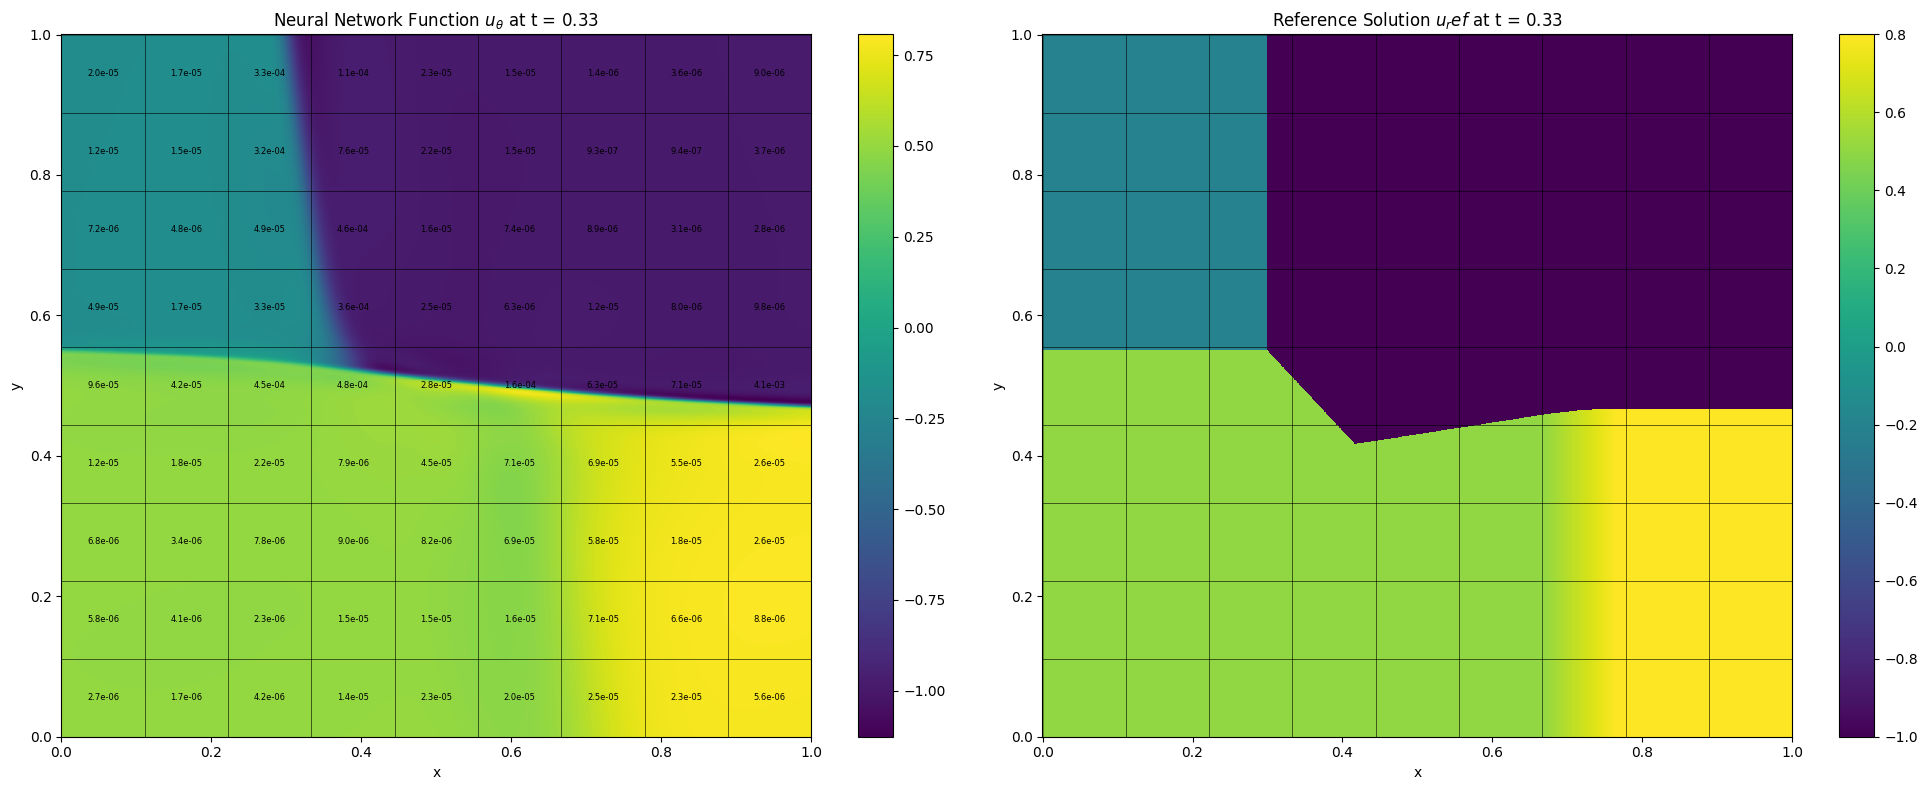

Updating importance sampling probabilities...
Grade 0, Iter 1100, loss_eqn: 0.045830, loss_eqn_from_kh: 0.045830 loss_l1: 0.045830, loss_ibc: 0.005099
Updating importance sampling probabilities...
Grade 0, Iter 1200, loss_eqn: 0.041338, loss_eqn_from_kh: 0.041338 loss_l1: 0.041338, loss_ibc: 0.003927
Updating importance sampling probabilities...
Grade 0, Iter 1300, loss_eqn: 0.036360, loss_eqn_from_kh: 0.036360 loss_l1: 0.036360, loss_ibc: 0.003319
Updating importance sampling probabilities...
Grade 0, Iter 1400, loss_eqn: 0.033122, loss_eqn_from_kh: 0.033122 loss_l1: 0.033122, loss_ibc: 0.002935
Updating importance sampling probabilities...
Grade 0, Iter 1500, loss_eqn: 0.033770, loss_eqn_from_kh: 0.033770 loss_l1: 0.033770, loss_ibc: 0.002938
Updating importance sampling probabilities...
Grade 0, Iter 1600, loss_eqn: 0.030241, loss_eqn_from_kh: 0.030241 loss_l1: 0.030241, loss_ibc: 0.002878
Updating importance sampling probabilities...
Grade 0, Iter 1700, loss_eqn: 0.029321, loss_eqn

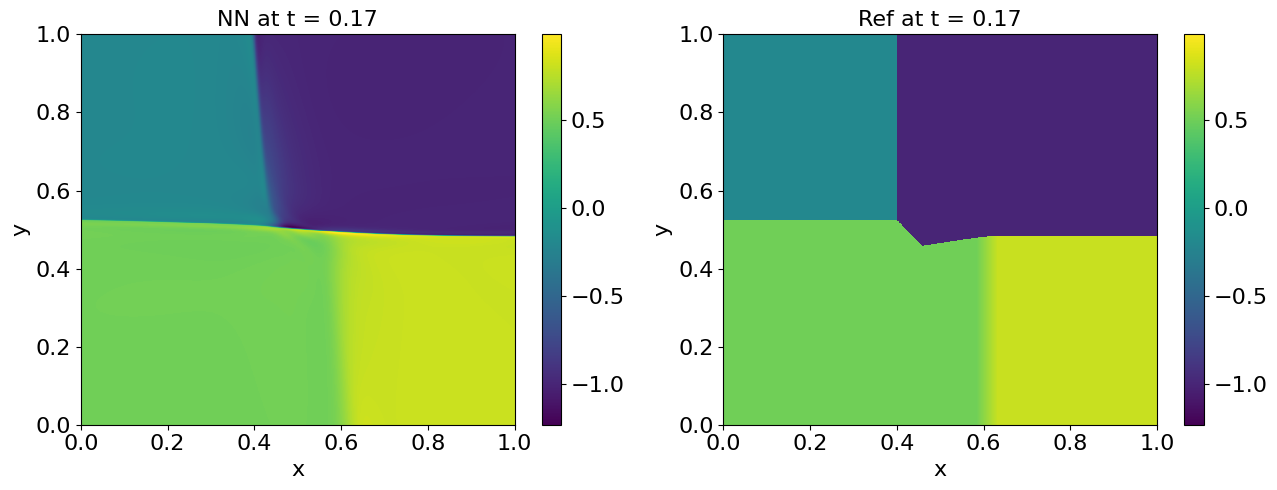

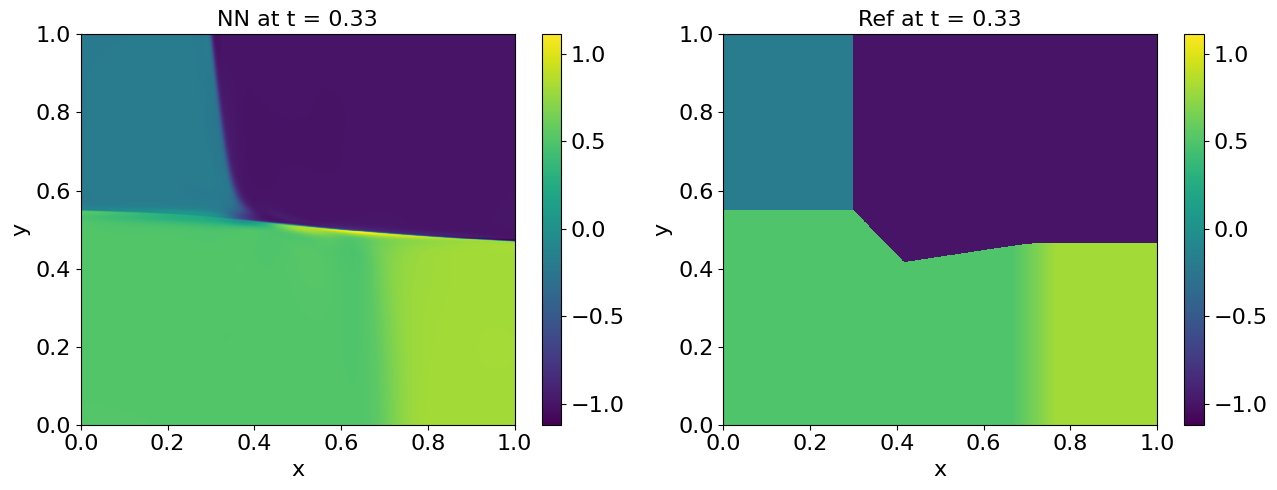

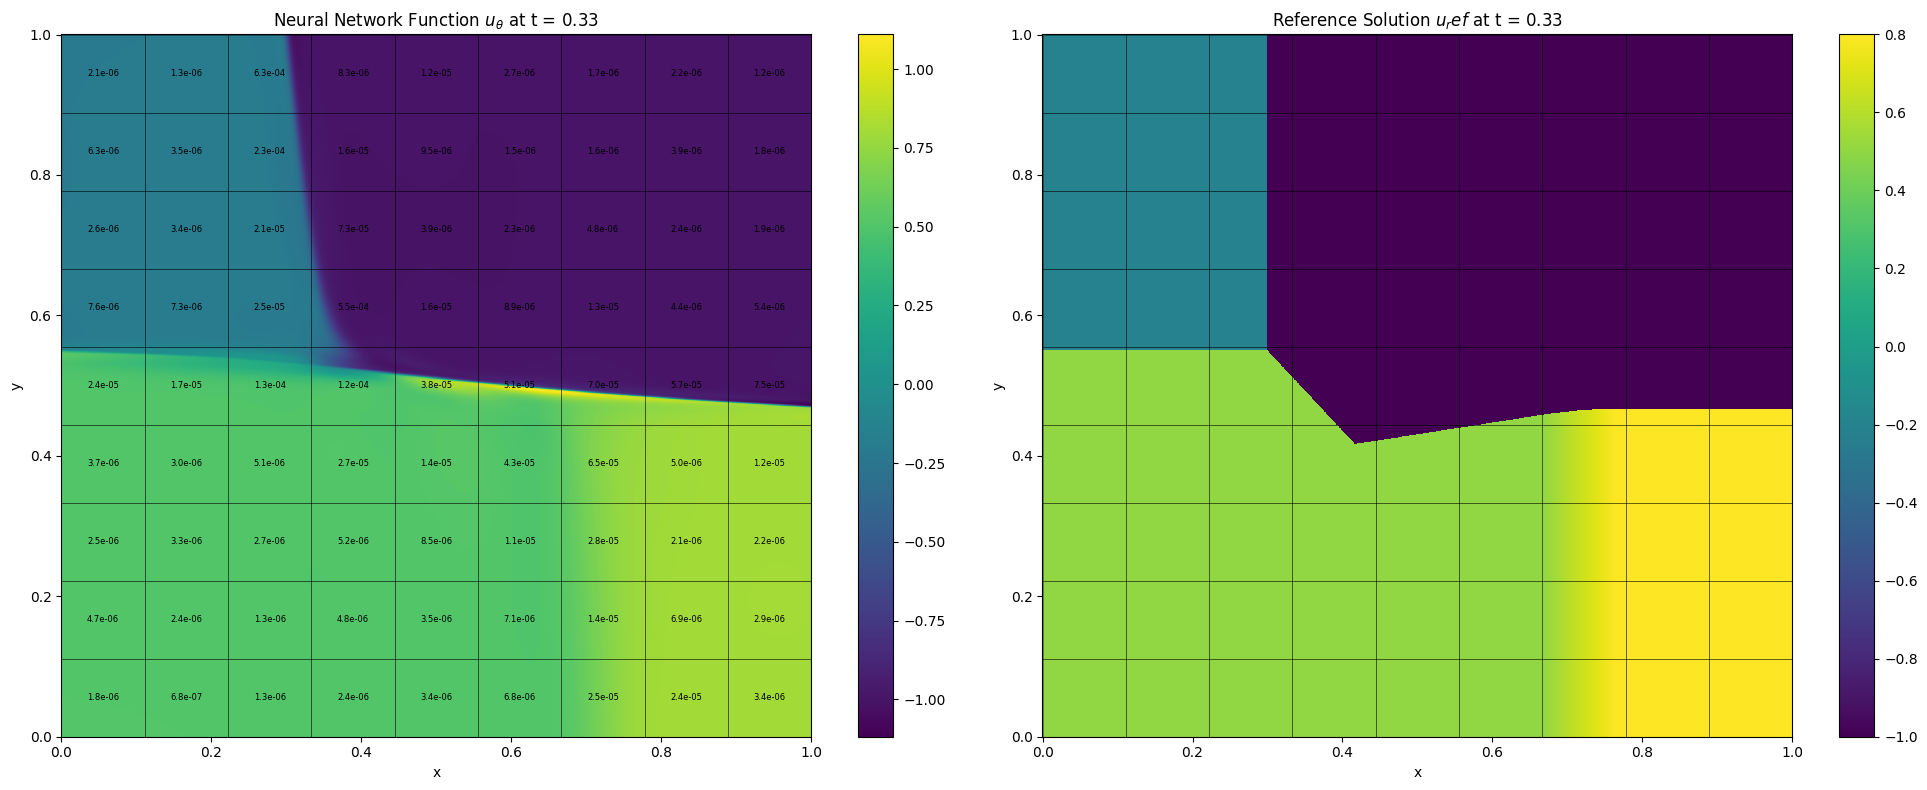

Updating importance sampling probabilities...
Grade 0, Iter 2100, loss_eqn: 0.024475, loss_eqn_from_kh: 0.024475 loss_l1: 0.024475, loss_ibc: 0.001767
Updating importance sampling probabilities...
Grade 0, Iter 2200, loss_eqn: 0.023326, loss_eqn_from_kh: 0.023326 loss_l1: 0.023326, loss_ibc: 0.001775
Updating importance sampling probabilities...
Grade 0, Iter 2300, loss_eqn: 0.023533, loss_eqn_from_kh: 0.023533 loss_l1: 0.023533, loss_ibc: 0.002242
Updating importance sampling probabilities...
Grade 0, Iter 2400, loss_eqn: 0.021920, loss_eqn_from_kh: 0.021920 loss_l1: 0.021920, loss_ibc: 0.001752
Updating importance sampling probabilities...
Grade 0, Iter 2500, loss_eqn: 0.021587, loss_eqn_from_kh: 0.021587 loss_l1: 0.021587, loss_ibc: 0.001604
Updating importance sampling probabilities...
Grade 0, Iter 2600, loss_eqn: 0.021243, loss_eqn_from_kh: 0.021243 loss_l1: 0.021243, loss_ibc: 0.001525
Updating importance sampling probabilities...
Grade 0, Iter 2700, loss_eqn: 0.021646, loss_eqn

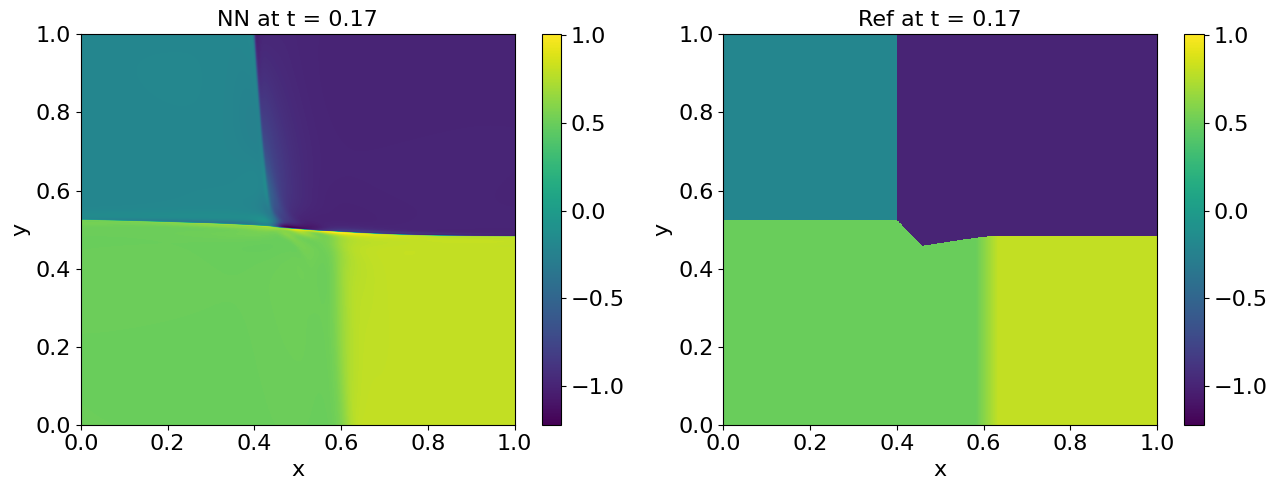

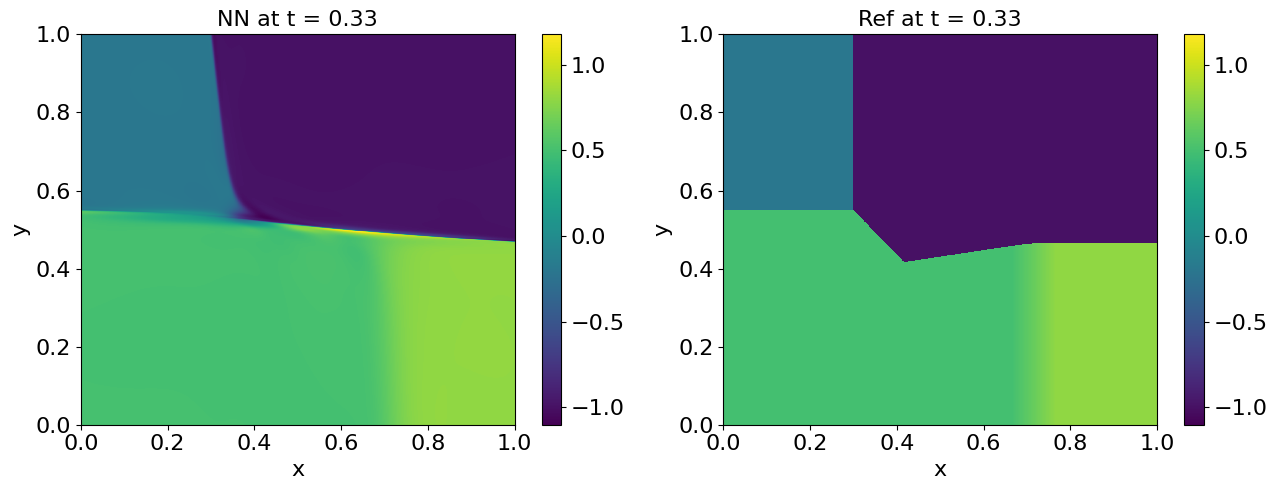

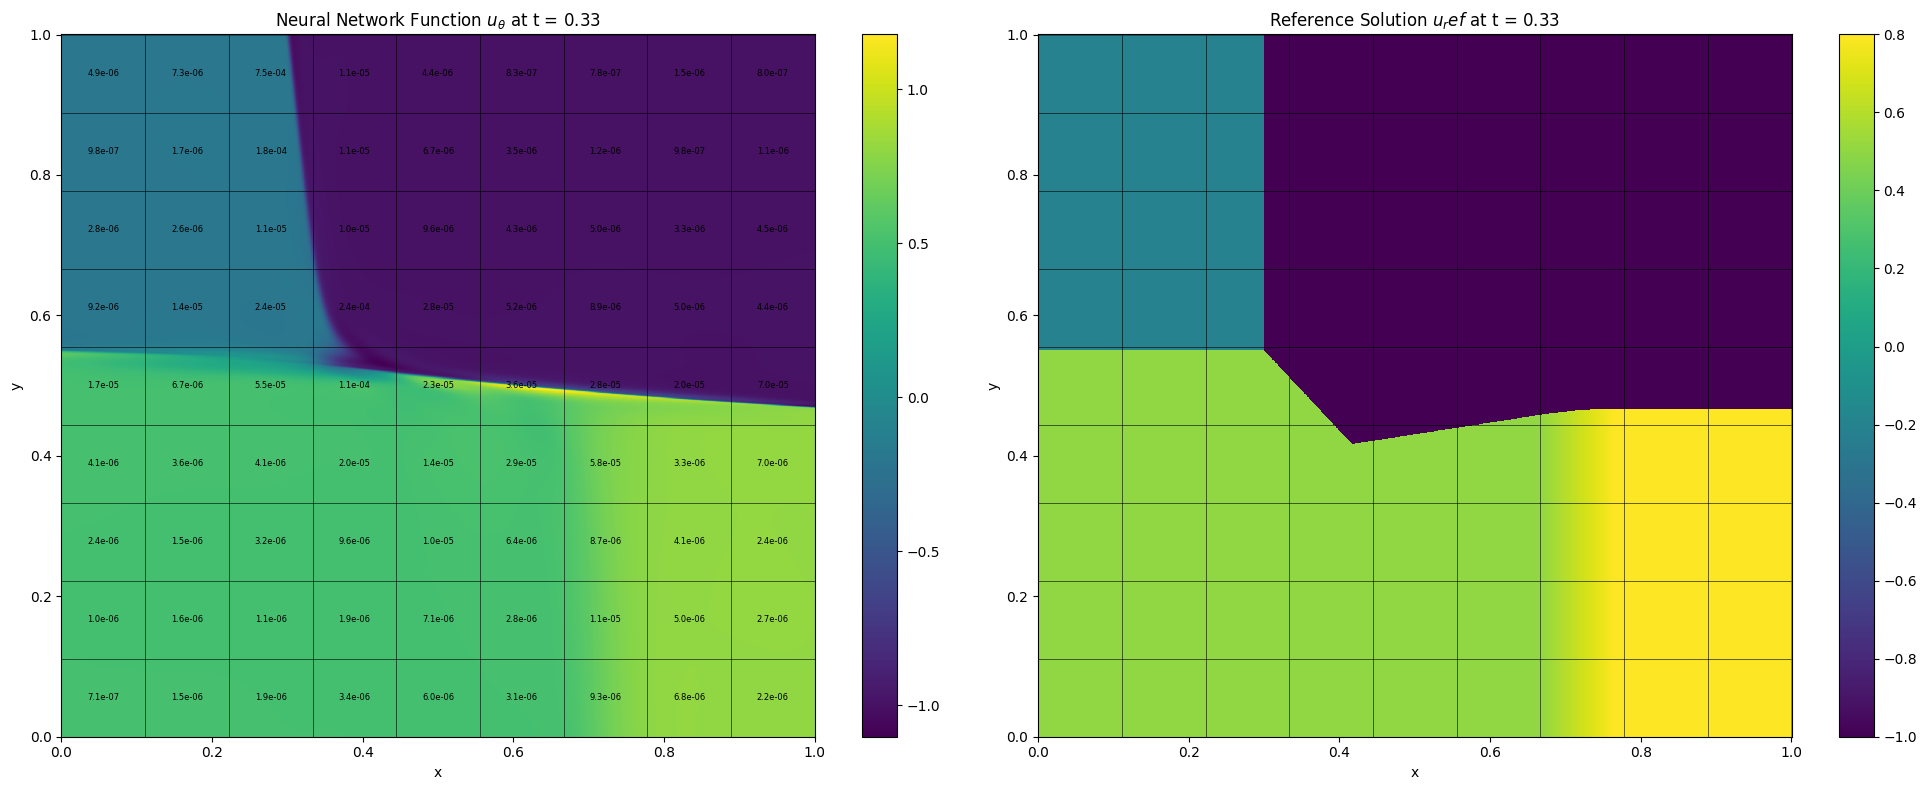

Updating importance sampling probabilities...
Grade 0, Iter 3100, loss_eqn: 0.018949, loss_eqn_from_kh: 0.018949 loss_l1: 0.018949, loss_ibc: 0.001268
Updating importance sampling probabilities...
Grade 0, Iter 3200, loss_eqn: 0.020436, loss_eqn_from_kh: 0.020436 loss_l1: 0.020436, loss_ibc: 0.001464
Updating importance sampling probabilities...
Grade 0, Iter 3300, loss_eqn: 0.018301, loss_eqn_from_kh: 0.018301 loss_l1: 0.018301, loss_ibc: 0.001288
Updating importance sampling probabilities...
Grade 0, Iter 3400, loss_eqn: 0.020334, loss_eqn_from_kh: 0.020334 loss_l1: 0.020334, loss_ibc: 0.001252
Updating importance sampling probabilities...
Grade 0, Iter 3500, loss_eqn: 0.016449, loss_eqn_from_kh: 0.016449 loss_l1: 0.016449, loss_ibc: 0.001234
Updating importance sampling probabilities...
Grade 0, Iter 3600, loss_eqn: 0.016480, loss_eqn_from_kh: 0.016480 loss_l1: 0.016480, loss_ibc: 0.001073
Updating importance sampling probabilities...
Grade 0, Iter 3700, loss_eqn: 0.017193, loss_eqn

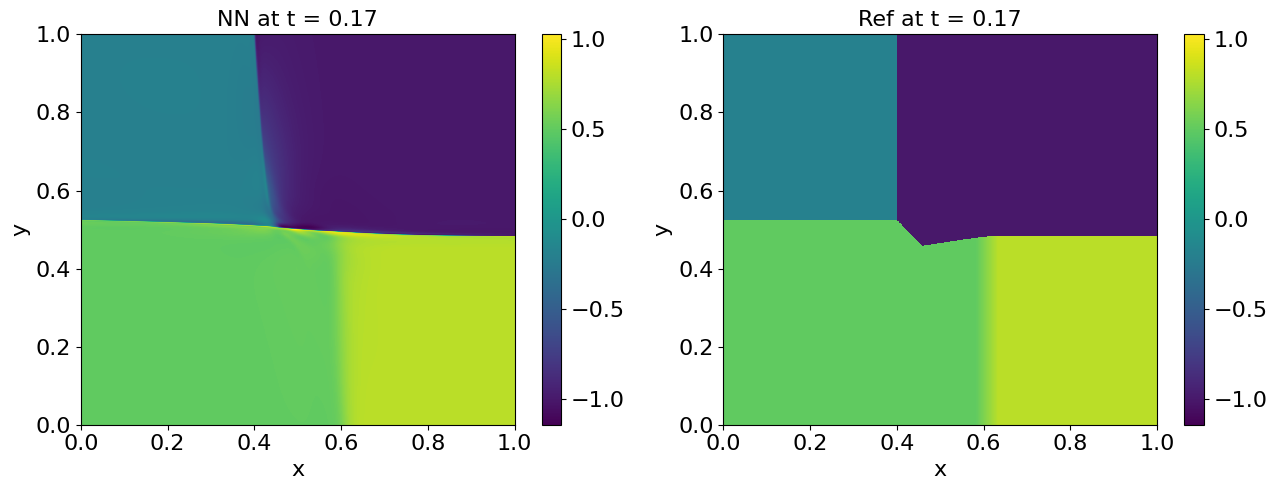

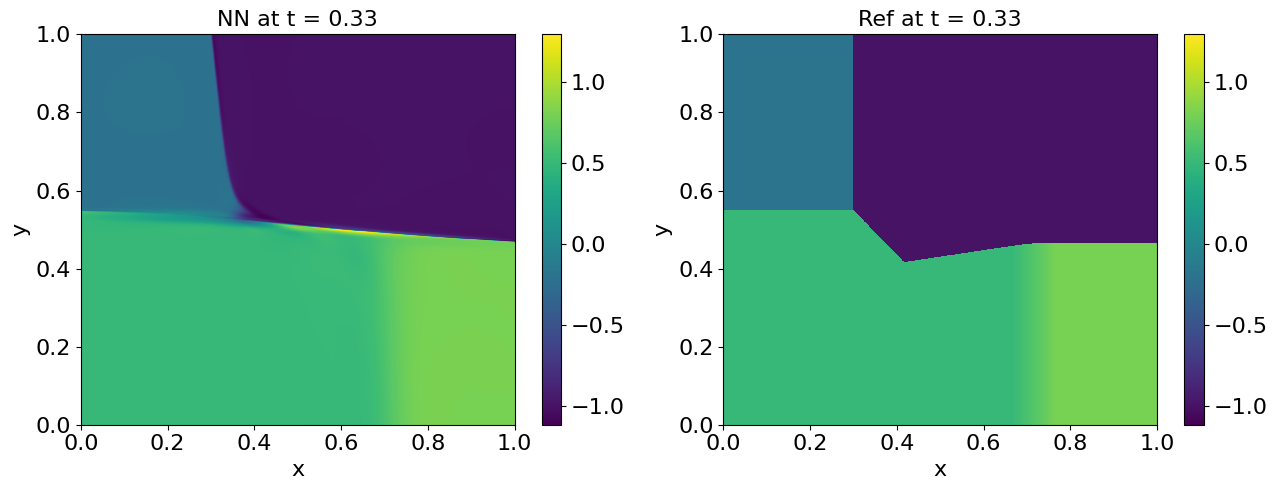

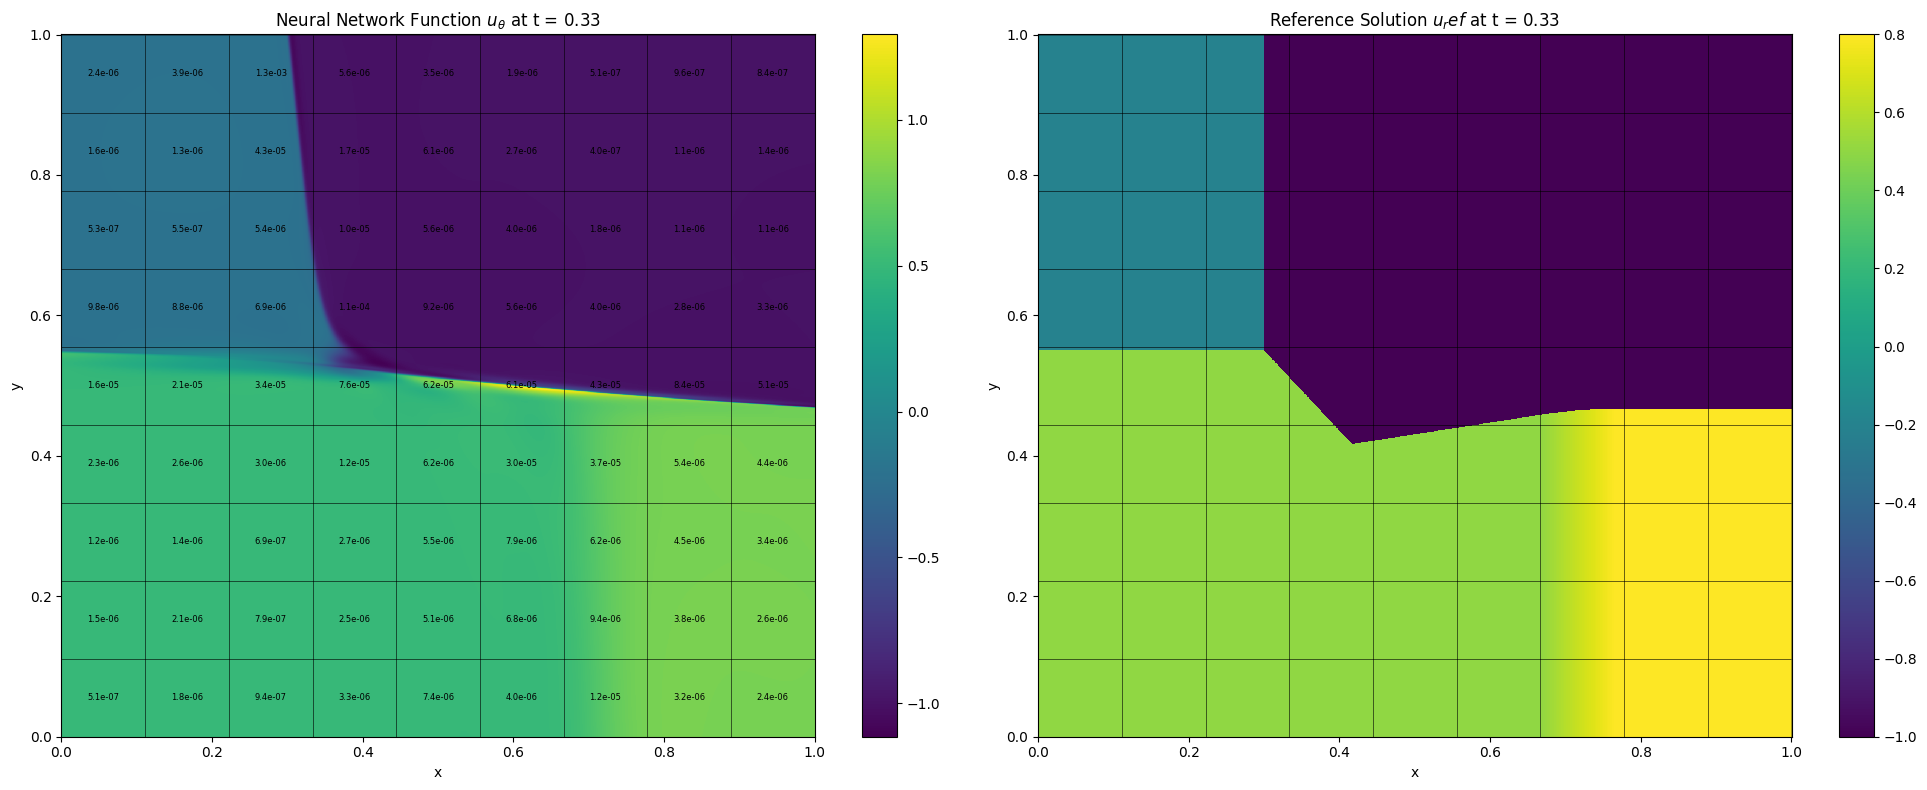

Updating importance sampling probabilities...
Grade 0, Iter 4100, loss_eqn: 0.016527, loss_eqn_from_kh: 0.016527 loss_l1: 0.016527, loss_ibc: 0.000992
Updating importance sampling probabilities...
Grade 0, Iter 4200, loss_eqn: 0.018460, loss_eqn_from_kh: 0.018460 loss_l1: 0.018460, loss_ibc: 0.000999
Updating importance sampling probabilities...
Grade 0, Iter 4300, loss_eqn: 0.016363, loss_eqn_from_kh: 0.016363 loss_l1: 0.016363, loss_ibc: 0.000900
Updating importance sampling probabilities...
Grade 0, Iter 4400, loss_eqn: 0.015950, loss_eqn_from_kh: 0.015950 loss_l1: 0.015950, loss_ibc: 0.001011
Updating importance sampling probabilities...
Grade 0, Iter 4500, loss_eqn: 0.016120, loss_eqn_from_kh: 0.016120 loss_l1: 0.016120, loss_ibc: 0.000961
Updating importance sampling probabilities...
Grade 0, Iter 4600, loss_eqn: 0.016875, loss_eqn_from_kh: 0.016874 loss_l1: 0.016874, loss_ibc: 0.001215
Updating importance sampling probabilities...
Grade 0, Iter 4700, loss_eqn: 0.013427, loss_eqn

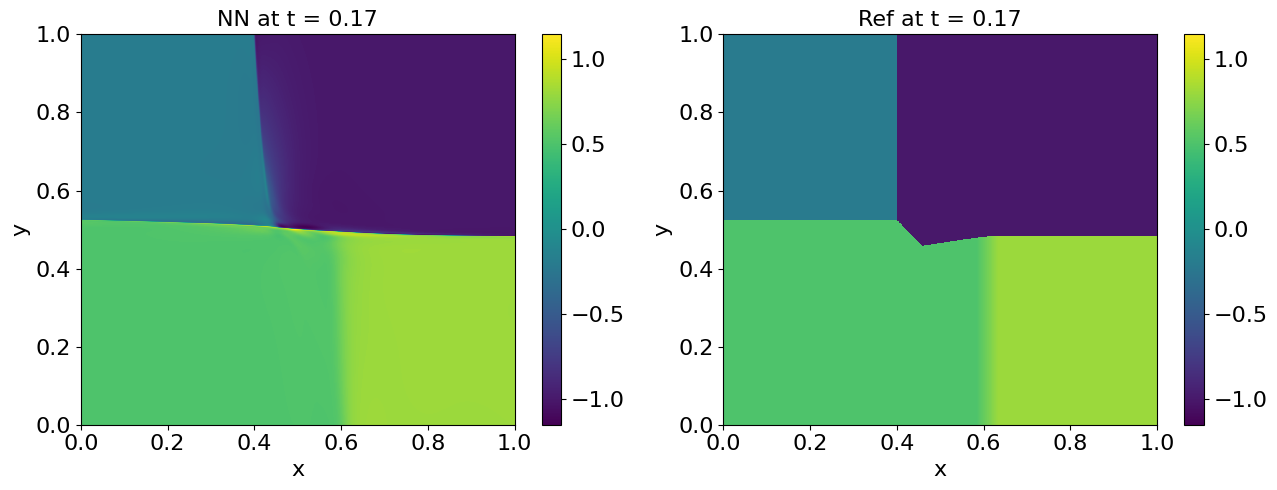

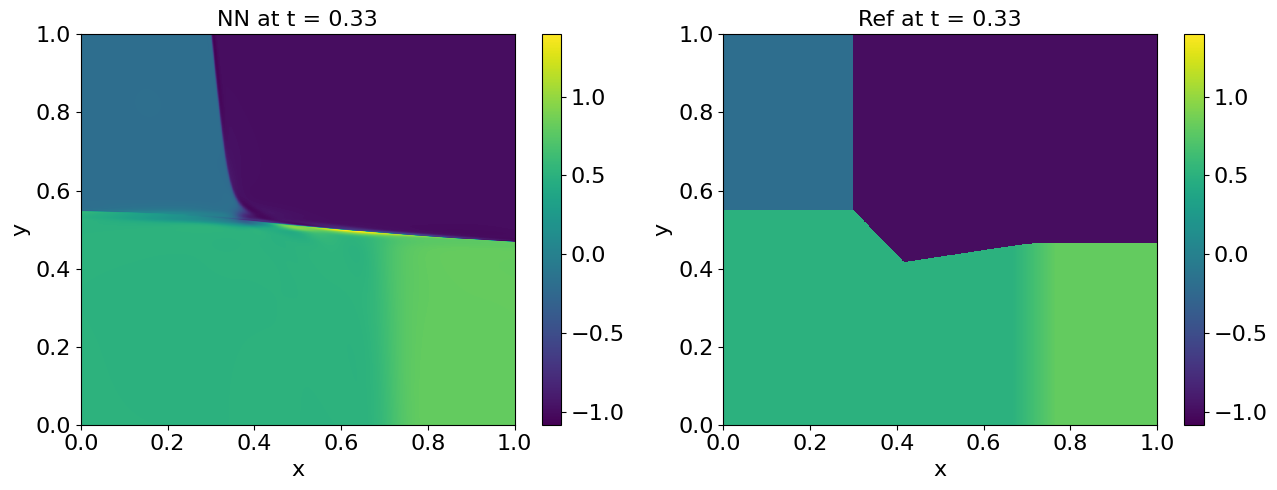

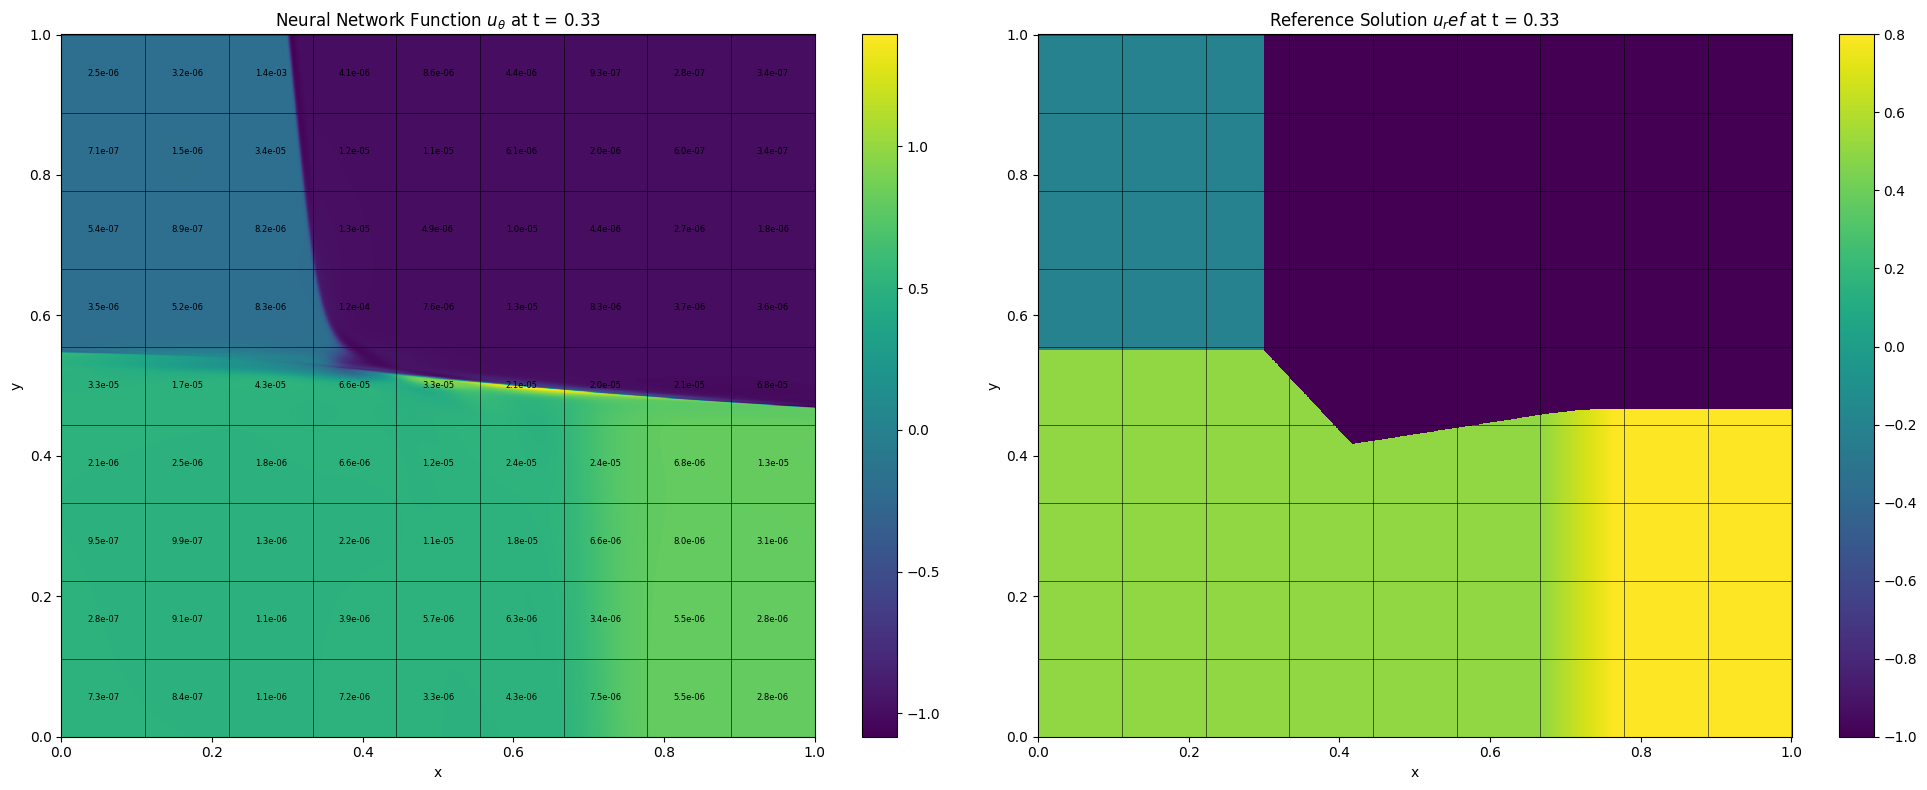

Updating importance sampling probabilities...
Grade 0, Iter 5100, loss_eqn: 0.013462, loss_eqn_from_kh: 0.013462 loss_l1: 0.013462, loss_ibc: 0.000849
Updating importance sampling probabilities...
Grade 0, Iter 5200, loss_eqn: 0.014278, loss_eqn_from_kh: 0.014278 loss_l1: 0.014278, loss_ibc: 0.001005
Updating importance sampling probabilities...
Grade 0, Iter 5300, loss_eqn: 0.014844, loss_eqn_from_kh: 0.014844 loss_l1: 0.014844, loss_ibc: 0.000828
Updating importance sampling probabilities...
Grade 0, Iter 5400, loss_eqn: 0.014455, loss_eqn_from_kh: 0.014455 loss_l1: 0.014455, loss_ibc: 0.001035
Updating importance sampling probabilities...
Grade 0, Iter 5500, loss_eqn: 0.015446, loss_eqn_from_kh: 0.015446 loss_l1: 0.015446, loss_ibc: 0.000899
Updating importance sampling probabilities...
Grade 0, Iter 5600, loss_eqn: 0.011260, loss_eqn_from_kh: 0.011260 loss_l1: 0.011260, loss_ibc: 0.000621
Updating importance sampling probabilities...
Grade 0, Iter 5700, loss_eqn: 0.010023, loss_eqn

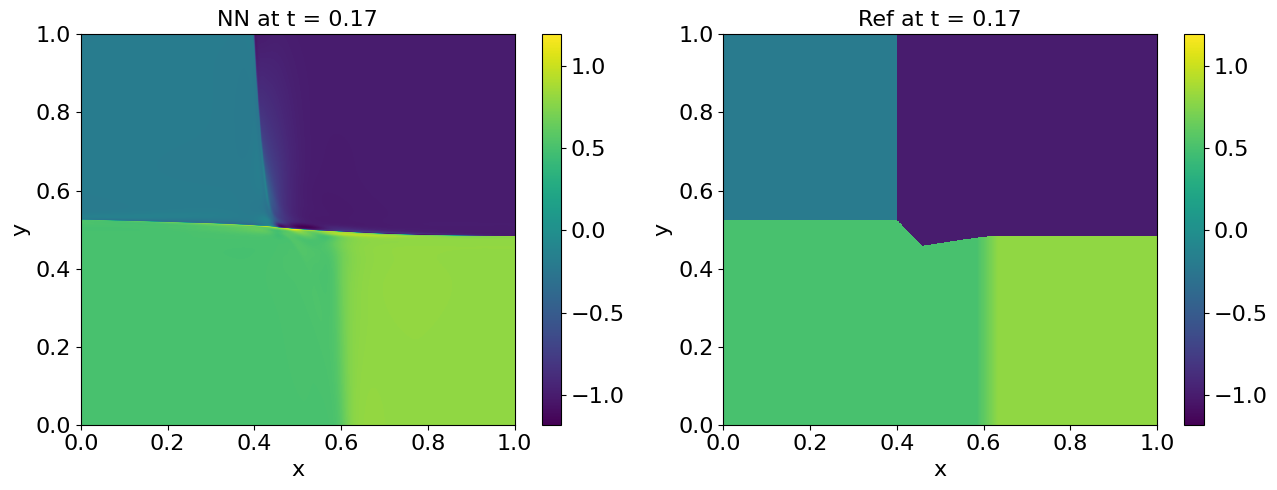

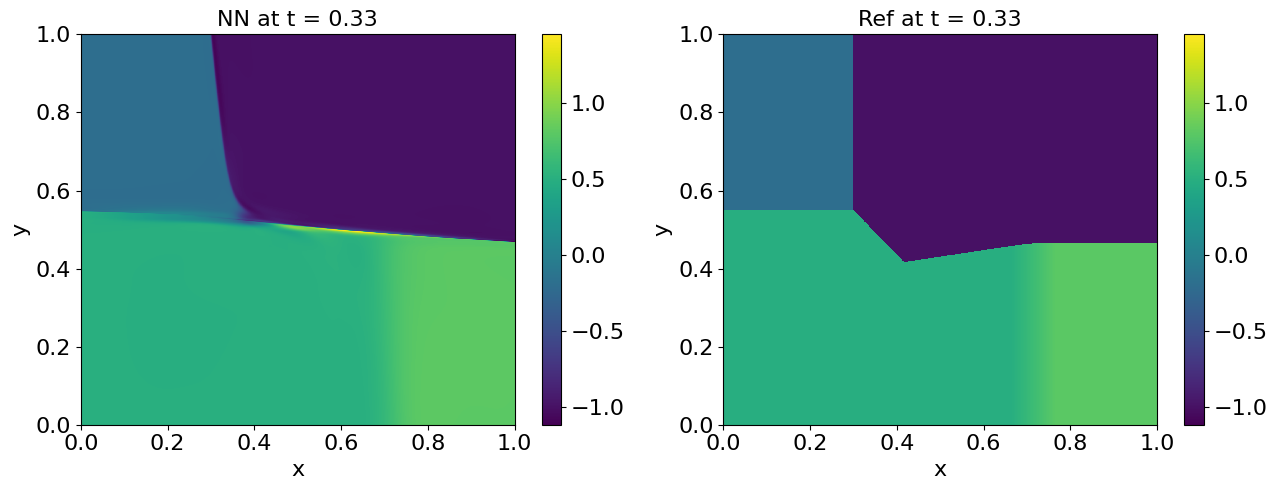

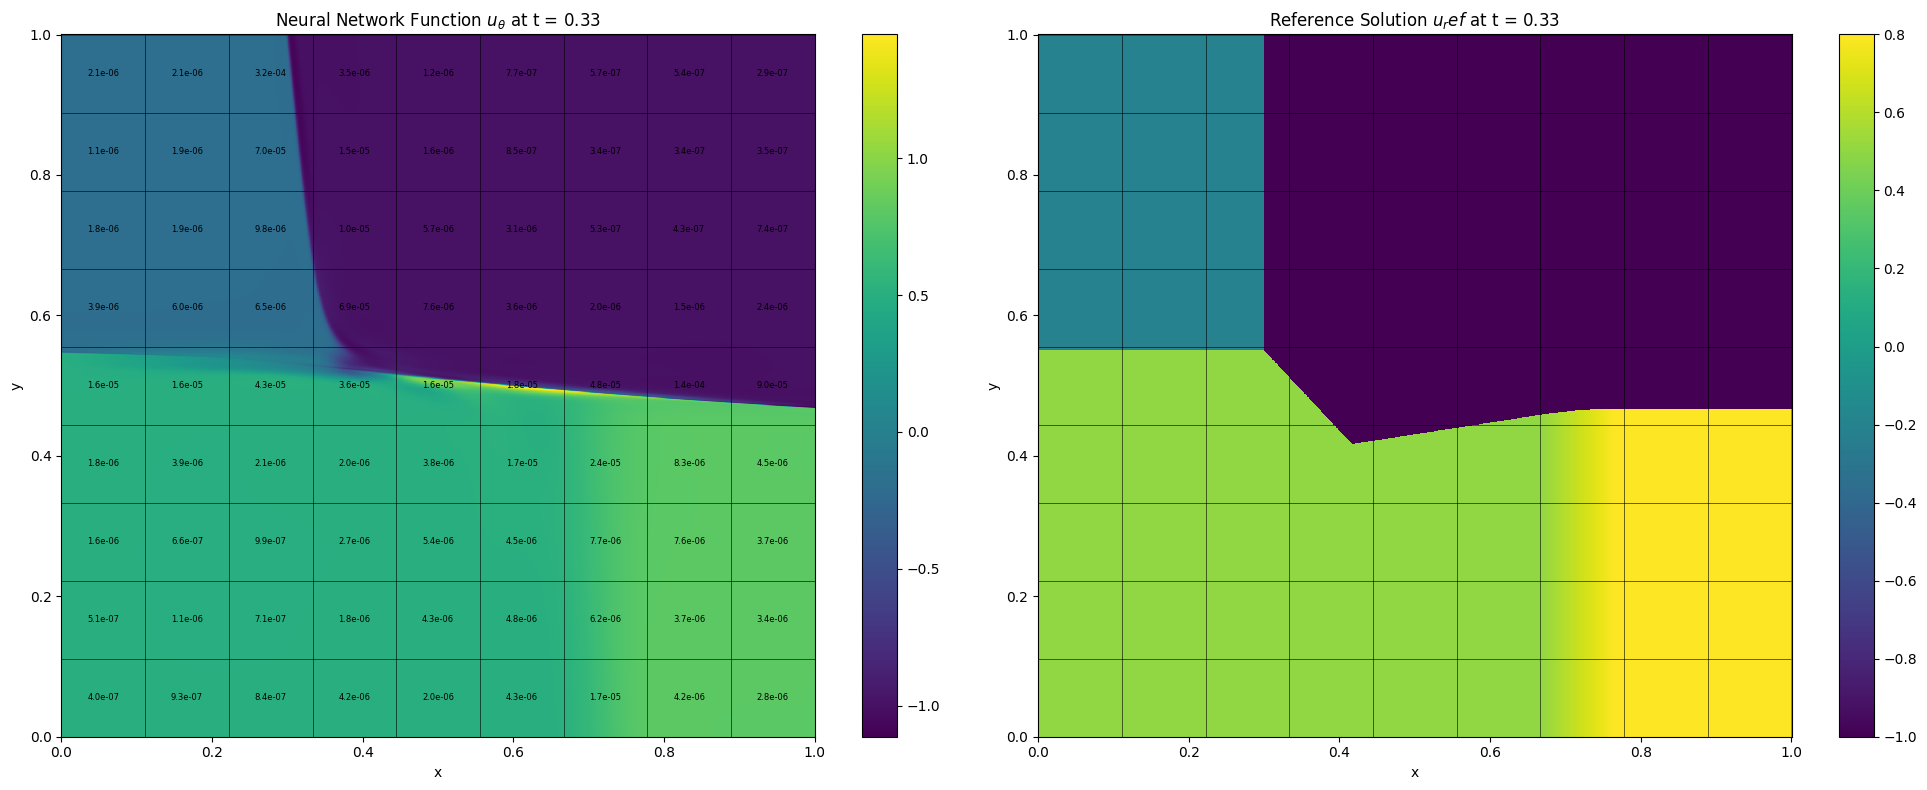

Updating importance sampling probabilities...
Grade 0, Iter 6100, loss_eqn: 0.011588, loss_eqn_from_kh: 0.011588 loss_l1: 0.011588, loss_ibc: 0.000783
Updating importance sampling probabilities...
Grade 0, Iter 6200, loss_eqn: 0.012813, loss_eqn_from_kh: 0.012813 loss_l1: 0.012813, loss_ibc: 0.000592
Updating importance sampling probabilities...
Grade 0, Iter 6300, loss_eqn: 0.013381, loss_eqn_from_kh: 0.013381 loss_l1: 0.013381, loss_ibc: 0.000644
Updating importance sampling probabilities...
Grade 0, Iter 6400, loss_eqn: 0.008016, loss_eqn_from_kh: 0.008016 loss_l1: 0.008016, loss_ibc: 0.000619
Updating importance sampling probabilities...
Grade 0, Iter 6500, loss_eqn: 0.011309, loss_eqn_from_kh: 0.011309 loss_l1: 0.011309, loss_ibc: 0.000718
Updating importance sampling probabilities...
Grade 0, Iter 6600, loss_eqn: 0.009089, loss_eqn_from_kh: 0.009089 loss_l1: 0.009089, loss_ibc: 0.000642
Updating importance sampling probabilities...
Grade 0, Iter 6700, loss_eqn: 0.009409, loss_eqn

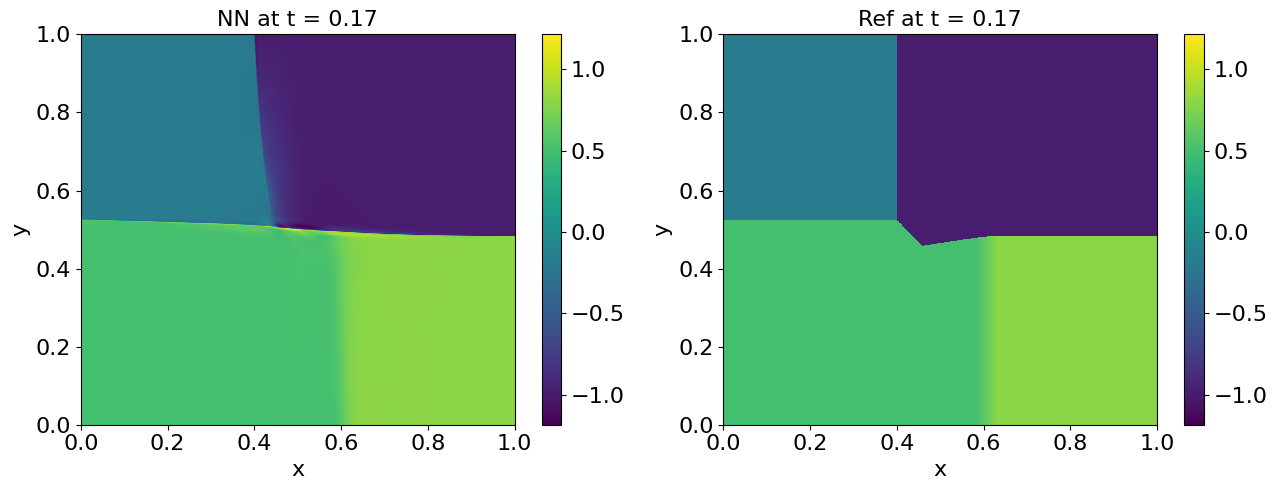

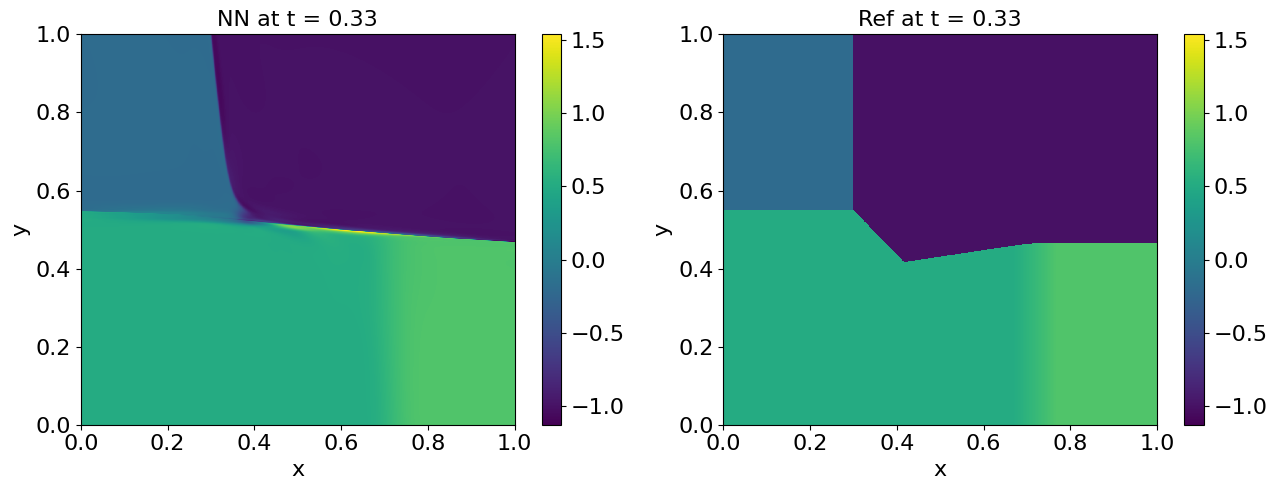

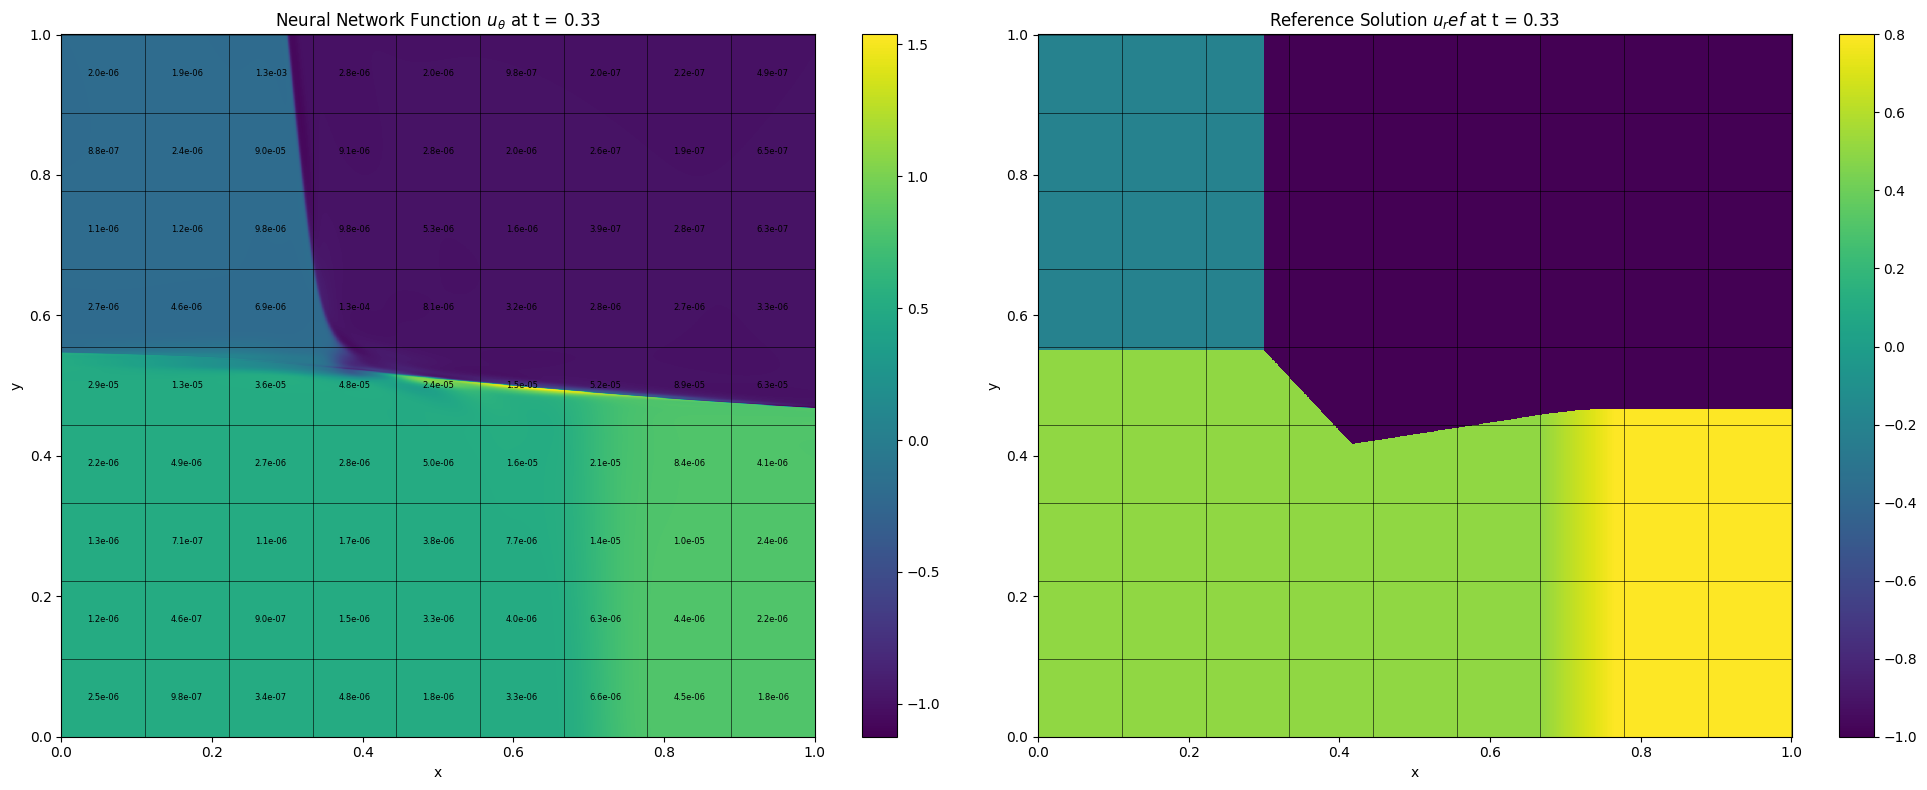

Updating importance sampling probabilities...
Grade 0, Iter 7100, loss_eqn: 0.008886, loss_eqn_from_kh: 0.008886 loss_l1: 0.008886, loss_ibc: 0.000502
Updating importance sampling probabilities...
Grade 0, Iter 7200, loss_eqn: 0.006753, loss_eqn_from_kh: 0.006753 loss_l1: 0.006753, loss_ibc: 0.000479
Updating importance sampling probabilities...
Grade 0, Iter 7300, loss_eqn: 0.007717, loss_eqn_from_kh: 0.007717 loss_l1: 0.007717, loss_ibc: 0.000498
Updating importance sampling probabilities...
Grade 0, Iter 7400, loss_eqn: 0.007599, loss_eqn_from_kh: 0.007599 loss_l1: 0.007599, loss_ibc: 0.000450
Updating importance sampling probabilities...
Grade 0, Iter 7500, loss_eqn: 0.005910, loss_eqn_from_kh: 0.005910 loss_l1: 0.005910, loss_ibc: 0.000434
Updating importance sampling probabilities...
Grade 0, Iter 7600, loss_eqn: 0.006503, loss_eqn_from_kh: 0.006503 loss_l1: 0.006503, loss_ibc: 0.000441
Updating importance sampling probabilities...
Grade 0, Iter 7700, loss_eqn: 0.005594, loss_eqn

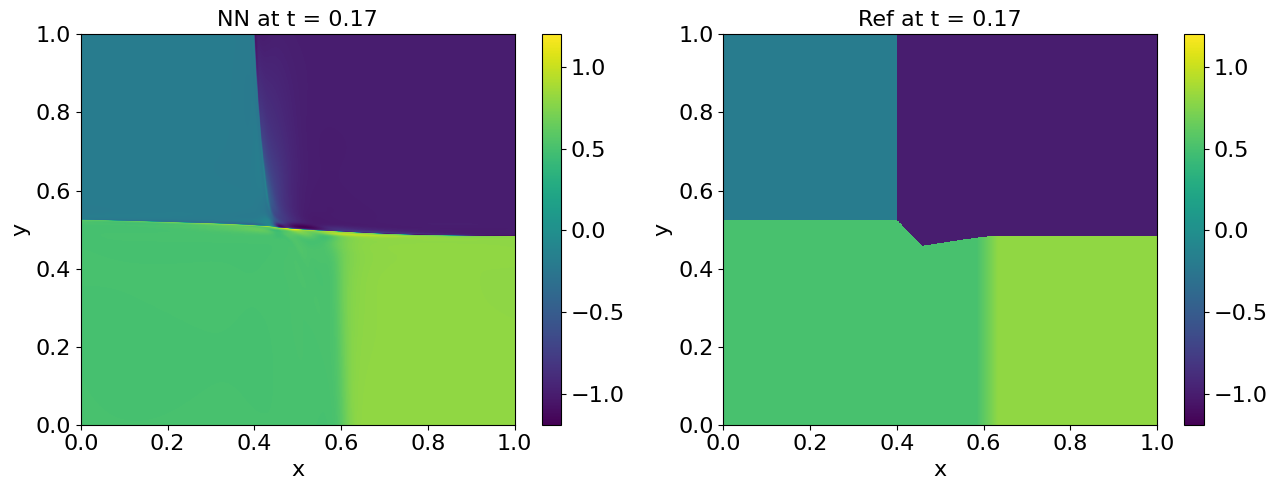

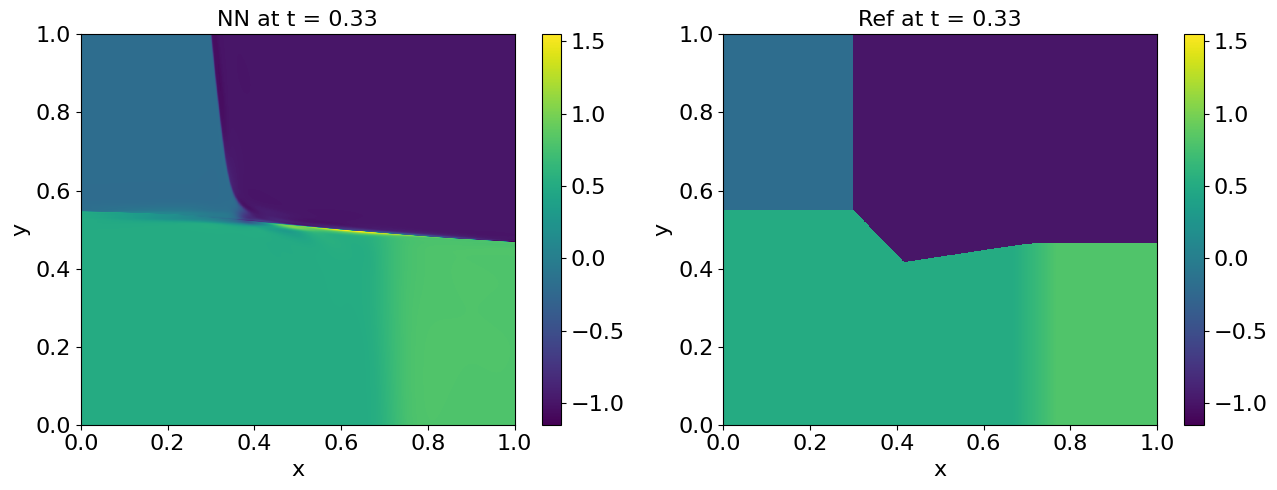

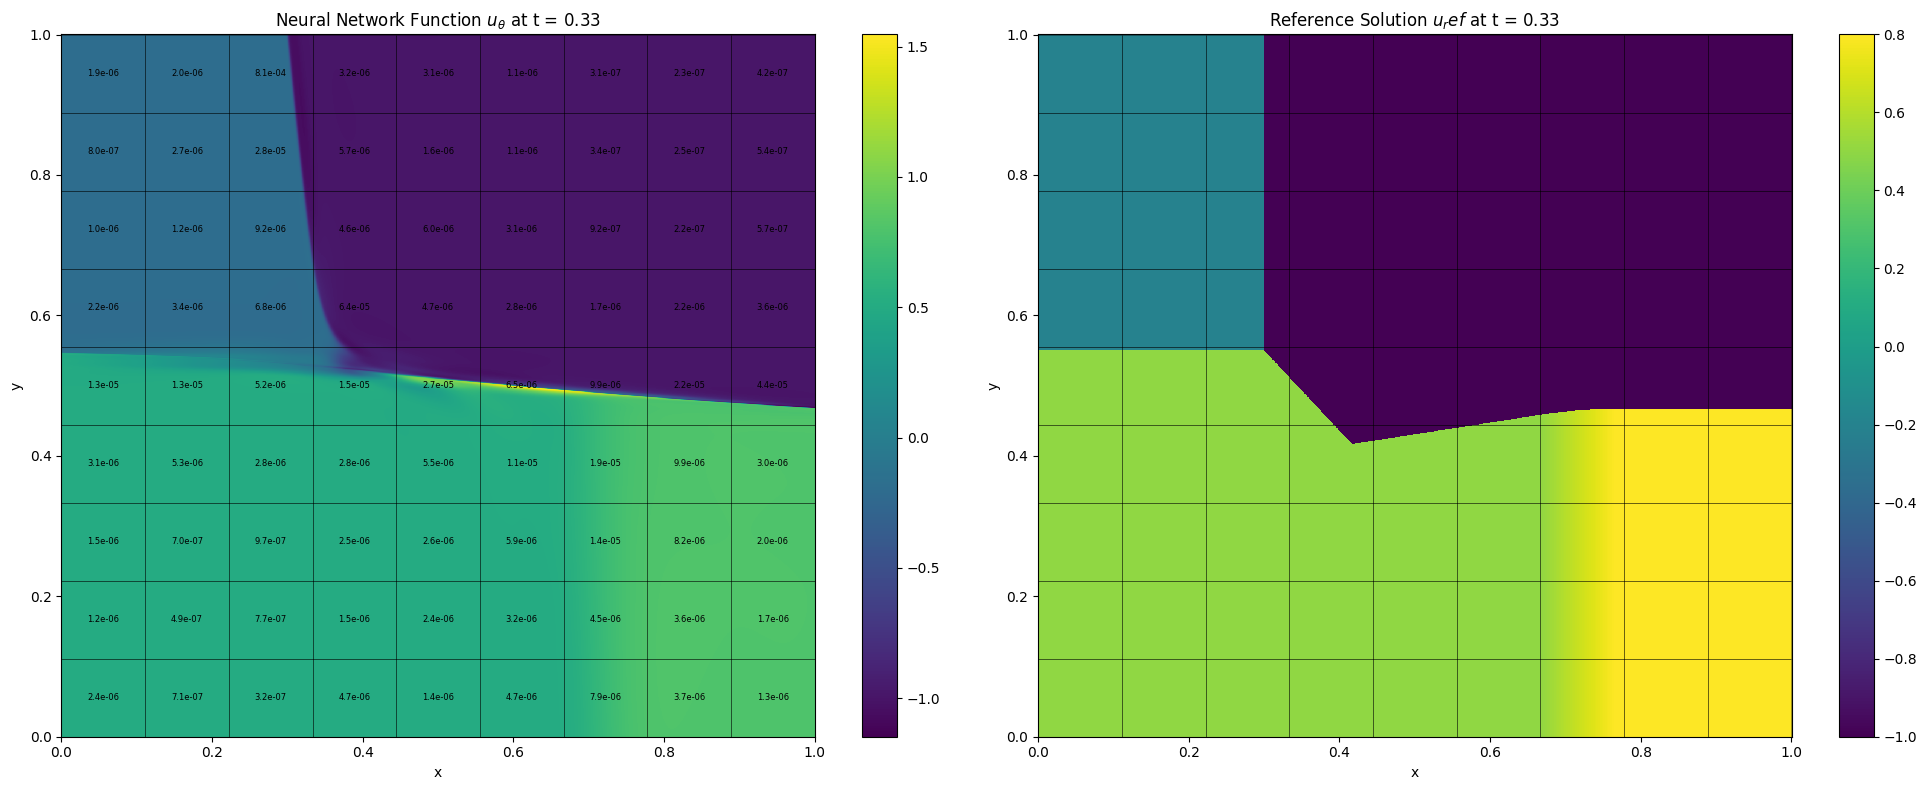

Updating importance sampling probabilities...
Grade 0, Iter 8100, loss_eqn: 0.006086, loss_eqn_from_kh: 0.006086 loss_l1: 0.006086, loss_ibc: 0.000388
Updating importance sampling probabilities...
Grade 0, Iter 8200, loss_eqn: 0.005848, loss_eqn_from_kh: 0.005848 loss_l1: 0.005848, loss_ibc: 0.000380
Updating importance sampling probabilities...
Grade 0, Iter 8300, loss_eqn: 0.005585, loss_eqn_from_kh: 0.005585 loss_l1: 0.005585, loss_ibc: 0.000393
Updating importance sampling probabilities...
Grade 0, Iter 8400, loss_eqn: 0.005672, loss_eqn_from_kh: 0.005672 loss_l1: 0.005672, loss_ibc: 0.000396
Updating importance sampling probabilities...
Grade 0, Iter 8500, loss_eqn: 0.005365, loss_eqn_from_kh: 0.005365 loss_l1: 0.005365, loss_ibc: 0.000372
Updating importance sampling probabilities...
Grade 0, Iter 8600, loss_eqn: 0.006196, loss_eqn_from_kh: 0.006196 loss_l1: 0.006196, loss_ibc: 0.000367
Updating importance sampling probabilities...
Grade 0, Iter 8700, loss_eqn: 0.004282, loss_eqn

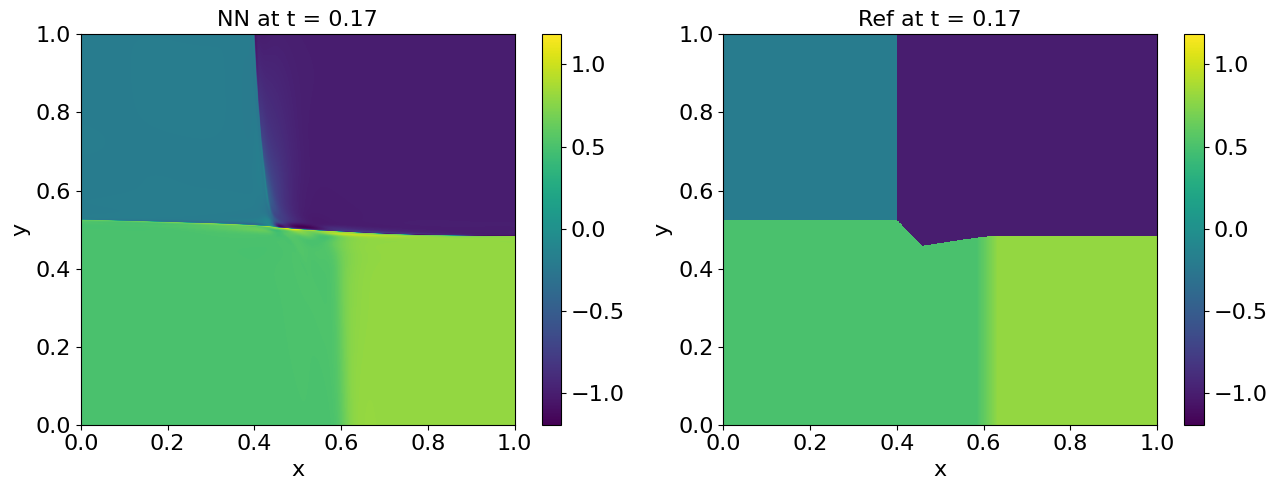

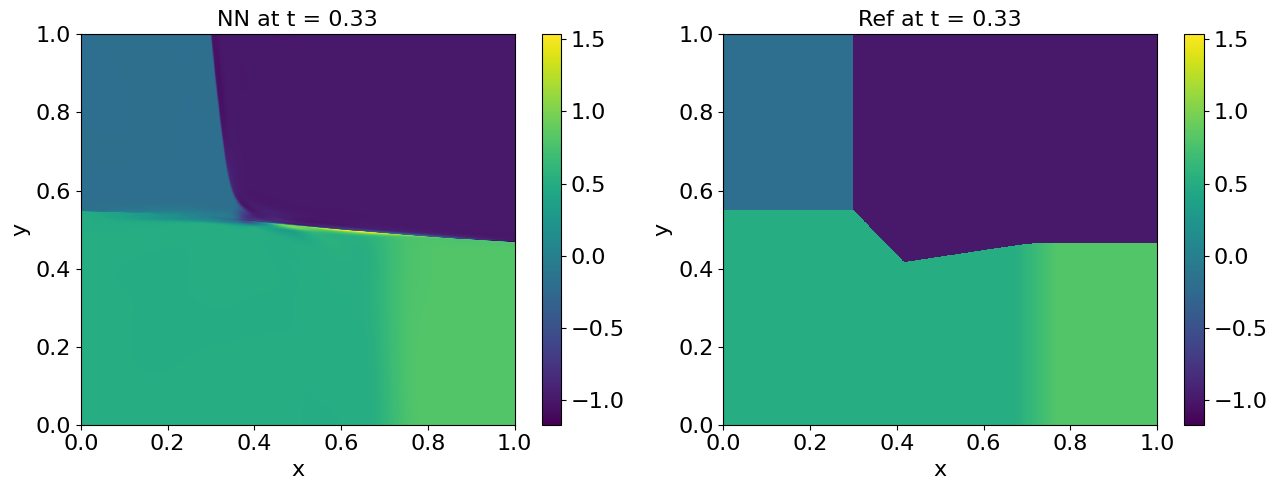

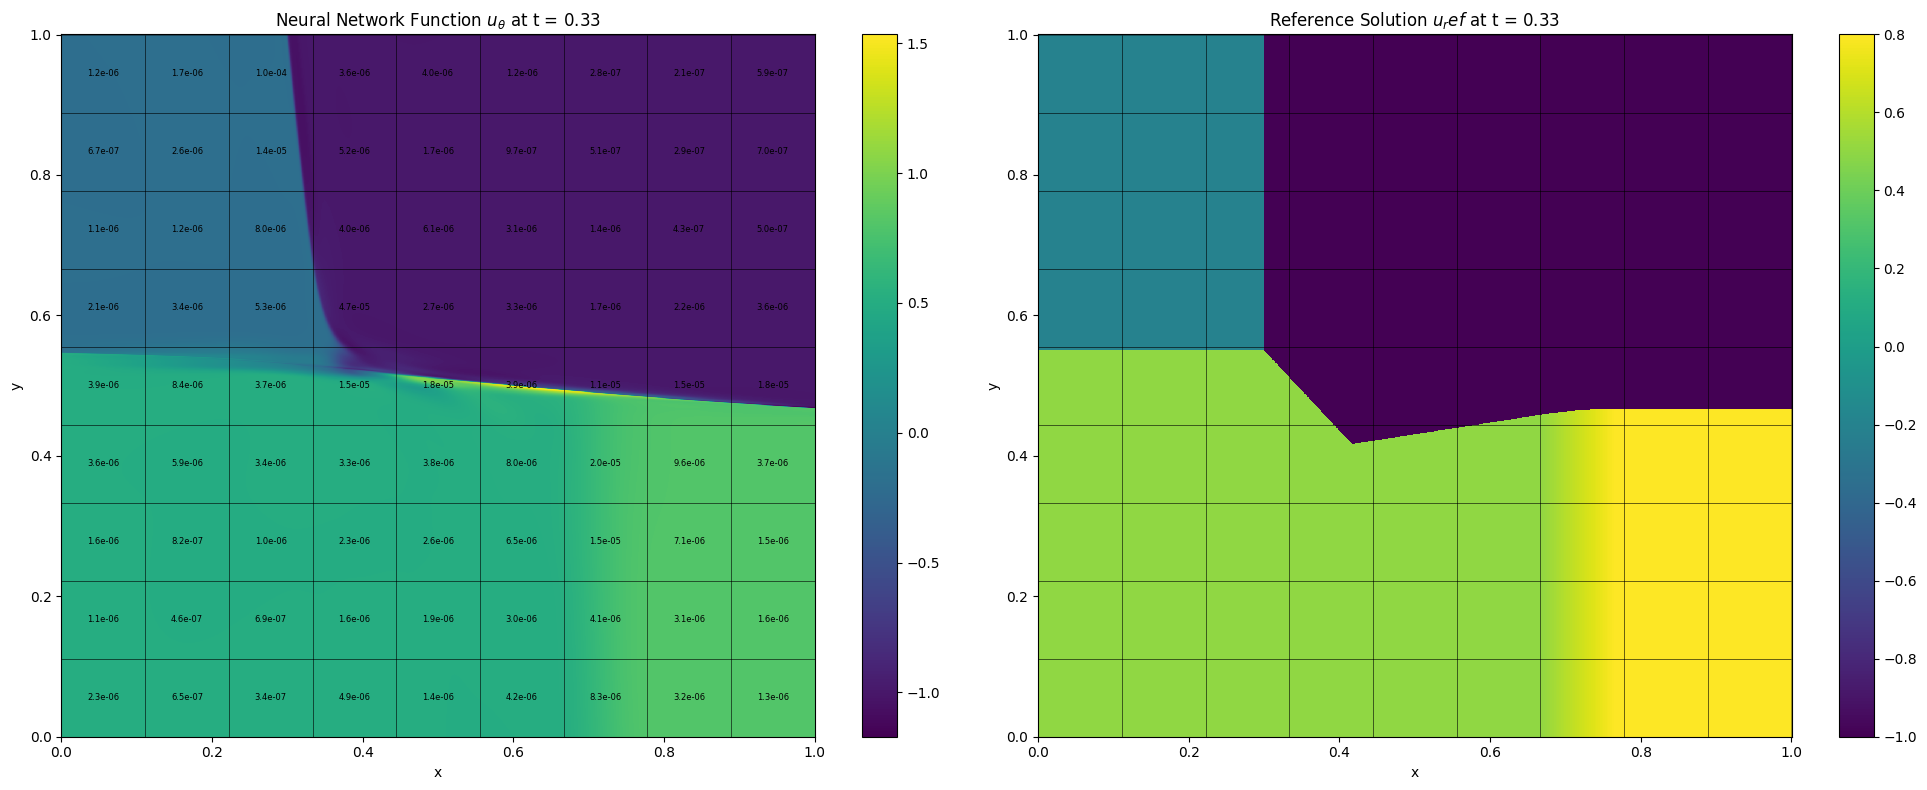

Updating importance sampling probabilities...
Grade 0, Iter 9100, loss_eqn: 0.004806, loss_eqn_from_kh: 0.004806 loss_l1: 0.004806, loss_ibc: 0.000353
Updating importance sampling probabilities...
Grade 0, Iter 9200, loss_eqn: 0.004379, loss_eqn_from_kh: 0.004379 loss_l1: 0.004379, loss_ibc: 0.000350
Updating importance sampling probabilities...
Grade 0, Iter 9300, loss_eqn: 0.004220, loss_eqn_from_kh: 0.004220 loss_l1: 0.004220, loss_ibc: 0.000346
Updating importance sampling probabilities...
Grade 0, Iter 9400, loss_eqn: 0.004466, loss_eqn_from_kh: 0.004466 loss_l1: 0.004466, loss_ibc: 0.000348
Updating importance sampling probabilities...
Grade 0, Iter 9500, loss_eqn: 0.004033, loss_eqn_from_kh: 0.004033 loss_l1: 0.004033, loss_ibc: 0.000346
Updating importance sampling probabilities...
Grade 0, Iter 9600, loss_eqn: 0.004272, loss_eqn_from_kh: 0.004272 loss_l1: 0.004272, loss_ibc: 0.000346
Updating importance sampling probabilities...
Grade 0, Iter 9700, loss_eqn: 0.003884, loss_eqn

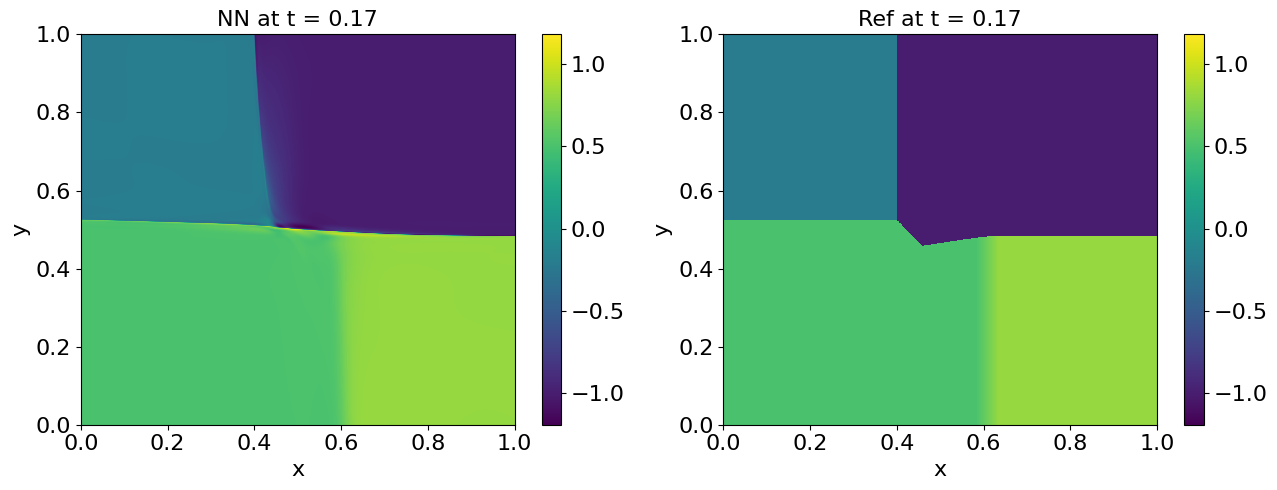

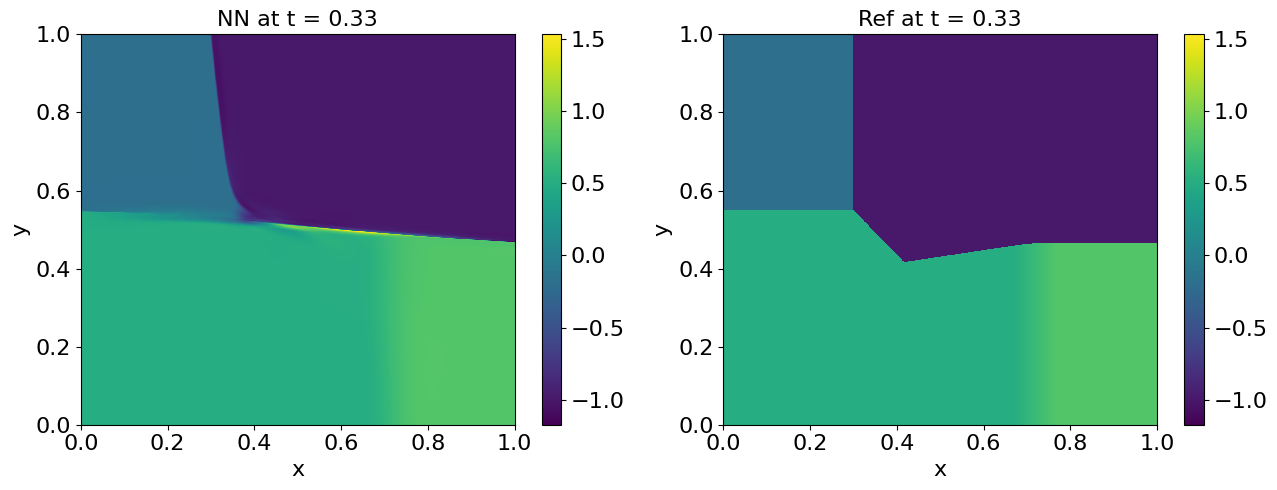

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.3333, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Updating importance sampling probabilities...
Grade 0, Iter 0, lambda_ic: 19.106836, lambda_bc: 18.301891, lambda_eqn: 1.072889
Updating importance sampling probabilities...
Grade 0, Iter 0, loss_eqn: 0.410672, loss_eqn_from_kh: 0.410673 loss_l1: 0.410673, loss_ibc: 2.668383


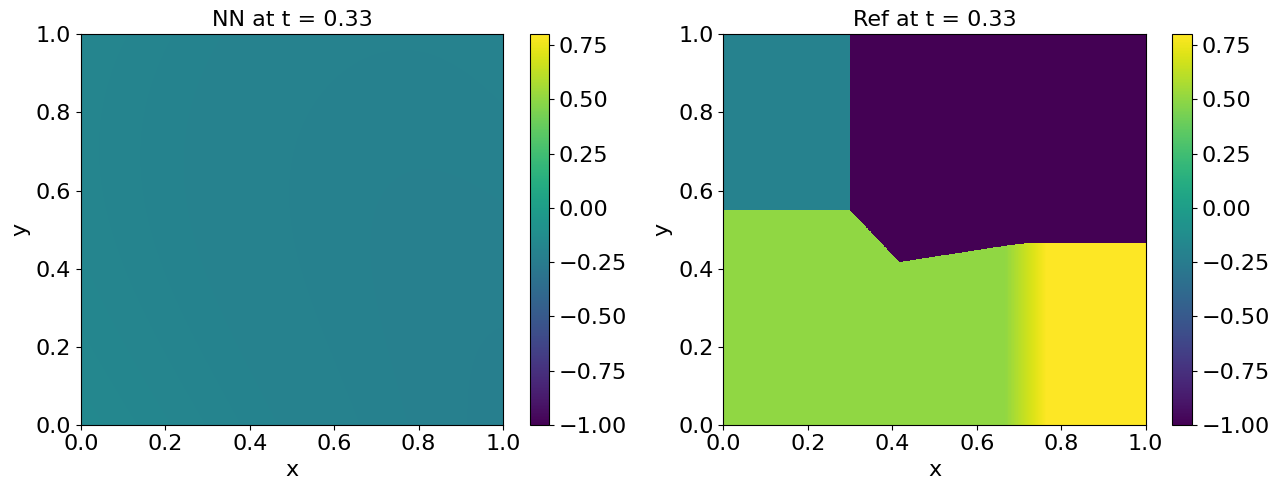

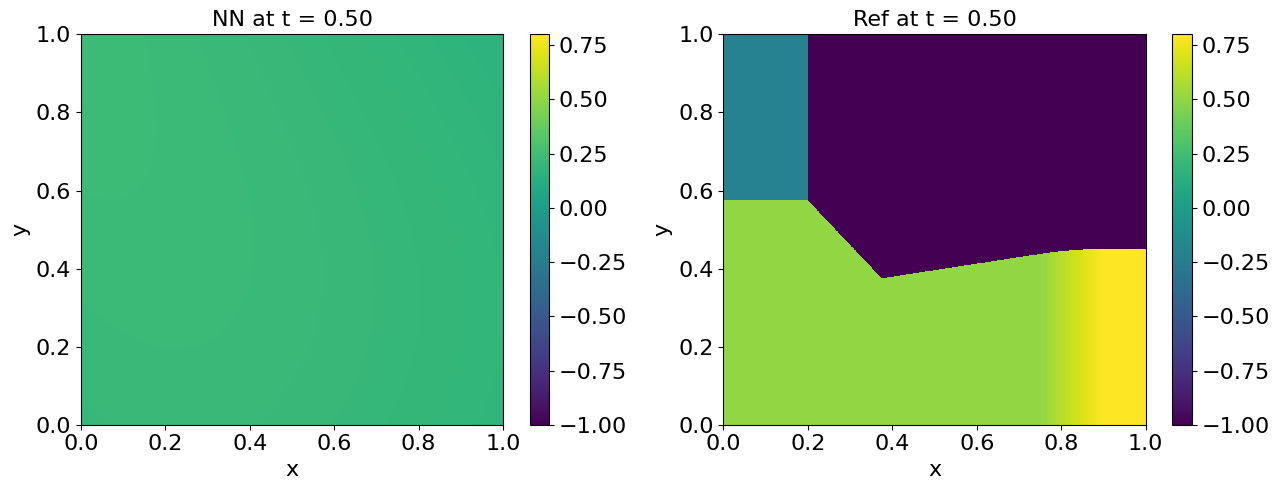

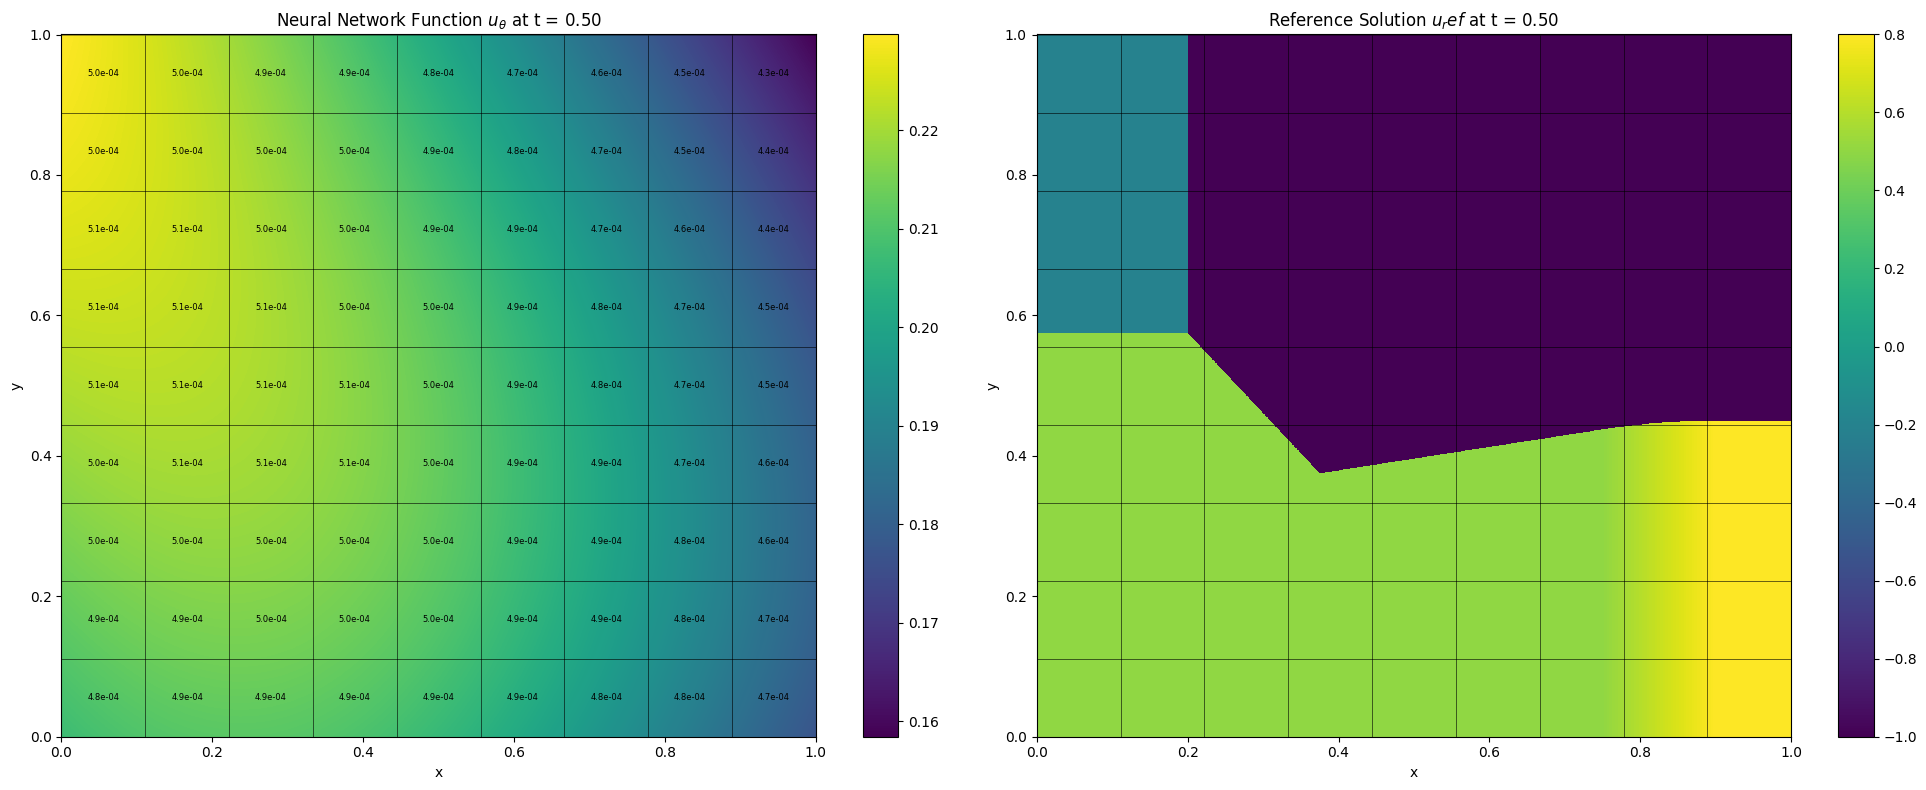

Updating importance sampling probabilities...
Grade 0, Iter 100, loss_eqn: 0.162504, loss_eqn_from_kh: 0.162504 loss_l1: 0.162504, loss_ibc: 0.448917
Updating importance sampling probabilities...
Grade 0, Iter 200, loss_eqn: 0.193904, loss_eqn_from_kh: 0.193904 loss_l1: 0.193904, loss_ibc: 0.120198
Updating importance sampling probabilities...
Grade 0, Iter 300, loss_eqn: 0.153196, loss_eqn_from_kh: 0.153196 loss_l1: 0.153196, loss_ibc: 0.055916
Updating importance sampling probabilities...
Grade 0, Iter 400, loss_eqn: 0.167189, loss_eqn_from_kh: 0.167189 loss_l1: 0.167189, loss_ibc: 0.034046
Updating importance sampling probabilities...
Grade 0, Iter 500, loss_eqn: 0.161762, loss_eqn_from_kh: 0.161762 loss_l1: 0.161762, loss_ibc: 0.023291
Updating importance sampling probabilities...
Grade 0, Iter 600, loss_eqn: 0.147152, loss_eqn_from_kh: 0.147151 loss_l1: 0.147151, loss_ibc: 0.017212
Updating importance sampling probabilities...
Grade 0, Iter 700, loss_eqn: 0.129968, loss_eqn_from_k

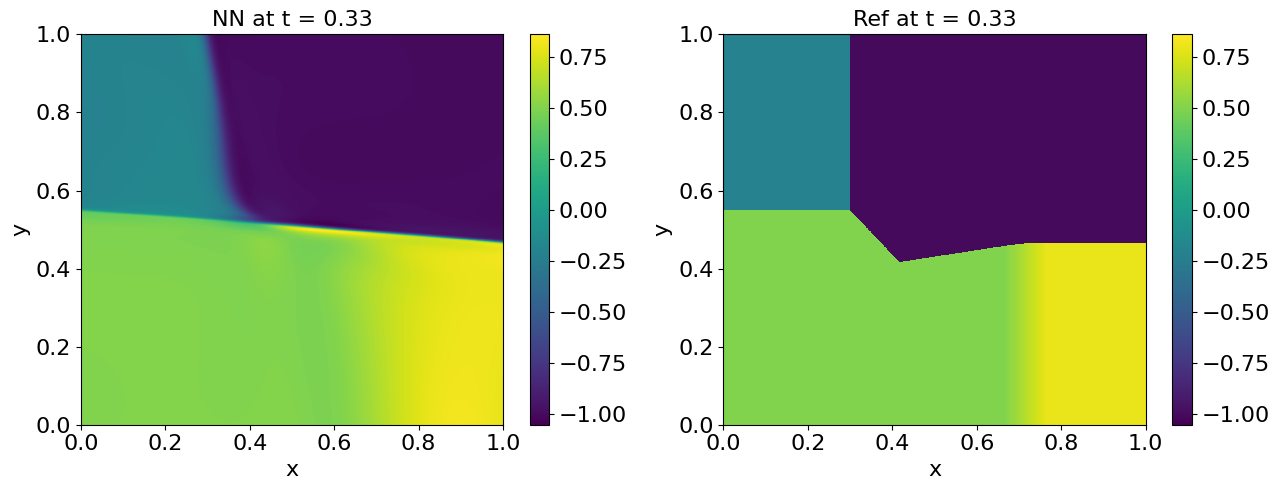

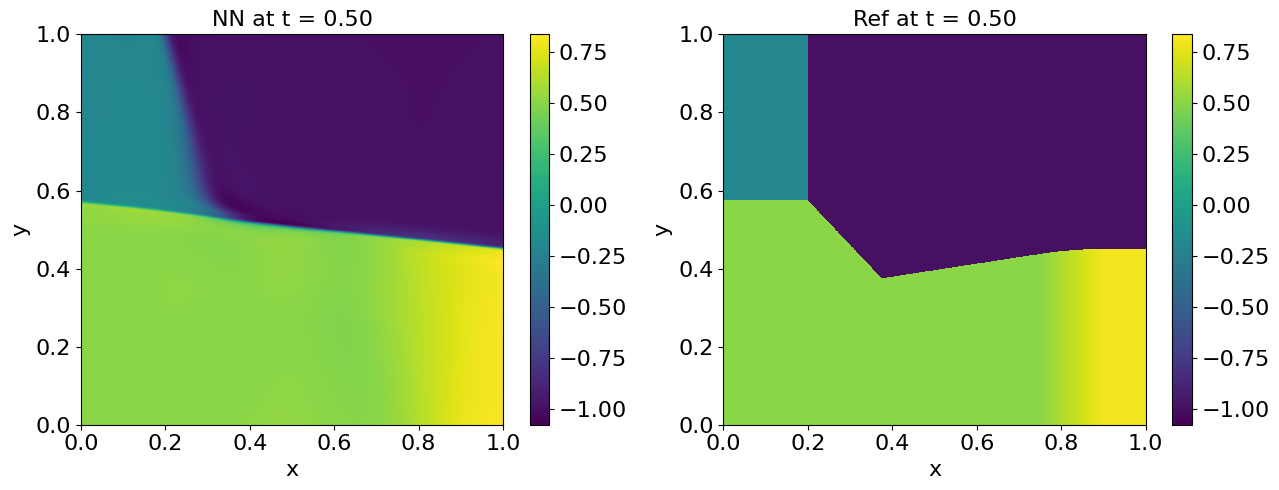

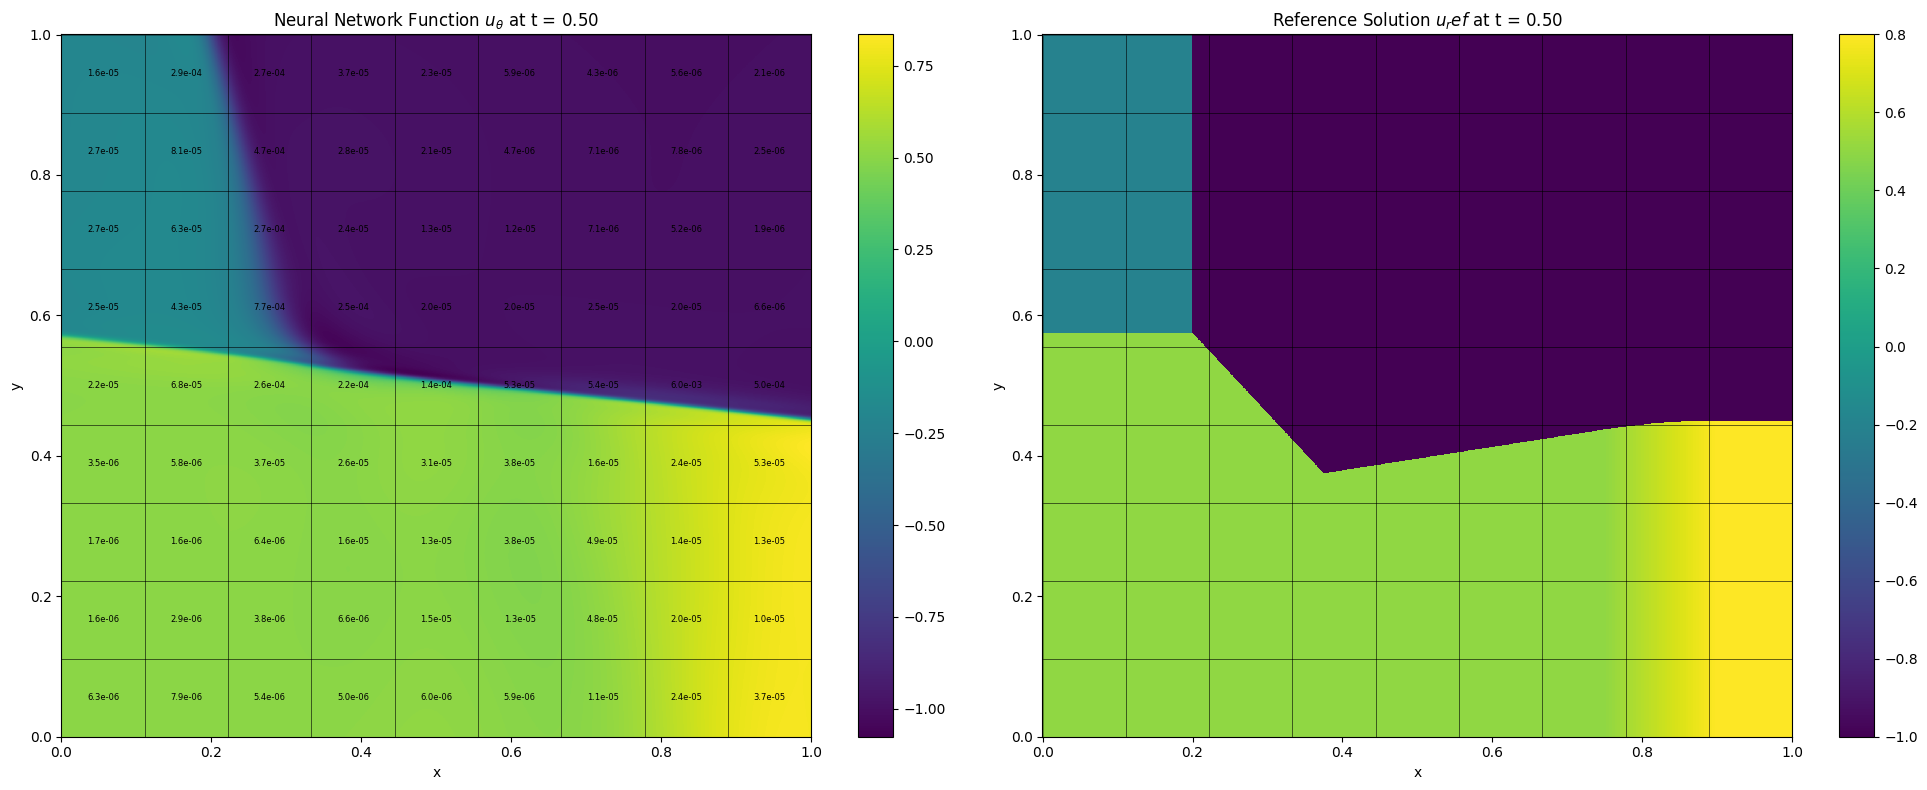

Updating importance sampling probabilities...
Grade 0, Iter 1100, loss_eqn: 0.097330, loss_eqn_from_kh: 0.097330 loss_l1: 0.097330, loss_ibc: 0.007143
Updating importance sampling probabilities...
Grade 0, Iter 1200, loss_eqn: 0.087659, loss_eqn_from_kh: 0.087659 loss_l1: 0.087659, loss_ibc: 0.007159
Updating importance sampling probabilities...
Grade 0, Iter 1300, loss_eqn: 0.090790, loss_eqn_from_kh: 0.090790 loss_l1: 0.090790, loss_ibc: 0.006666
Updating importance sampling probabilities...
Grade 0, Iter 1400, loss_eqn: 0.077689, loss_eqn_from_kh: 0.077689 loss_l1: 0.077689, loss_ibc: 0.006004
Updating importance sampling probabilities...
Grade 0, Iter 1500, loss_eqn: 0.083355, loss_eqn_from_kh: 0.083355 loss_l1: 0.083355, loss_ibc: 0.006778
Updating importance sampling probabilities...
Grade 0, Iter 1600, loss_eqn: 0.066039, loss_eqn_from_kh: 0.066039 loss_l1: 0.066039, loss_ibc: 0.005323
Updating importance sampling probabilities...
Grade 0, Iter 1700, loss_eqn: 0.063319, loss_eqn

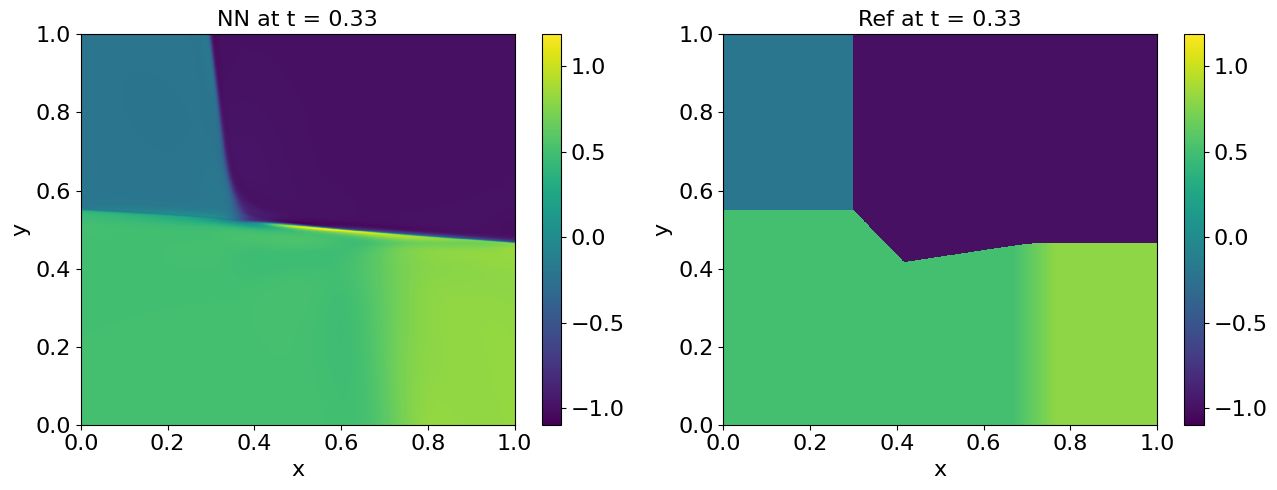

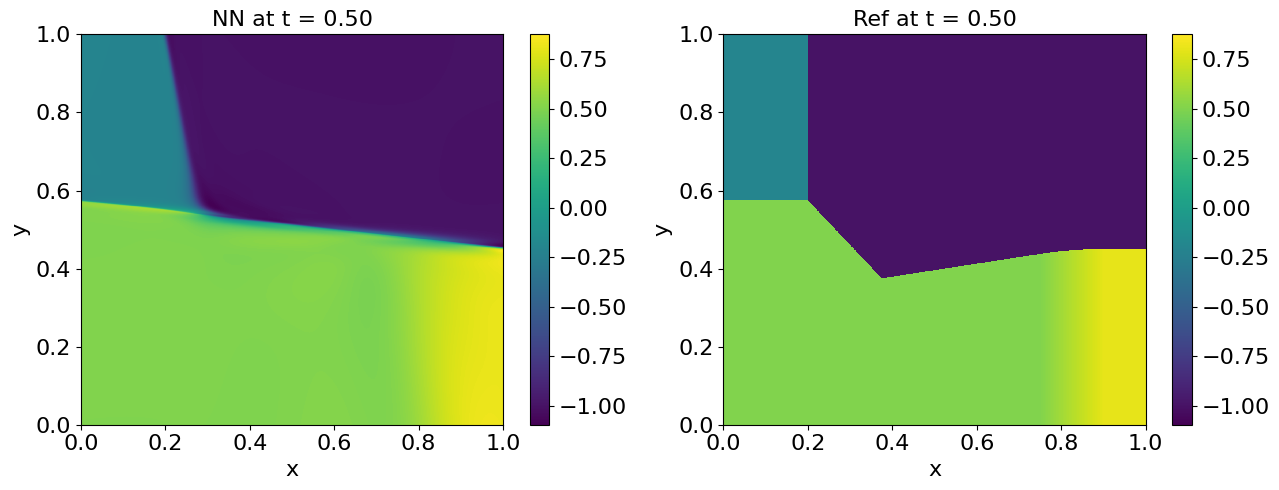

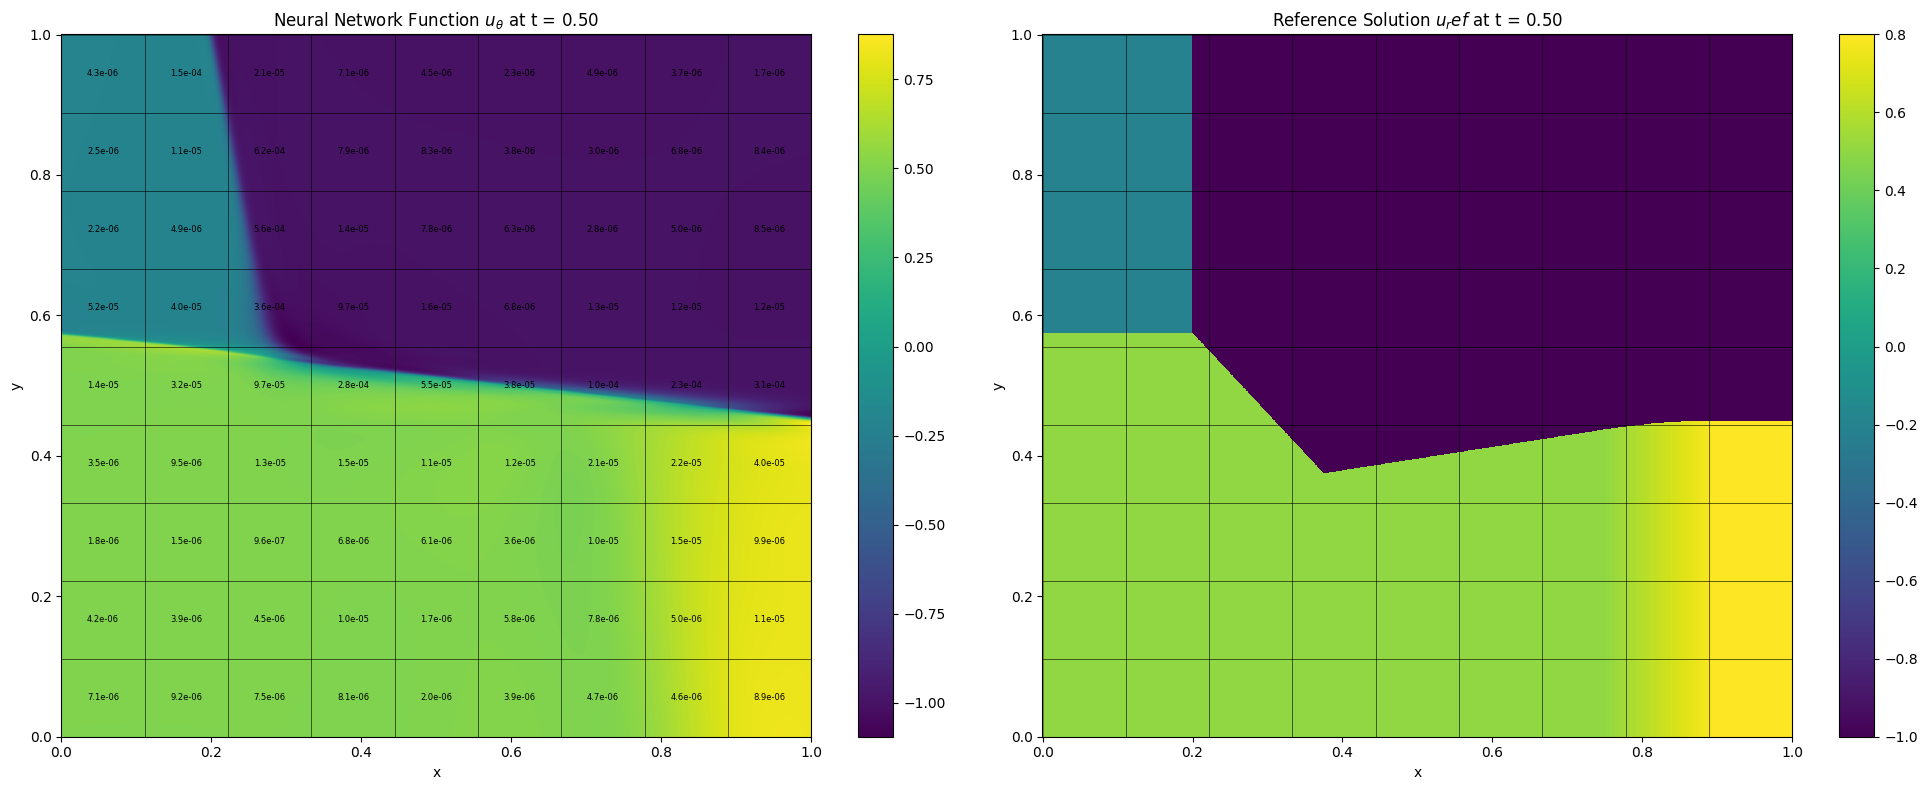

Updating importance sampling probabilities...
Grade 0, Iter 2100, loss_eqn: 0.046384, loss_eqn_from_kh: 0.046384 loss_l1: 0.046384, loss_ibc: 0.003652
Updating importance sampling probabilities...
Grade 0, Iter 2200, loss_eqn: 0.043320, loss_eqn_from_kh: 0.043320 loss_l1: 0.043320, loss_ibc: 0.003291
Updating importance sampling probabilities...
Grade 0, Iter 2300, loss_eqn: 0.035937, loss_eqn_from_kh: 0.035937 loss_l1: 0.035937, loss_ibc: 0.003976
Updating importance sampling probabilities...
Grade 0, Iter 2400, loss_eqn: 0.044696, loss_eqn_from_kh: 0.044696 loss_l1: 0.044696, loss_ibc: 0.004069
Updating importance sampling probabilities...
Grade 0, Iter 2500, loss_eqn: 0.041997, loss_eqn_from_kh: 0.041997 loss_l1: 0.041997, loss_ibc: 0.002588
Updating importance sampling probabilities...
Grade 0, Iter 2600, loss_eqn: 0.030230, loss_eqn_from_kh: 0.030230 loss_l1: 0.030230, loss_ibc: 0.002823
Updating importance sampling probabilities...
Grade 0, Iter 2700, loss_eqn: 0.040097, loss_eqn

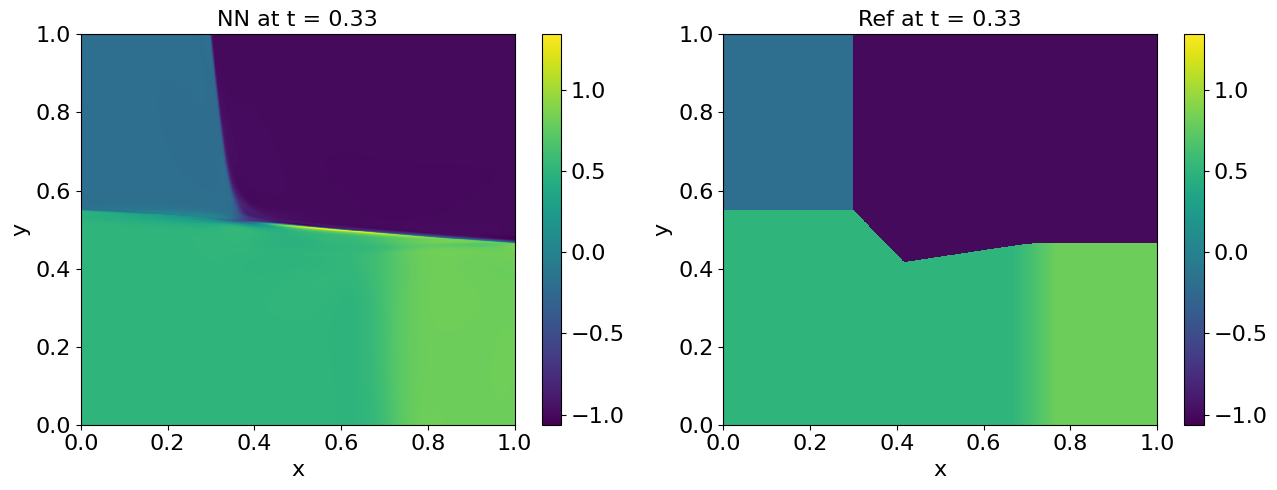

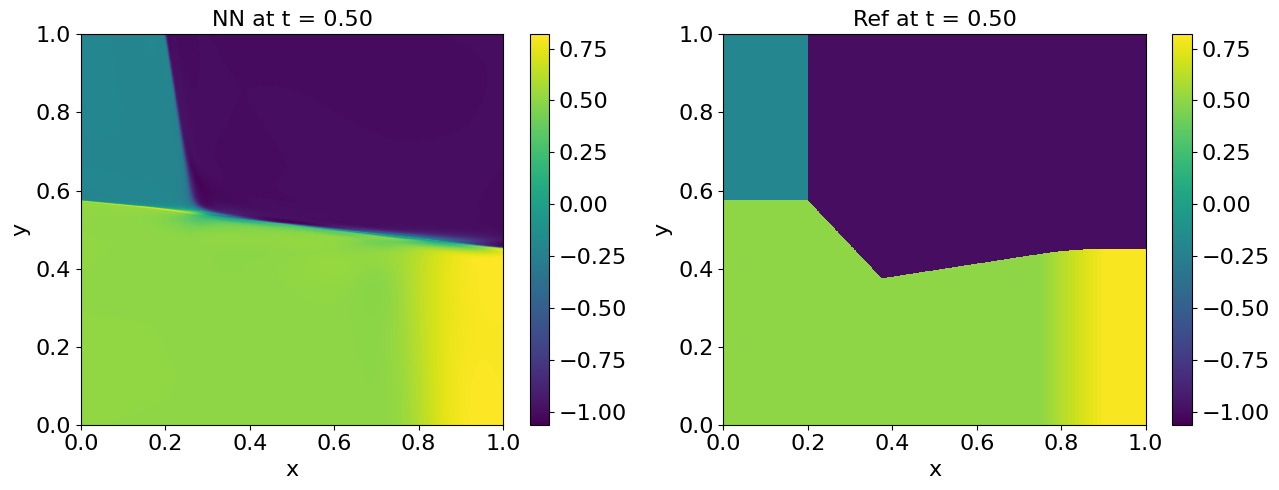

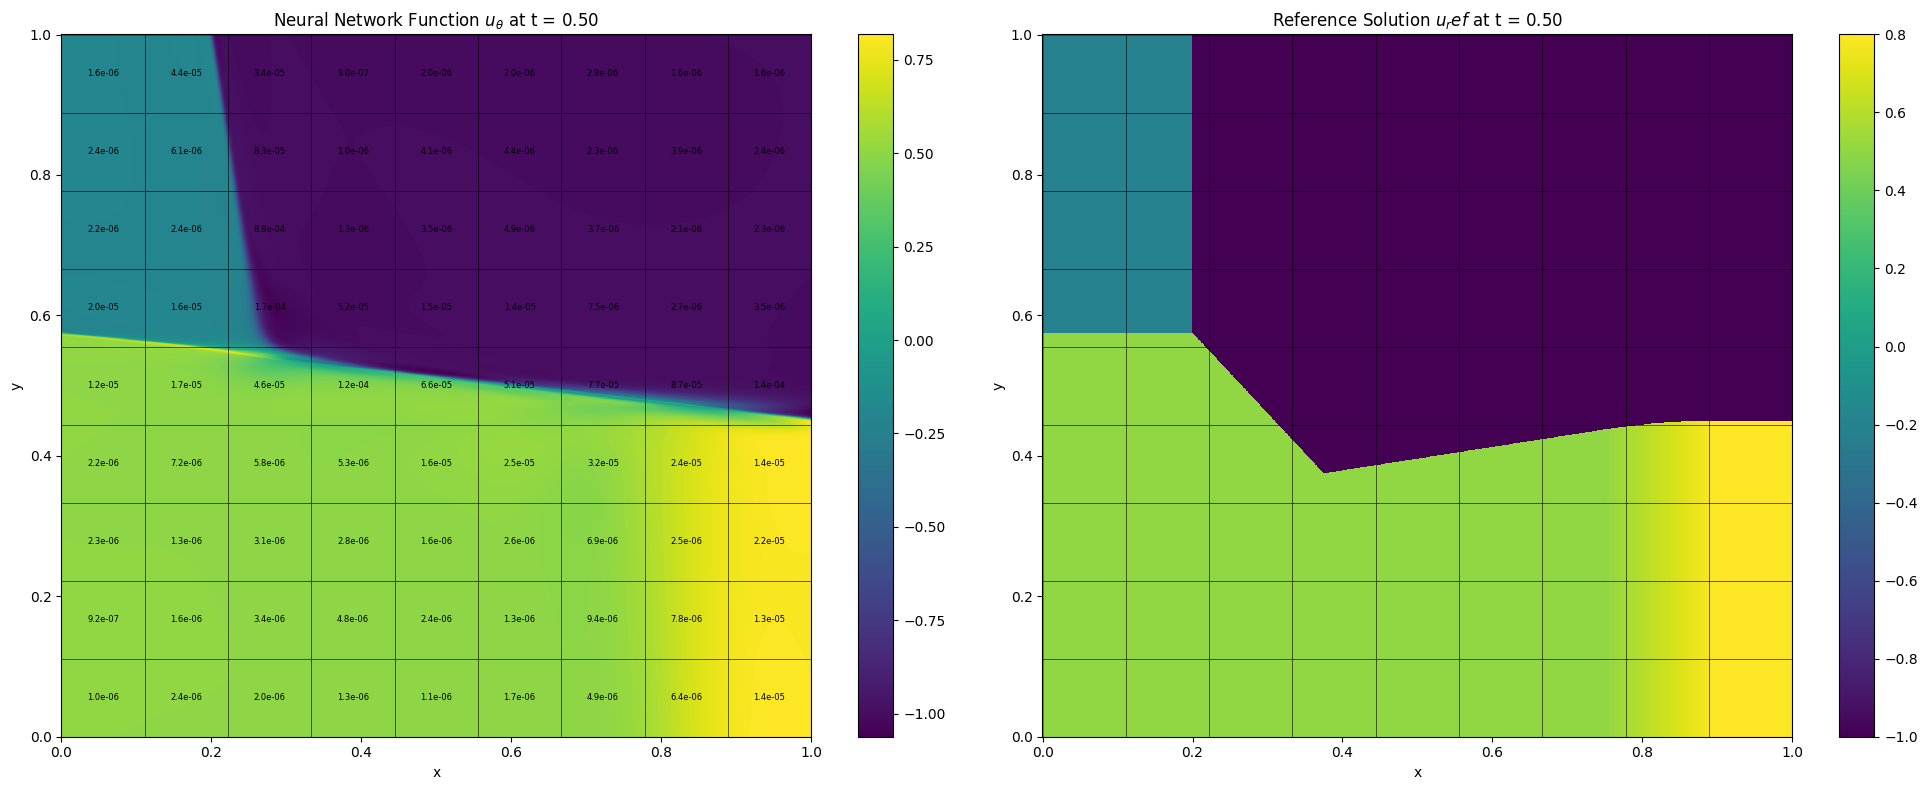

Updating importance sampling probabilities...
Grade 0, Iter 3100, loss_eqn: 0.026354, loss_eqn_from_kh: 0.026354 loss_l1: 0.026354, loss_ibc: 0.001917
Updating importance sampling probabilities...
Grade 0, Iter 3200, loss_eqn: 0.023356, loss_eqn_from_kh: 0.023356 loss_l1: 0.023356, loss_ibc: 0.001789
Updating importance sampling probabilities...
Grade 0, Iter 3300, loss_eqn: 0.023602, loss_eqn_from_kh: 0.023602 loss_l1: 0.023602, loss_ibc: 0.002794
Updating importance sampling probabilities...
Grade 0, Iter 3400, loss_eqn: 0.024237, loss_eqn_from_kh: 0.024237 loss_l1: 0.024237, loss_ibc: 0.001670
Updating importance sampling probabilities...
Grade 0, Iter 3500, loss_eqn: 0.021672, loss_eqn_from_kh: 0.021672 loss_l1: 0.021672, loss_ibc: 0.001861
Updating importance sampling probabilities...
Grade 0, Iter 3600, loss_eqn: 0.022627, loss_eqn_from_kh: 0.022627 loss_l1: 0.022627, loss_ibc: 0.001644
Updating importance sampling probabilities...
Grade 0, Iter 3700, loss_eqn: 0.018760, loss_eqn

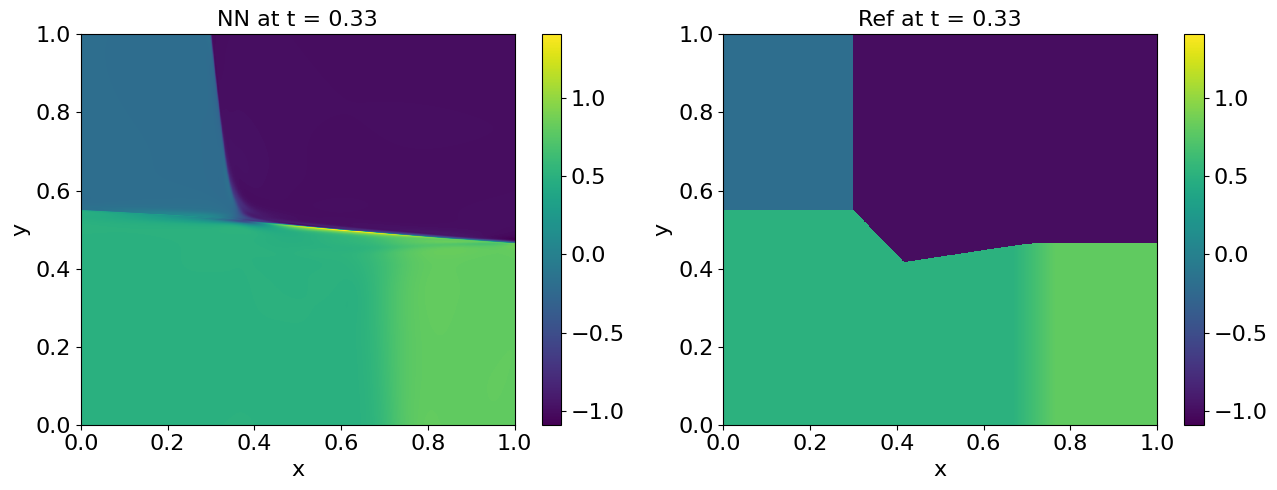

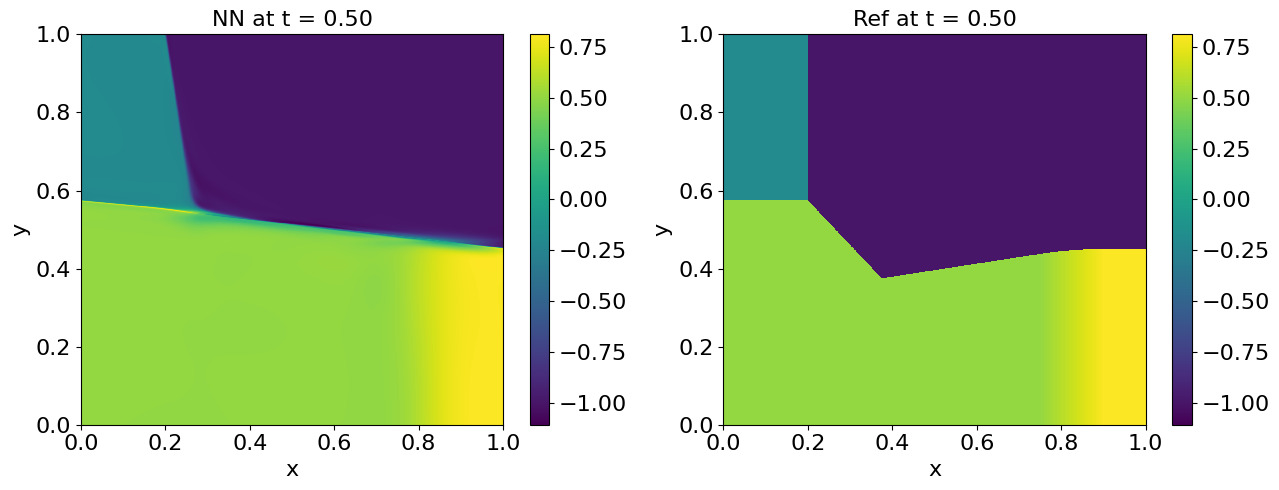

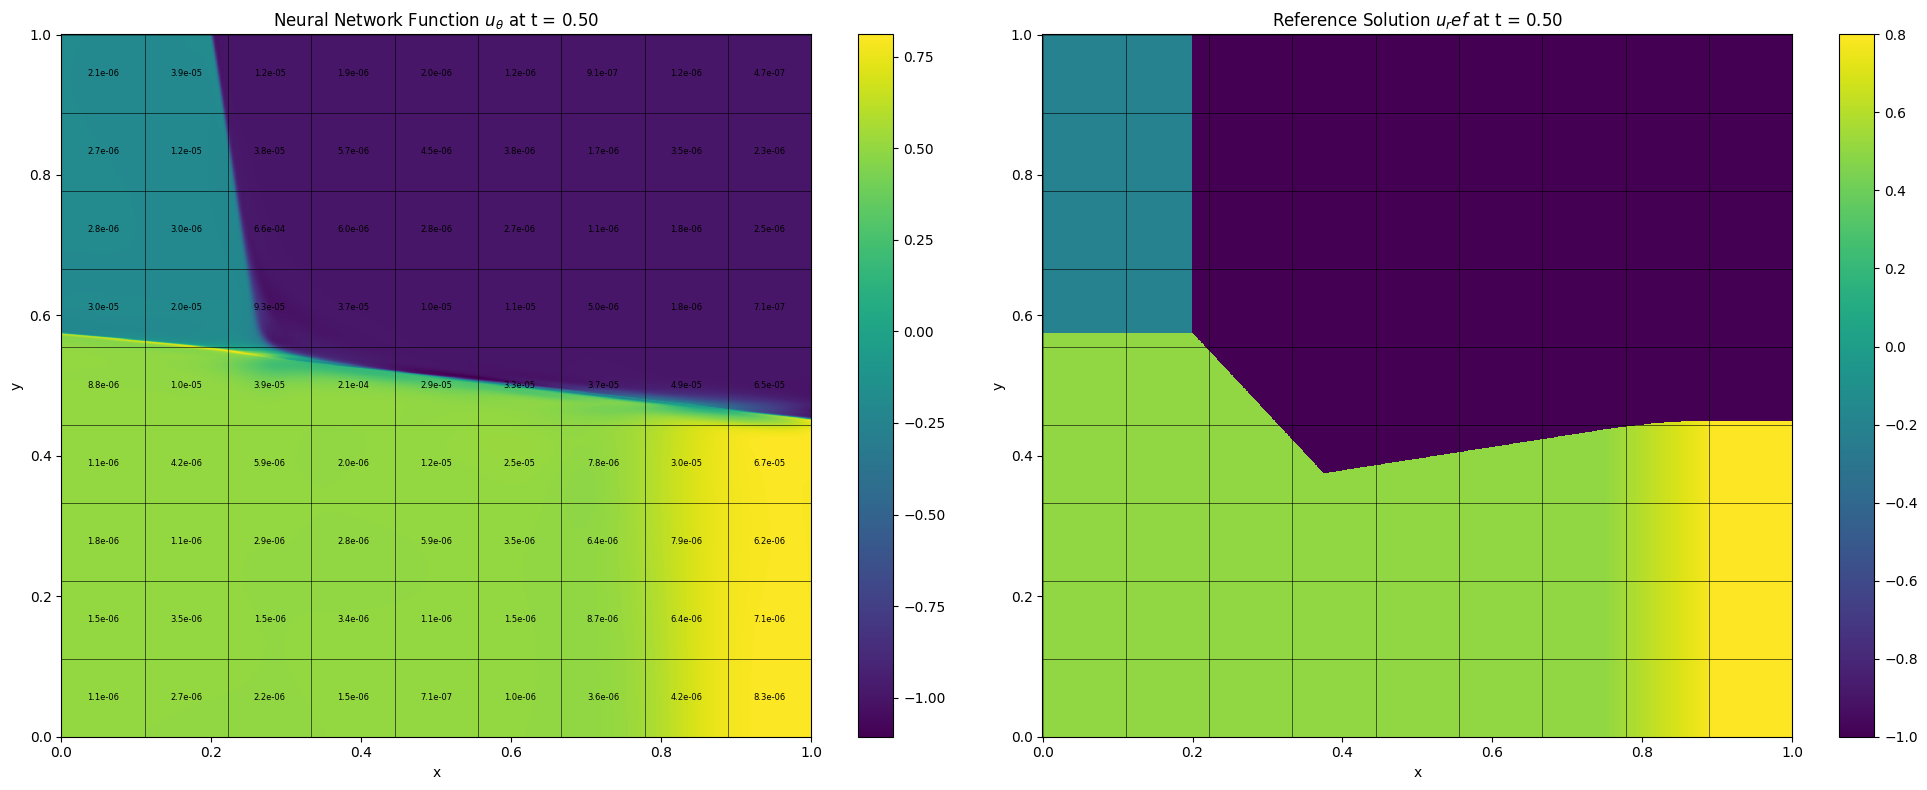

Updating importance sampling probabilities...
Grade 0, Iter 4100, loss_eqn: 0.025351, loss_eqn_from_kh: 0.025351 loss_l1: 0.025351, loss_ibc: 0.001783
Updating importance sampling probabilities...
Grade 0, Iter 4200, loss_eqn: 0.020654, loss_eqn_from_kh: 0.020654 loss_l1: 0.020654, loss_ibc: 0.001684
Updating importance sampling probabilities...
Grade 0, Iter 4300, loss_eqn: 0.017305, loss_eqn_from_kh: 0.017305 loss_l1: 0.017305, loss_ibc: 0.001785
Updating importance sampling probabilities...
Grade 0, Iter 4400, loss_eqn: 0.016336, loss_eqn_from_kh: 0.016336 loss_l1: 0.016336, loss_ibc: 0.001234
Updating importance sampling probabilities...
Grade 0, Iter 4500, loss_eqn: 0.021277, loss_eqn_from_kh: 0.021277 loss_l1: 0.021277, loss_ibc: 0.002746
Updating importance sampling probabilities...
Grade 0, Iter 4600, loss_eqn: 0.020137, loss_eqn_from_kh: 0.020137 loss_l1: 0.020137, loss_ibc: 0.001408
Updating importance sampling probabilities...
Grade 0, Iter 4700, loss_eqn: 0.017923, loss_eqn

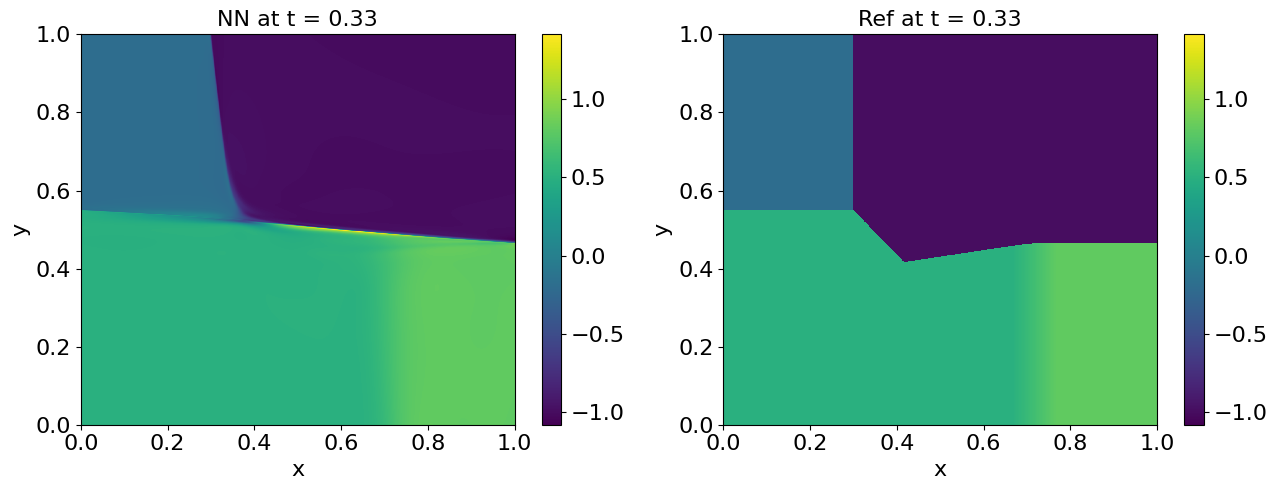

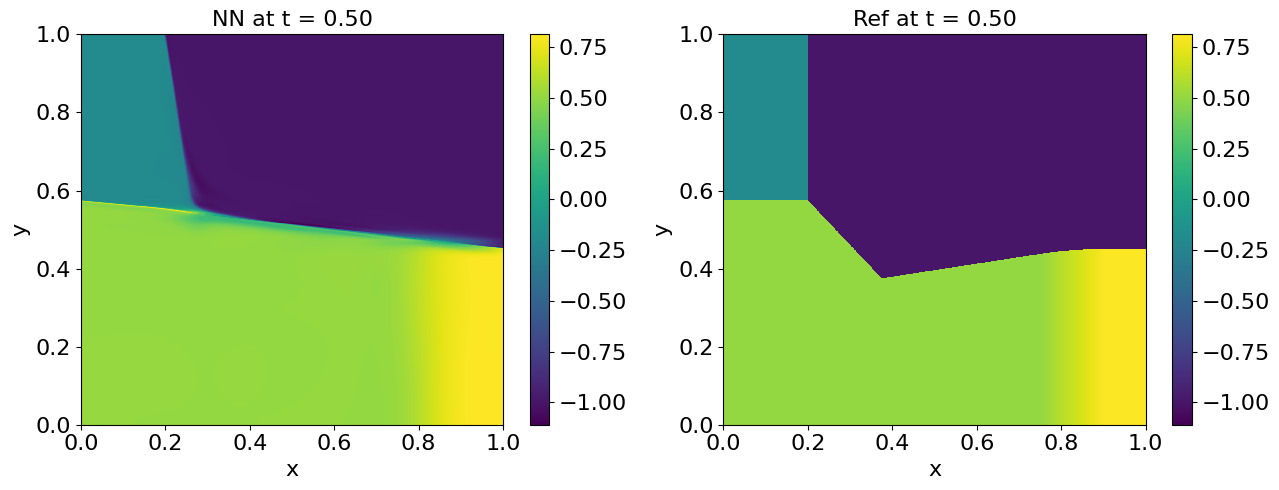

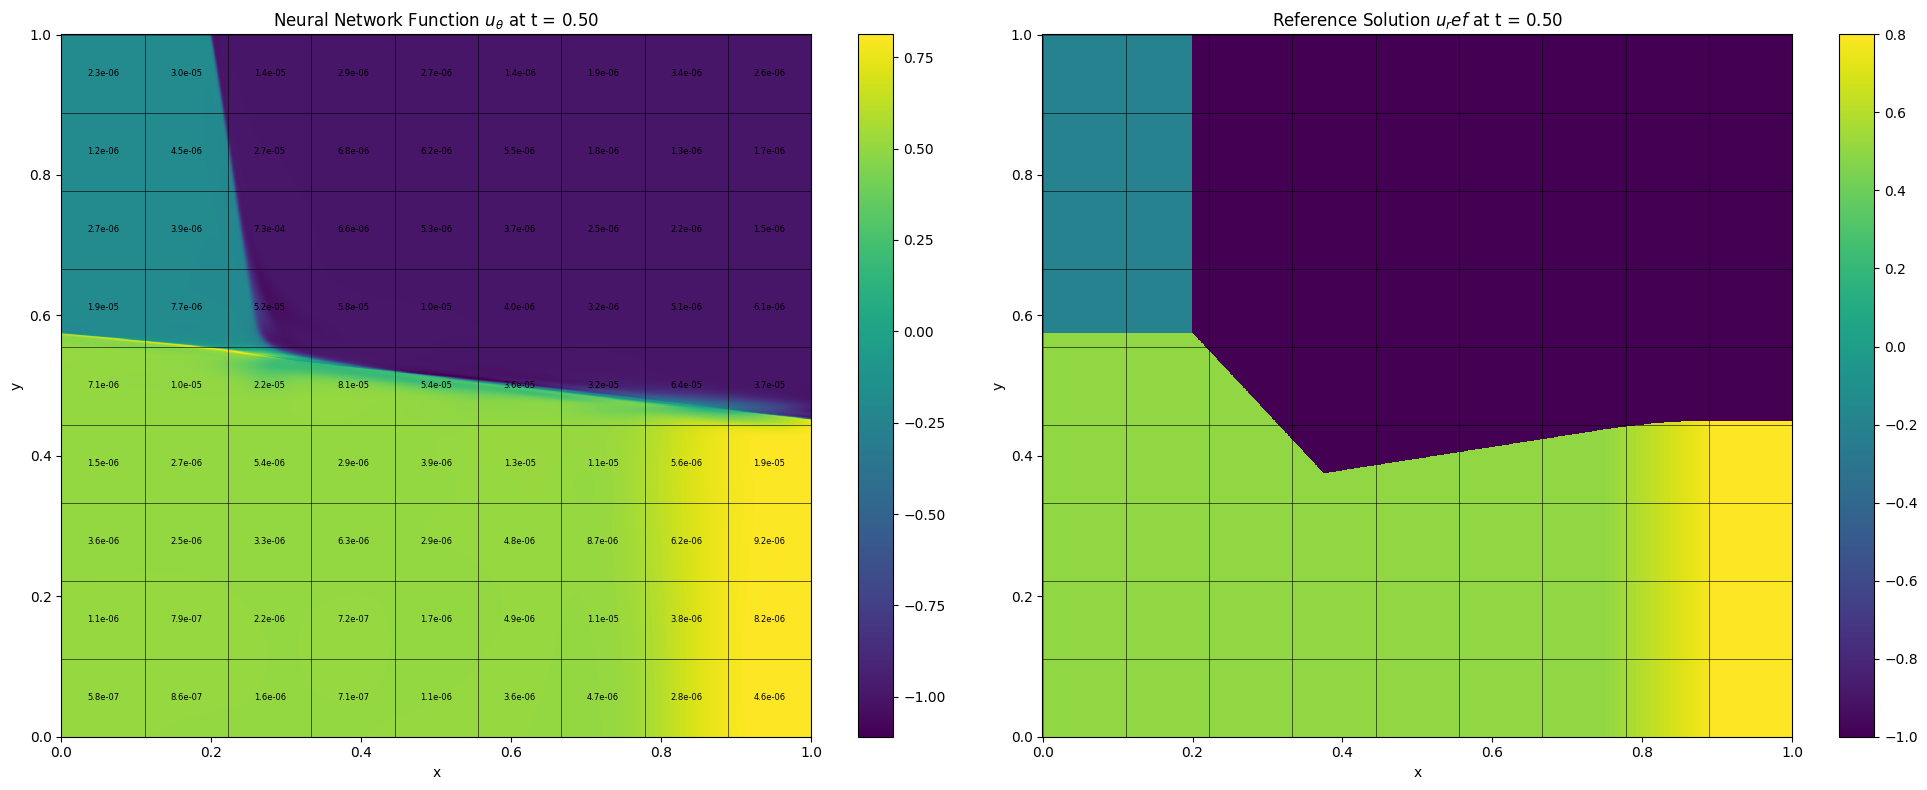

Updating importance sampling probabilities...
Grade 0, Iter 5100, loss_eqn: 0.017695, loss_eqn_from_kh: 0.017695 loss_l1: 0.017695, loss_ibc: 0.001535
Updating importance sampling probabilities...
Grade 0, Iter 5200, loss_eqn: 0.018696, loss_eqn_from_kh: 0.018696 loss_l1: 0.018696, loss_ibc: 0.001136
Updating importance sampling probabilities...
Grade 0, Iter 5300, loss_eqn: 0.016948, loss_eqn_from_kh: 0.016948 loss_l1: 0.016948, loss_ibc: 0.001461
Updating importance sampling probabilities...
Grade 0, Iter 5400, loss_eqn: 0.016574, loss_eqn_from_kh: 0.016574 loss_l1: 0.016574, loss_ibc: 0.001435
Updating importance sampling probabilities...
Grade 0, Iter 5500, loss_eqn: 0.012779, loss_eqn_from_kh: 0.012779 loss_l1: 0.012779, loss_ibc: 0.000961
Updating importance sampling probabilities...
Grade 0, Iter 5600, loss_eqn: 0.016579, loss_eqn_from_kh: 0.016579 loss_l1: 0.016579, loss_ibc: 0.002478
Updating importance sampling probabilities...
Grade 0, Iter 5700, loss_eqn: 0.014512, loss_eqn

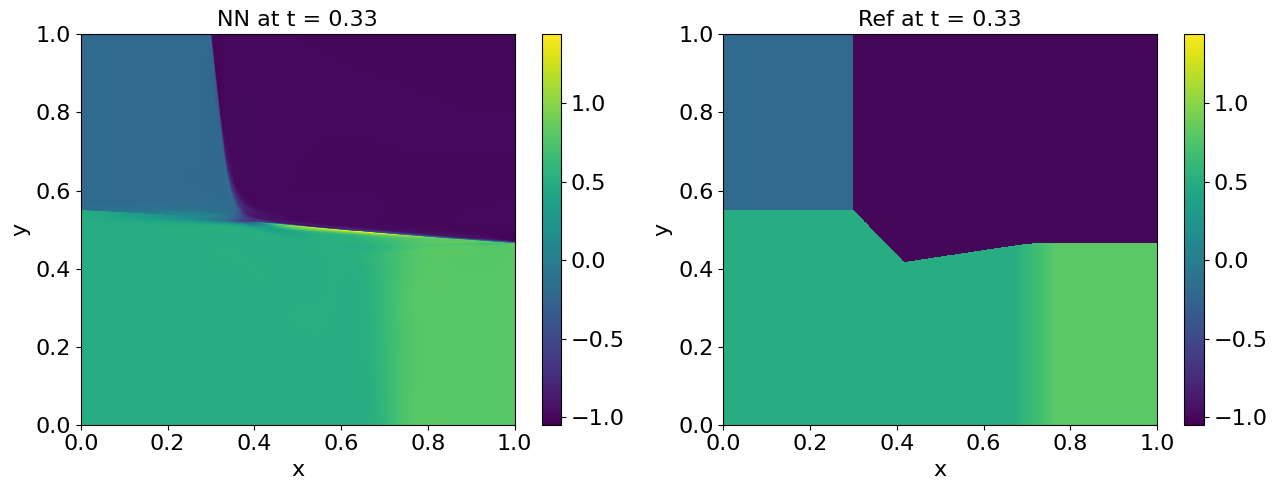

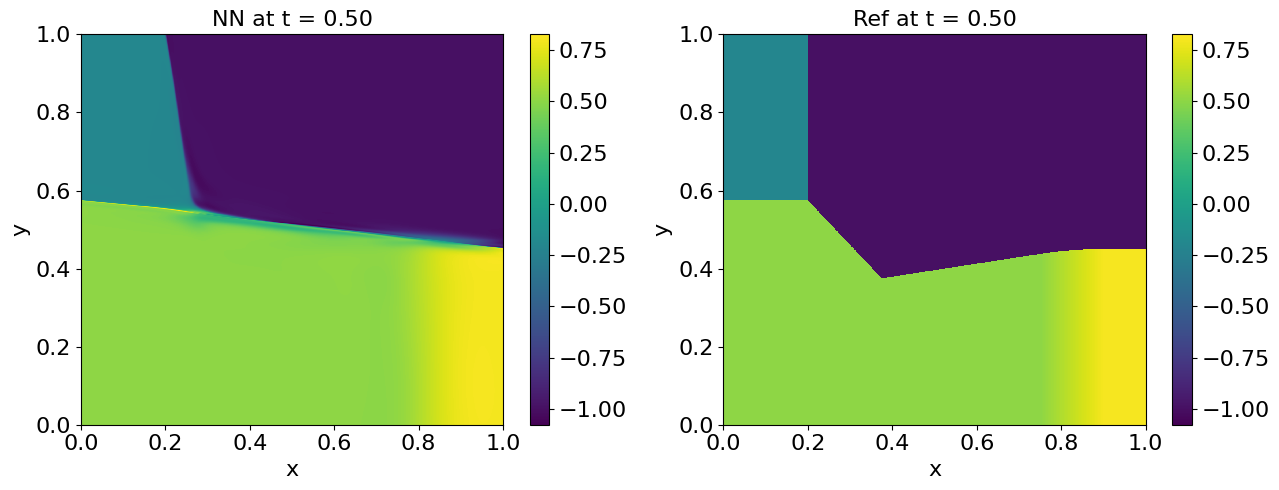

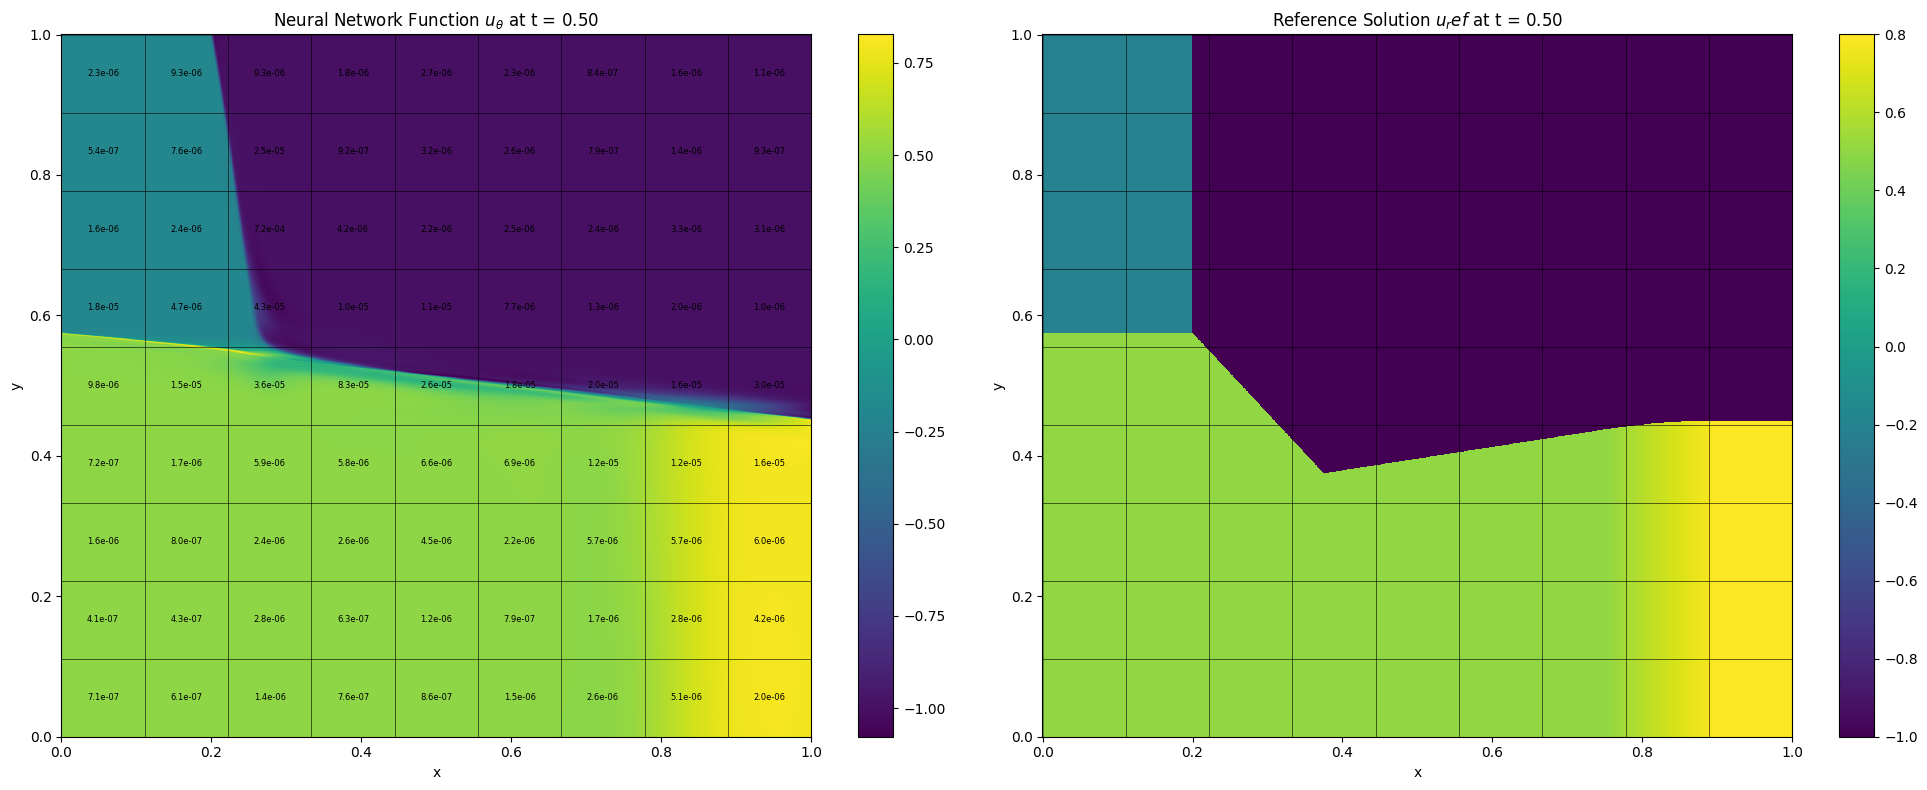

Updating importance sampling probabilities...
Grade 0, Iter 6100, loss_eqn: 0.011592, loss_eqn_from_kh: 0.011592 loss_l1: 0.011592, loss_ibc: 0.000868
Updating importance sampling probabilities...
Grade 0, Iter 6200, loss_eqn: 0.013622, loss_eqn_from_kh: 0.013622 loss_l1: 0.013622, loss_ibc: 0.000854
Updating importance sampling probabilities...
Grade 0, Iter 6300, loss_eqn: 0.012413, loss_eqn_from_kh: 0.012413 loss_l1: 0.012413, loss_ibc: 0.000879
Updating importance sampling probabilities...
Grade 0, Iter 6400, loss_eqn: 0.012061, loss_eqn_from_kh: 0.012061 loss_l1: 0.012061, loss_ibc: 0.000922
Updating importance sampling probabilities...
Grade 0, Iter 6500, loss_eqn: 0.010484, loss_eqn_from_kh: 0.010484 loss_l1: 0.010484, loss_ibc: 0.000816
Updating importance sampling probabilities...
Grade 0, Iter 6600, loss_eqn: 0.016980, loss_eqn_from_kh: 0.016980 loss_l1: 0.016980, loss_ibc: 0.001438
Updating importance sampling probabilities...
Grade 0, Iter 6700, loss_eqn: 0.010218, loss_eqn

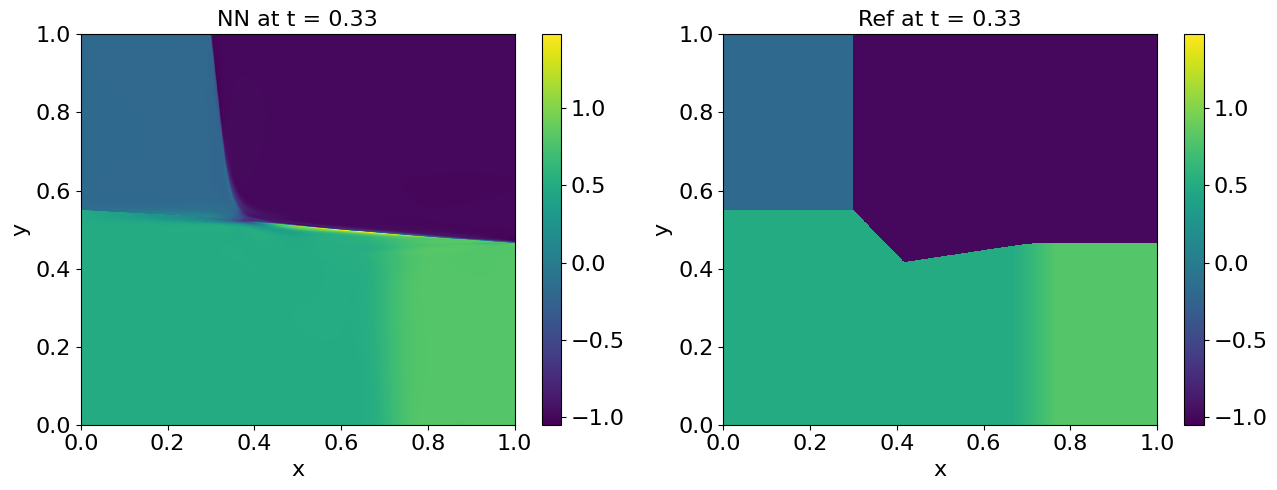

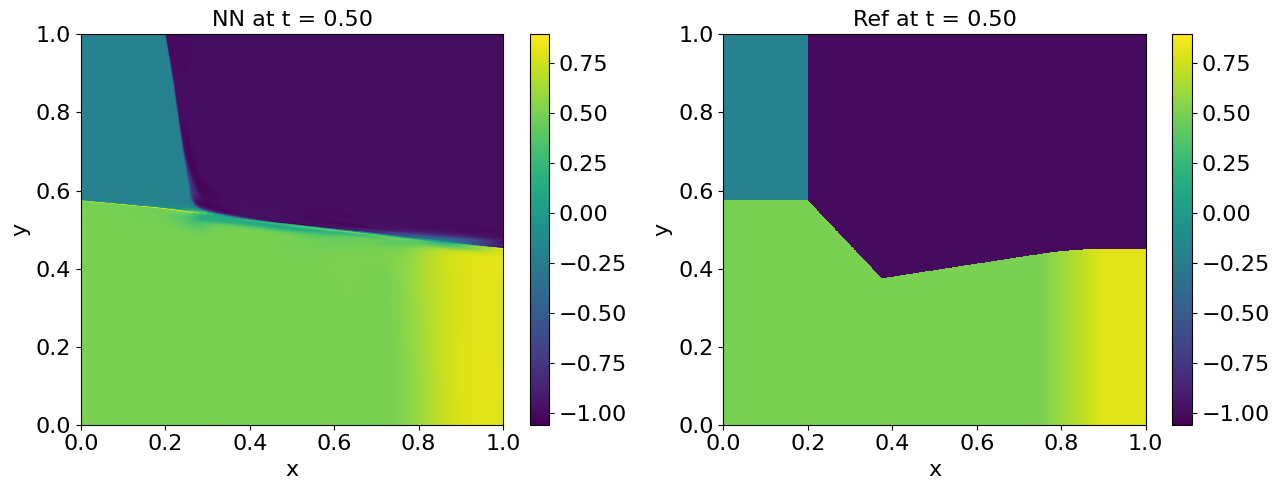

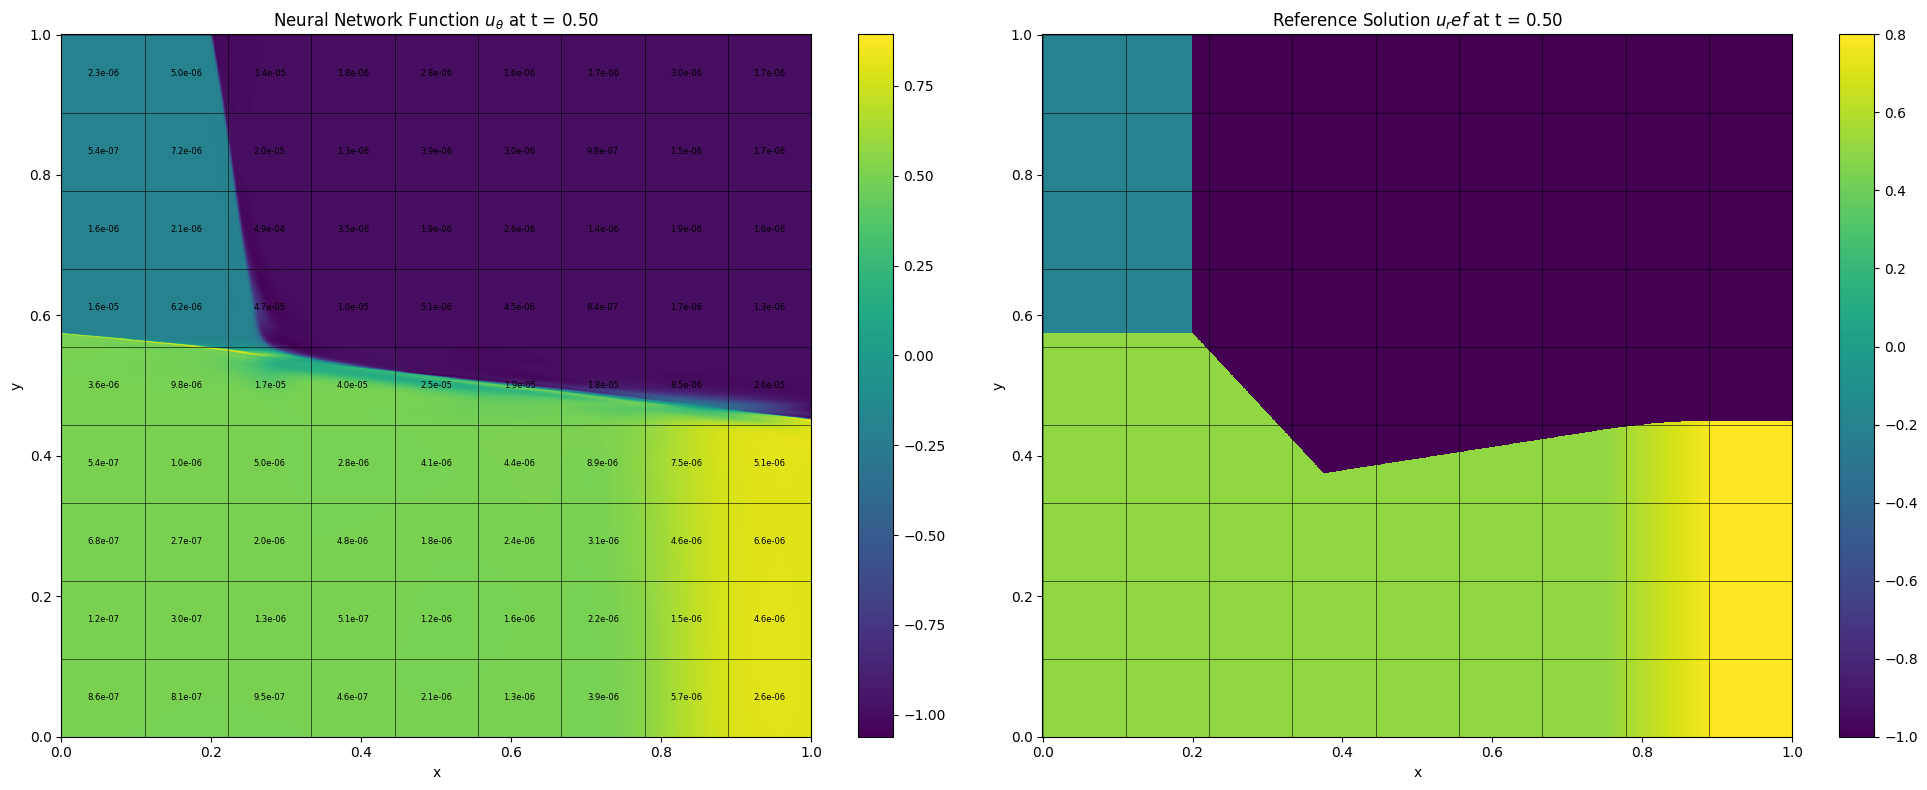

Updating importance sampling probabilities...
Grade 0, Iter 7100, loss_eqn: 0.014313, loss_eqn_from_kh: 0.014313 loss_l1: 0.014313, loss_ibc: 0.000860
Updating importance sampling probabilities...
Grade 0, Iter 7200, loss_eqn: 0.010799, loss_eqn_from_kh: 0.010799 loss_l1: 0.010799, loss_ibc: 0.000758
Updating importance sampling probabilities...
Grade 0, Iter 7300, loss_eqn: 0.009157, loss_eqn_from_kh: 0.009157 loss_l1: 0.009157, loss_ibc: 0.000717
Updating importance sampling probabilities...
Grade 0, Iter 7400, loss_eqn: 0.008914, loss_eqn_from_kh: 0.008914 loss_l1: 0.008914, loss_ibc: 0.000707
Updating importance sampling probabilities...
Grade 0, Iter 7500, loss_eqn: 0.007867, loss_eqn_from_kh: 0.007867 loss_l1: 0.007867, loss_ibc: 0.000688
Updating importance sampling probabilities...
Grade 0, Iter 7600, loss_eqn: 0.008440, loss_eqn_from_kh: 0.008440 loss_l1: 0.008440, loss_ibc: 0.000695
Updating importance sampling probabilities...
Grade 0, Iter 7700, loss_eqn: 0.009528, loss_eqn

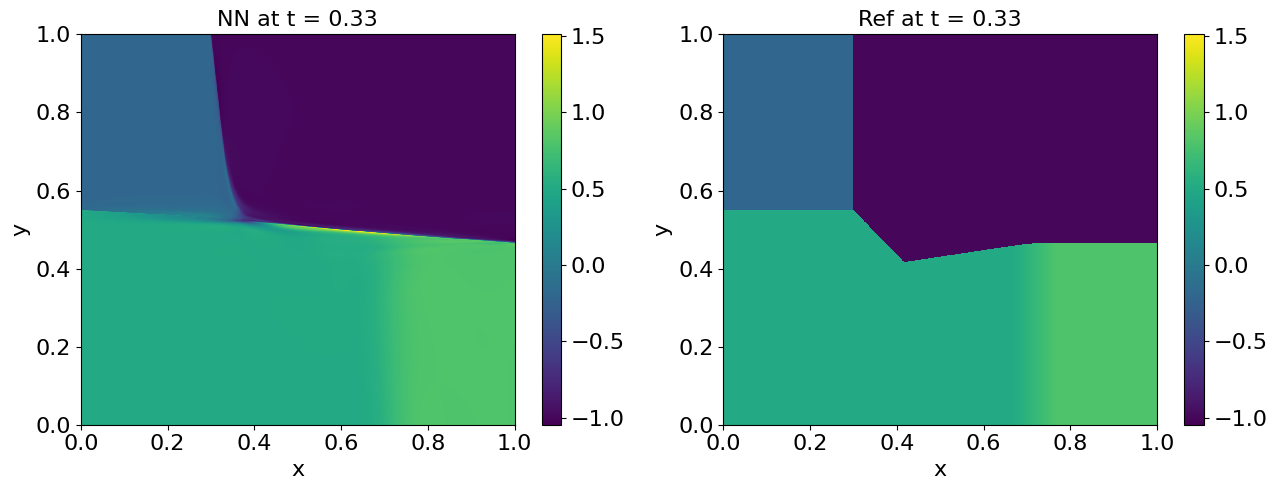

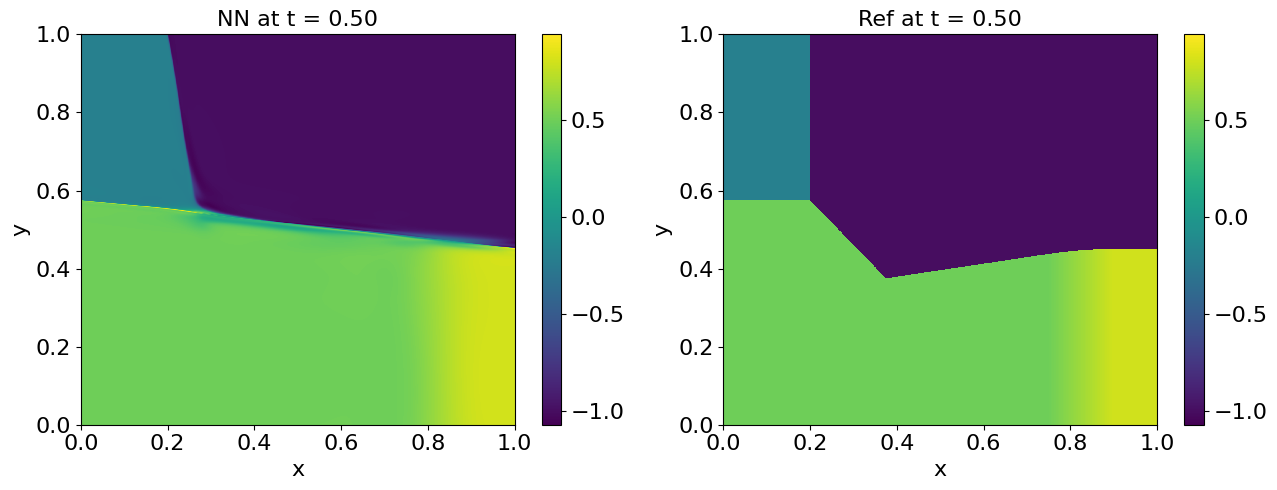

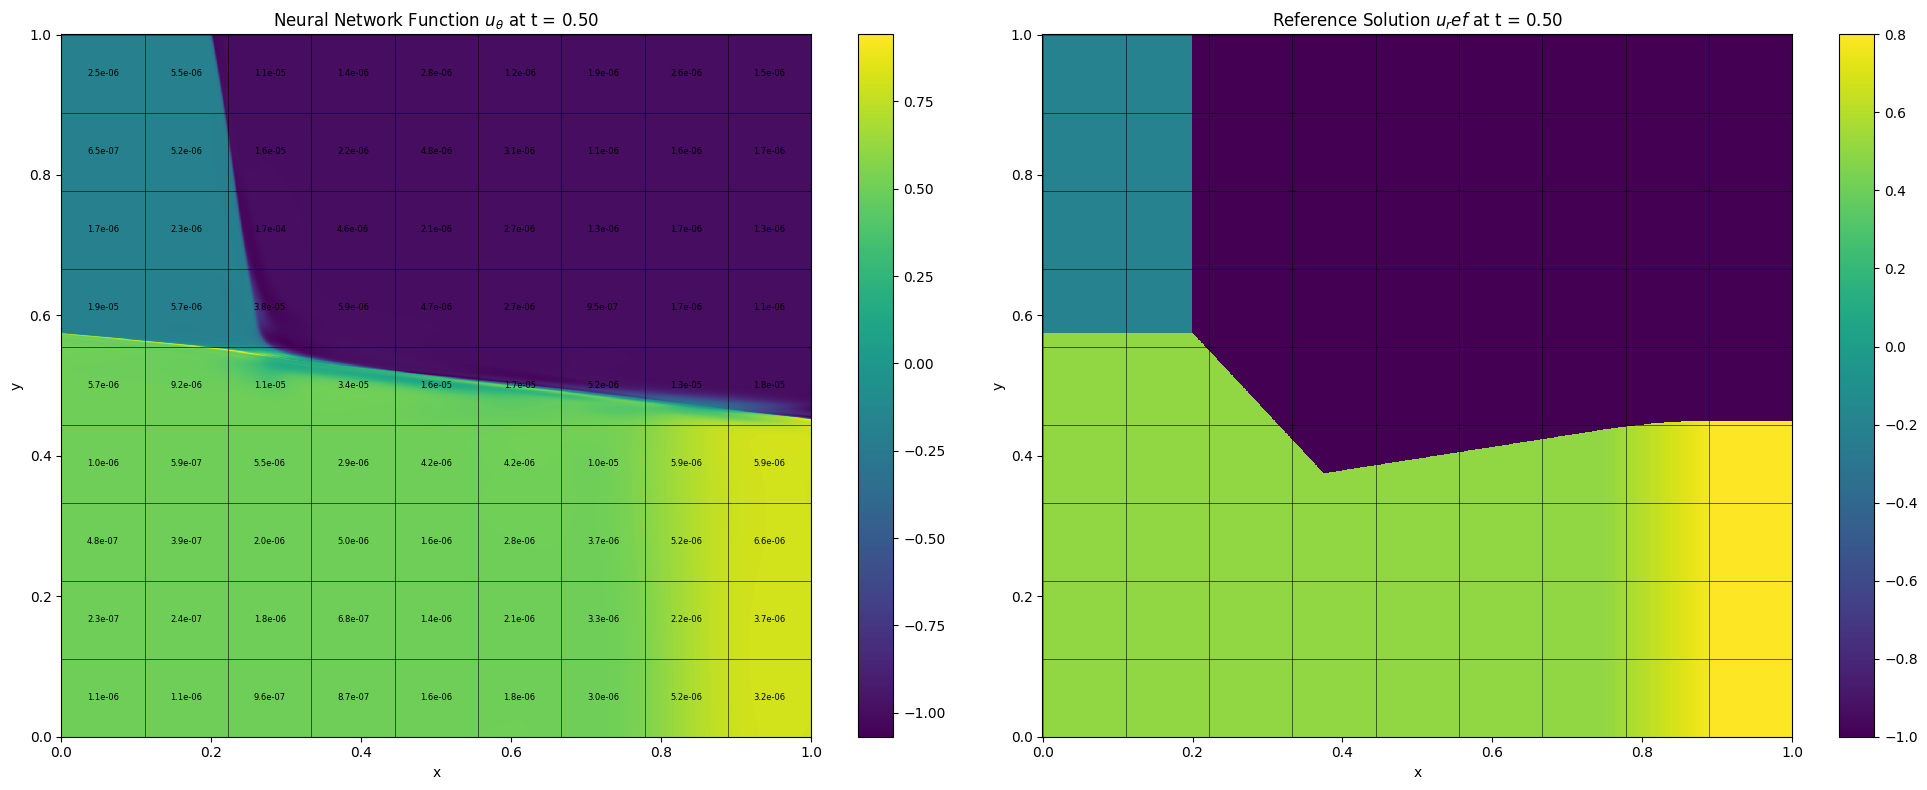

Updating importance sampling probabilities...
Grade 0, Iter 8100, loss_eqn: 0.007402, loss_eqn_from_kh: 0.007402 loss_l1: 0.007402, loss_ibc: 0.000614
Updating importance sampling probabilities...
Grade 0, Iter 8200, loss_eqn: 0.006911, loss_eqn_from_kh: 0.006911 loss_l1: 0.006911, loss_ibc: 0.000601
Updating importance sampling probabilities...
Grade 0, Iter 8300, loss_eqn: 0.006739, loss_eqn_from_kh: 0.006739 loss_l1: 0.006739, loss_ibc: 0.000594
Updating importance sampling probabilities...
Grade 0, Iter 8400, loss_eqn: 0.006576, loss_eqn_from_kh: 0.006576 loss_l1: 0.006576, loss_ibc: 0.000596
Updating importance sampling probabilities...
Grade 0, Iter 8500, loss_eqn: 0.006438, loss_eqn_from_kh: 0.006438 loss_l1: 0.006438, loss_ibc: 0.000590
Updating importance sampling probabilities...
Grade 0, Iter 8600, loss_eqn: 0.007065, loss_eqn_from_kh: 0.007065 loss_l1: 0.007065, loss_ibc: 0.000584
Updating importance sampling probabilities...
Grade 0, Iter 8700, loss_eqn: 0.007142, loss_eqn

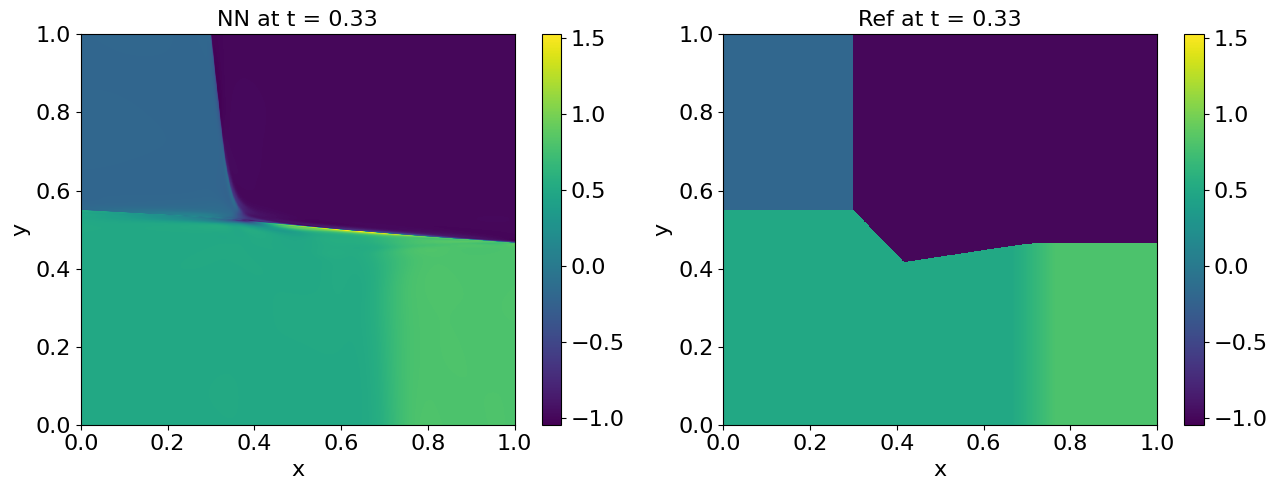

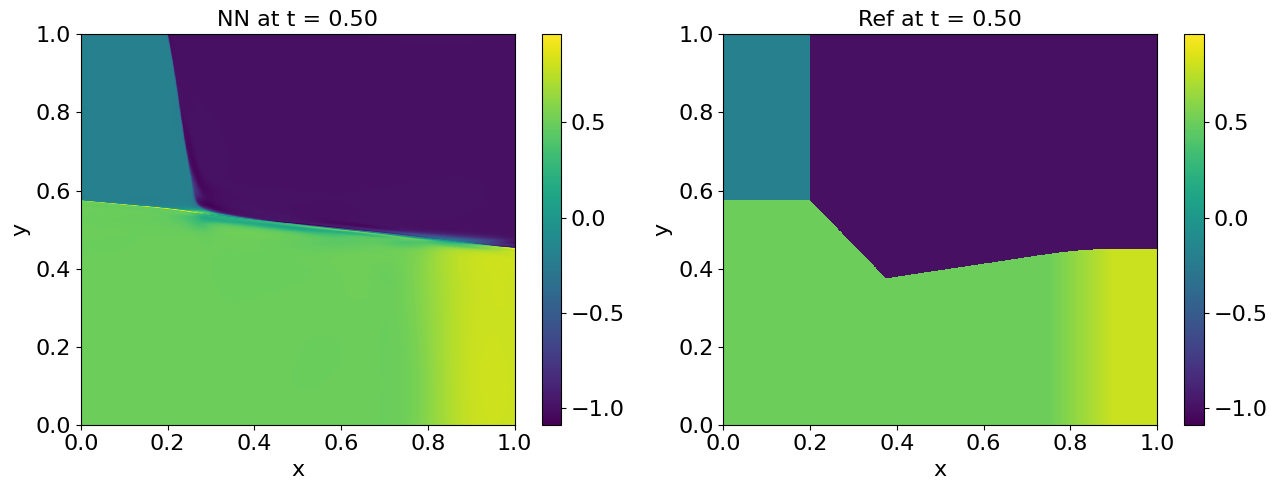

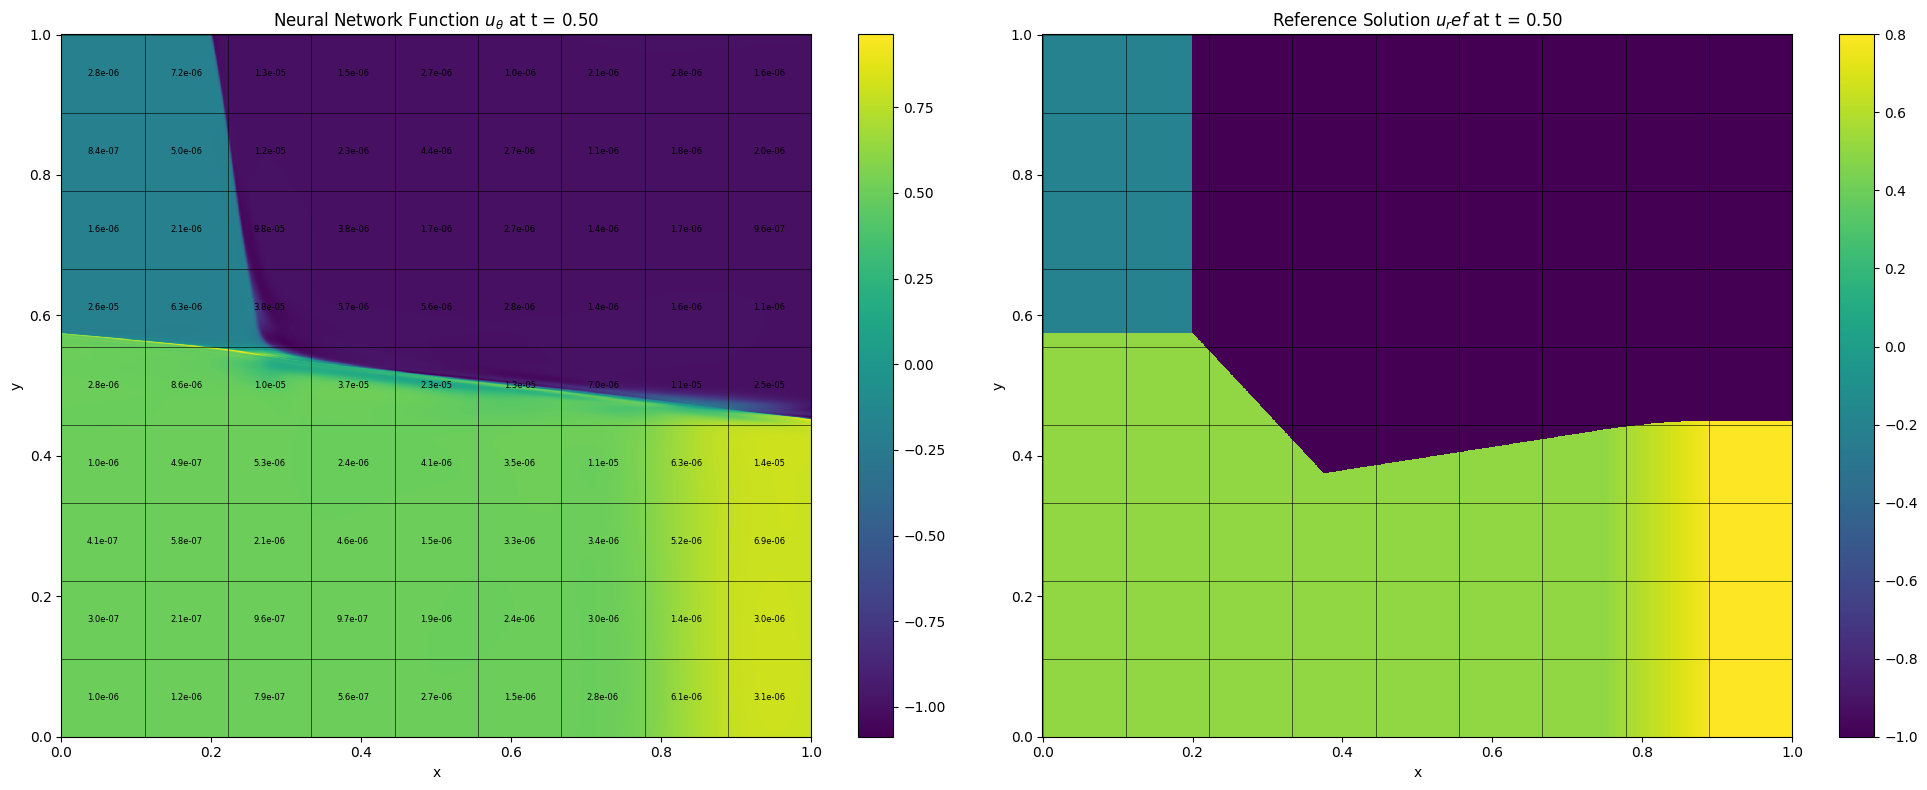

Updating importance sampling probabilities...
Grade 0, Iter 9100, loss_eqn: 0.006313, loss_eqn_from_kh: 0.006313 loss_l1: 0.006313, loss_ibc: 0.000554
Updating importance sampling probabilities...
Grade 0, Iter 9200, loss_eqn: 0.006689, loss_eqn_from_kh: 0.006689 loss_l1: 0.006689, loss_ibc: 0.000553
Updating importance sampling probabilities...
Grade 0, Iter 9300, loss_eqn: 0.005640, loss_eqn_from_kh: 0.005640 loss_l1: 0.005640, loss_ibc: 0.000551
Updating importance sampling probabilities...
Grade 0, Iter 9400, loss_eqn: 0.005730, loss_eqn_from_kh: 0.005730 loss_l1: 0.005730, loss_ibc: 0.000554
Updating importance sampling probabilities...
Grade 0, Iter 9500, loss_eqn: 0.005891, loss_eqn_from_kh: 0.005891 loss_l1: 0.005891, loss_ibc: 0.000548
Updating importance sampling probabilities...
Grade 0, Iter 9600, loss_eqn: 0.005687, loss_eqn_from_kh: 0.005687 loss_l1: 0.005687, loss_ibc: 0.000544
Updating importance sampling probabilities...
Grade 0, Iter 9700, loss_eqn: 0.005727, loss_eqn

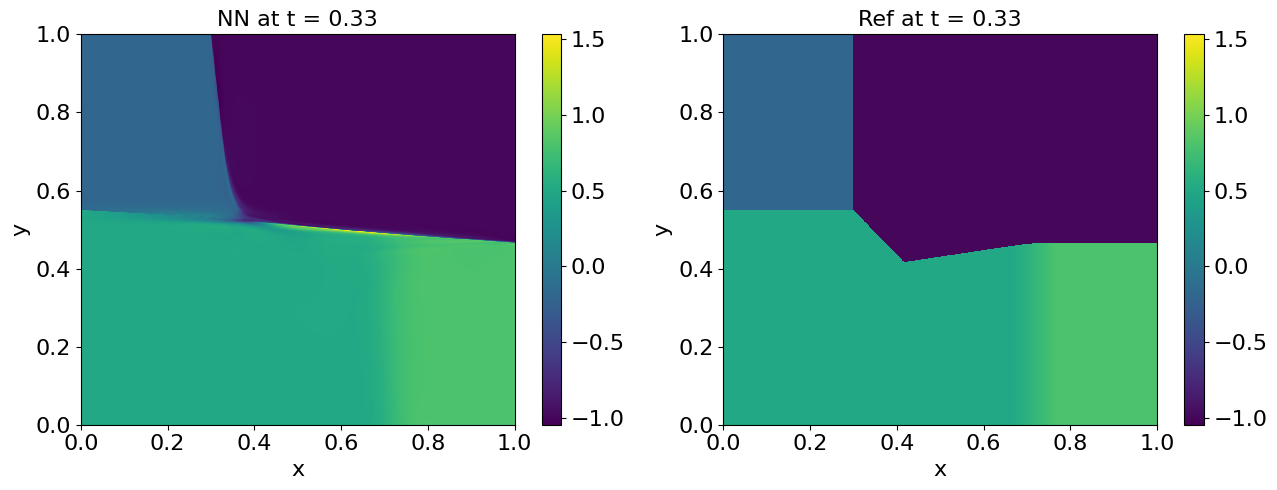

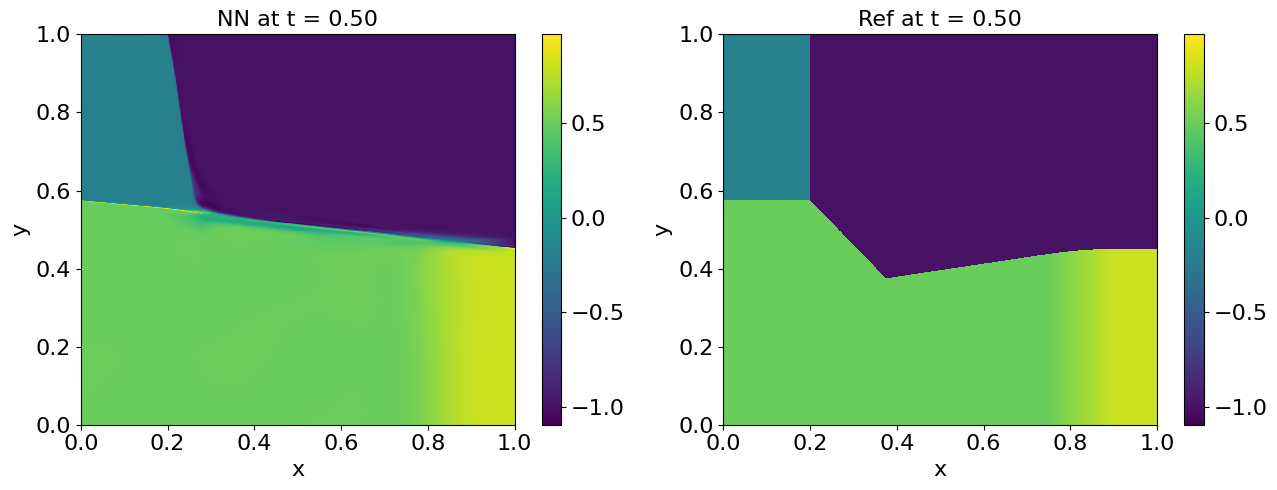

In [3]:
optprob.train_seq()

In [ ]:
def plot_u_theta_mesh(model, params=None, M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, y_min=None, y_max=None, M_y=None, ts=None, upload_fig=False, pwp=None, vals=None):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max].
    Optionally overlay the mesh from PiecewiseLinearPolynomials and denote vals on the meshes.
    The 1D plot at t = t_max is removed, and only the 2D plot is shown.

    Args:
        model: Neural network u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 1000).
        M_x: Number of grid points in the x-direction (default: 2000).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 0.5).
        x_min: Minimum value for x (default: -1.0).
        x_max: Maximum value for x (default: 1.0).
        y_min: Minimum value for y (for 3D cases, default: None).
        y_max: Maximum value for y (for 3D cases, default: None).
        M_y: Number of grid points in the y-direction (for 3D cases, default: None, falls back to M_x).
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
        upload_fig: Whether to upload the figure to wandb (default: False).
        pwp: Instance of PiecewiseLinearPolynomials(Tri/Rect/Hex/Tetra) to plot the mesh (default: None).
        vals: Values to denote on each mesh (default: None).
    """
    if ts is None:
        ts = []

    input_dim = model.input_dim if hasattr(model, 'input_dim') else 2
    if M_y is None:
        M_y = M_x

    if input_dim == 2:
        # Create a grid for t and x over the specified ranges
        t_grid = np.linspace(t_min, t_max, M_t)
        x_grid = np.linspace(x_min, x_max, M_x)
        t, x = np.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

        # Flatten the grid for batch evaluation
        tx_points = np.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(tx_points)
        else:
            u_values = model.forward_with_params(params, tx_points) if hasattr(model, 'forward_with_params') else model(params, tx_points)
        u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

        # Create larger figure for the 2D plot
        t_range = t_max - t_min
        fig = plt.figure(figsize=(20, 8 + 8 * t_range))
        ax1 = fig.add_subplot(111)

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title('Neural Network Function $u_\\theta$')

        # Overlay the mesh and denote vals if pwp and vals are provided
        if pwp is not None:
            if isinstance(pwp, PiecewiseLinearPolynomialsTri):
                triangles = pwp.partitions
                for idx, tri in enumerate(triangles):
                    # Plot the three edges of the triangle
                    ax1.plot([tri[0][1], tri[1][1]], [tri[0][0], tri[1][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[1][1], tri[2][1]], [tri[1][0], tri[2][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[2][1], tri[0][1]], [tri[2][0], tri[0][0]], color='black', alpha=0.5, linewidth=0.5)
                    center = np.mean(tri, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

            elif isinstance(pwp, PiecewiseLinearPolynomialsRect):
                rectangles = pwp.partitions
                for idx, rect in enumerate(rectangles):
                    # Plot the four edges of the rectangle
                    ax1.plot([rect[0][1], rect[1][1]], [rect[0][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Bottom
                    ax1.plot([rect[0][1], rect[2][1]], [rect[0][0], rect[2][0]], color='black', alpha=0.5, linewidth=0.5)  # Left
                    ax1.plot([rect[2][1], rect[3][1]], [rect[2][0], rect[3][0]], color='black', alpha=0.5, linewidth=0.5)  # Top
                    ax1.plot([rect[3][1], rect[1][1]], [rect[3][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Right
                    center = np.mean(rect, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the main figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_tmin{t_min:.1f}_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    elif input_dim == 3:
        if y_min is None or y_max is None:
            raise ValueError("For input_dim=3, y_min and y_max must be provided.")

        # 2D plot at t = t_max over (x, y)
        x_grid = np.linspace(x_min, x_max, M_x)
        y_grid = np.linspace(y_min, y_max, M_y)
        x, y = np.meshgrid(x_grid, y_grid)  # Shapes: (M_x, M_y)
        
        t = t_max * np.ones_like(x)
        txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(txy_points)
        else:
            u_values = model.forward_with_params(params, txy_points) if hasattr(model, 'forward_with_params') else model(params, txy_points)
        u_values = u_values.reshape(M_y, M_x)  # Reshape to (M_x, M_y)
        
        # Create figure for the 2D plot at t_max
        fig = plt.figure(figsize=(10, 8))
        ax1 = fig.add_subplot(111)
        
        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, y_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('y')
        ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')
        
        # Overlay the mesh and denote vals for elements sharing a face with t = t_max
        
        if pwp is not None:
            partitions = pwp.partitions
            # Find elements that share a face with t = t_max (i.e., max t == t_max)
            max_t_per_elem = np.max(partitions[:, :, 0], axis=1)
            surface_mask = np.isclose(max_t_per_elem, t_max, atol=1e-6)
            surface_elems = partitions[surface_mask]
            surface_indices = np.where(surface_mask)[0]
            
            if isinstance(pwp, PiecewiseLinearPolynomialsHex):
                
                for i, hex_elem in enumerate(surface_elems):
                    # Find vertices at t = t_max (top face)
                    top_mask = np.isclose(hex_elem[:, 0], t_max, atol=1e-6)
                    top_verts = hex_elem[top_mask]
                    if len(top_verts) == 4:  # Expected for hex top face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        # Order for closed rectangle: assuming vertices [lowx lowy, lowx highy, highx lowy, highx highy]
                        # Indices based on binary order: 0: lowx lowy, 1: lowx highy, 2: highx lowy, 3: highx highy
                        indices = np.array([0, 1, 3, 2])
                        ax1.plot(np.append(x_top[indices], x_top[indices[0]]), np.append(y_top[indices], y_top[indices[0]]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            
            elif isinstance(pwp, PiecewiseLinearPolynomialsTetra):
                for i, tet in enumerate(surface_elems):
                    # Find vertices at t = t_max
                    top_mask = np.isclose(tet[:, 0], t_max, atol=1e-6)
                    top_verts = tet[top_mask]
                    if len(top_verts) == 3:  # Triangle face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        ax1.plot(np.append(x_top, x_top[0]), np.append(y_top, y_top[0]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            else:
                print("No such class!!!")
        plt.tight_layout()
        # Upload the figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_at_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    # Plot separate figures for each timestamp in ts (adapted for dimension)
    for t_val in ts:
        if input_dim == 2:
            # Find the closest index in t_grid
            idx = np.argmin(np.abs(t_grid - t_val))
            # Create a new figure for the snapshot
            fig, ax = plt.subplots(1, 1, figsize=(10, 4))
            ax.plot(x_grid, u_values[idx, :])
            ax.set_xlabel('x')
            ax.set_ylabel('$u_\\theta(t, x)$')
            ax.set_title(f'Neural Network Function at t = {t_val:.2f} (closest t = {t_grid[idx]:.2f})')
            plt.tight_layout()
            plt.show()
        elif input_dim == 3:
            # Similar to t_max plot but without mesh/vals (or adapt if needed)
            x, y = np.meshgrid(x_grid, y_grid)
            t = t_val * np.ones_like(x)
            txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)
            u_values_ts = model.forward(txy_points).reshape(M_y, M_x)
            fig_ts, ax_ts = plt.subplots(1, 1, figsize=(10, 8))
            pcm_ts = ax_ts.pcolormesh(x_grid, y_grid, u_values_ts, shading='nearest', cmap='viridis')
            fig_ts.colorbar(pcm_ts, ax=ax_ts)
            ax_ts.set_xlabel('x')
            ax_ts.set_ylabel('y')
            ax_ts.set_title(f'Neural Network Function $u_\\theta$ at t = {t_val:.2f}')
            plt.tight_layout()
            plt.show()

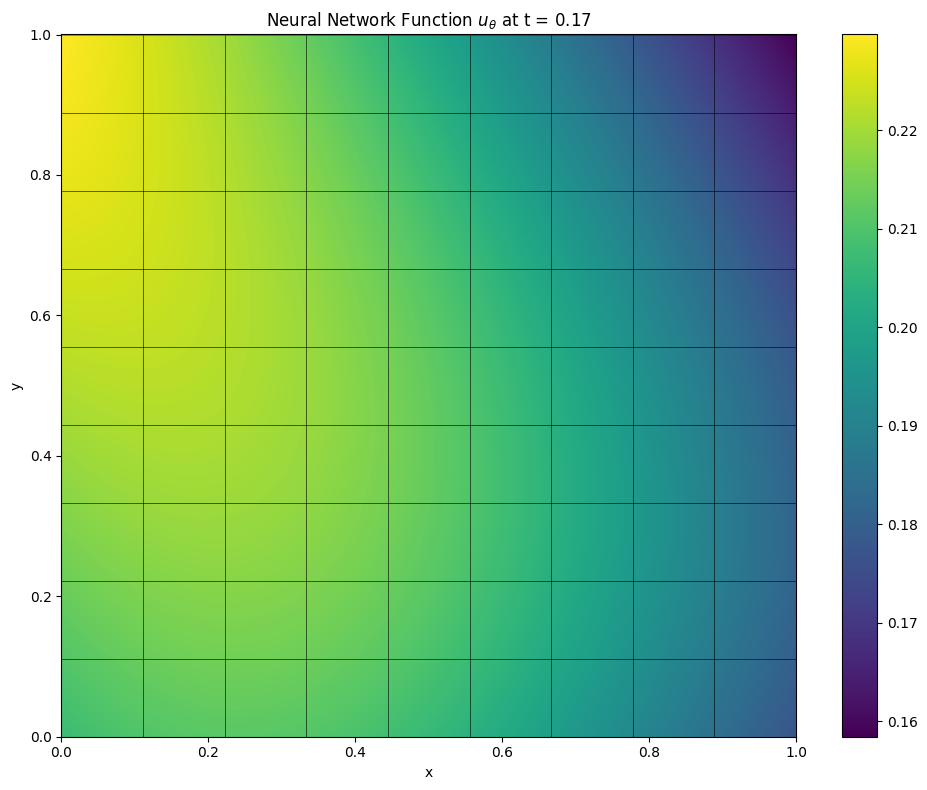

In [7]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

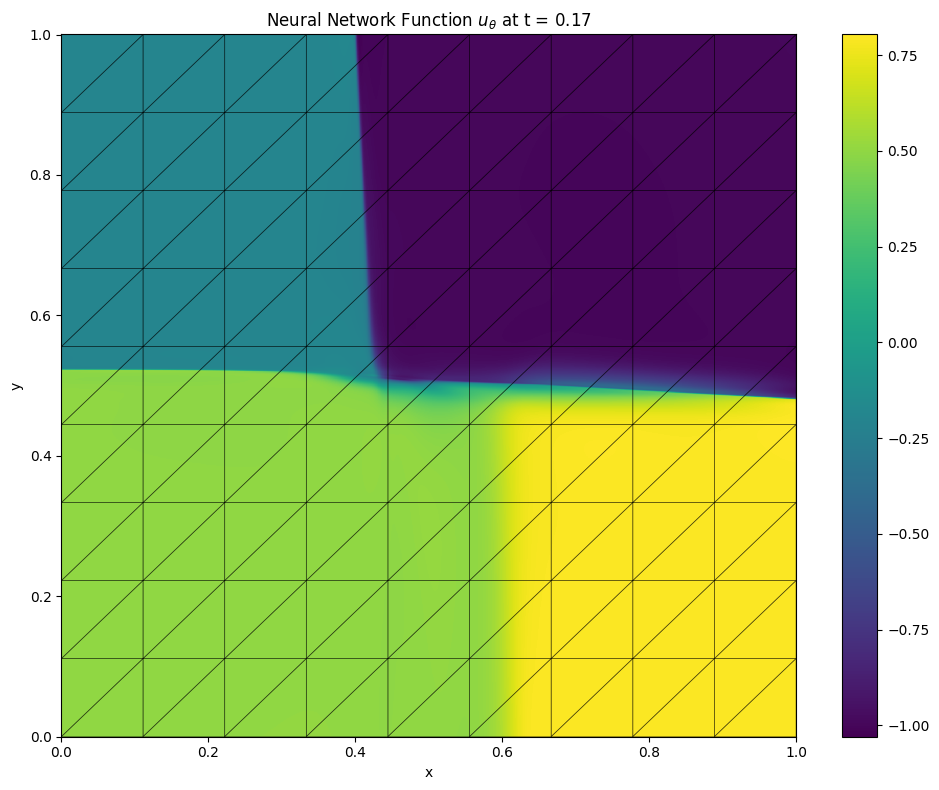

In [37]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


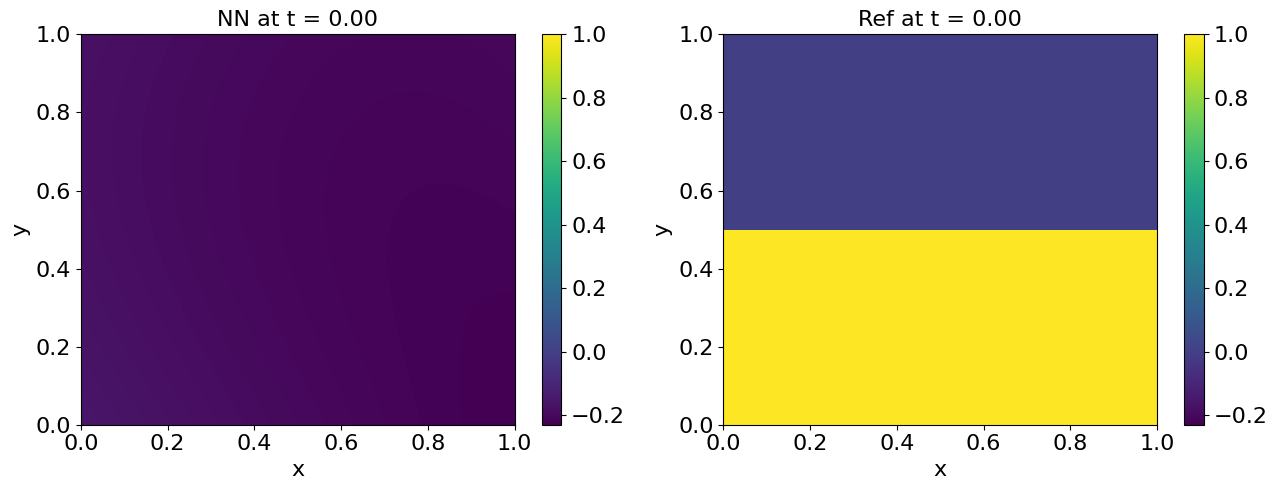

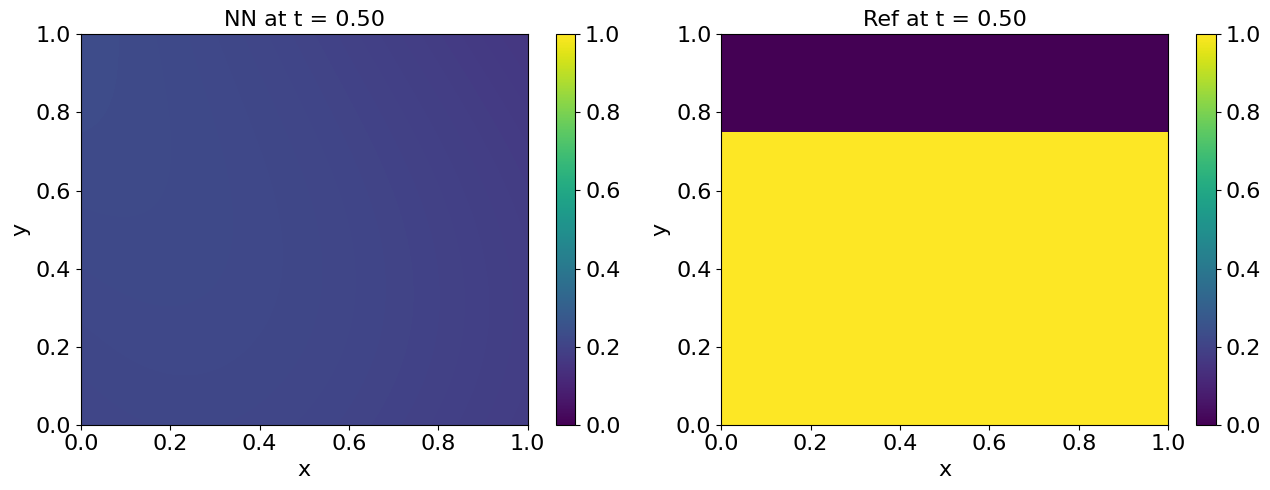

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


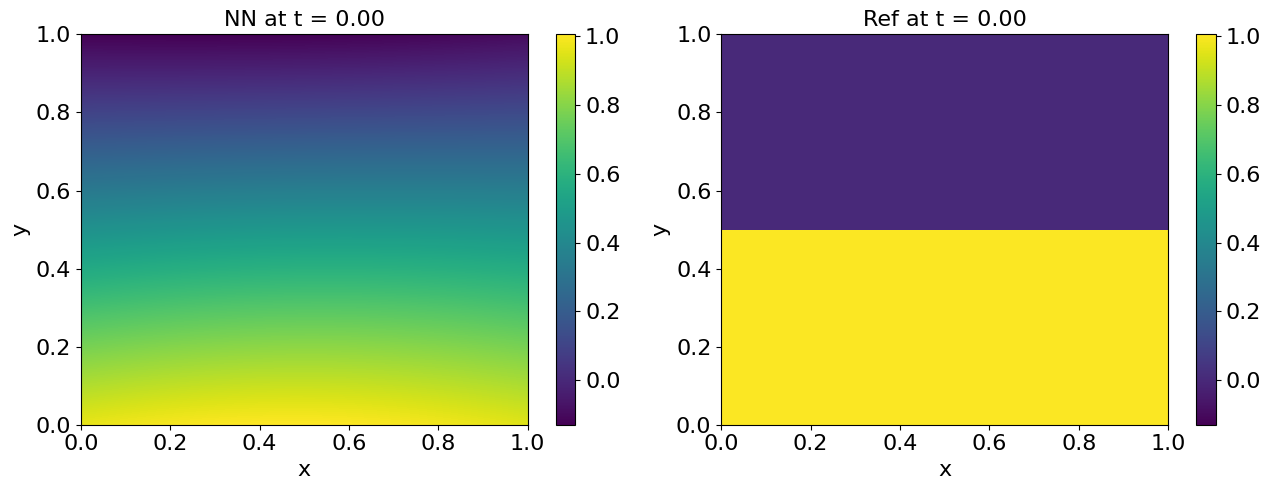

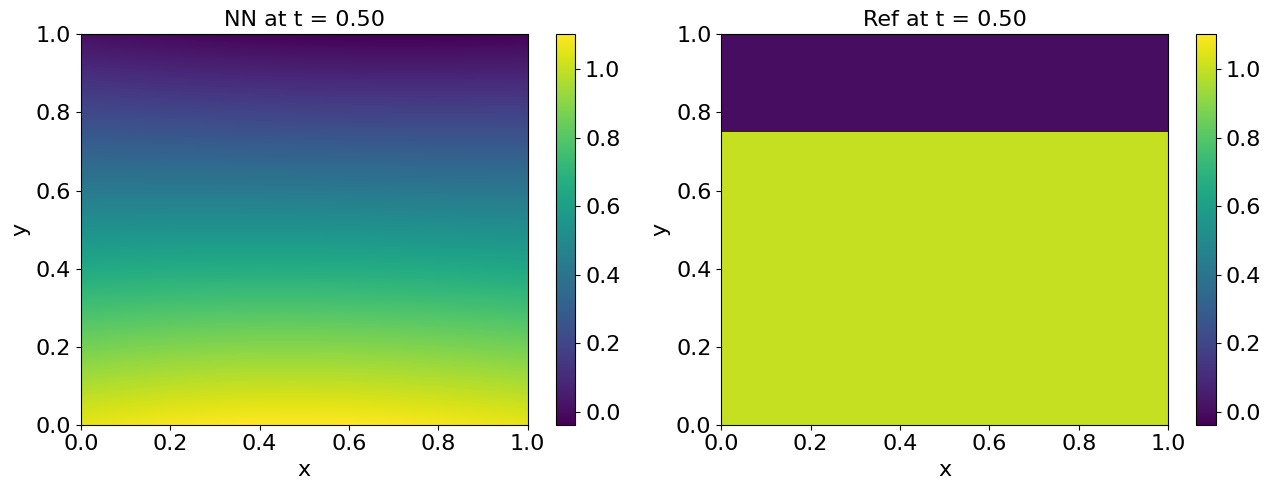

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

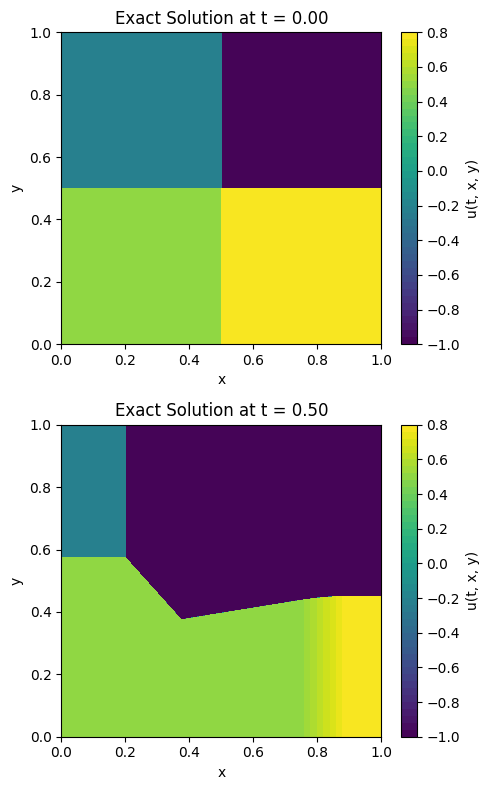

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

Text(0.5, 1.0, 'Neural Network Function $u_\\theta$ at t = 1.00')

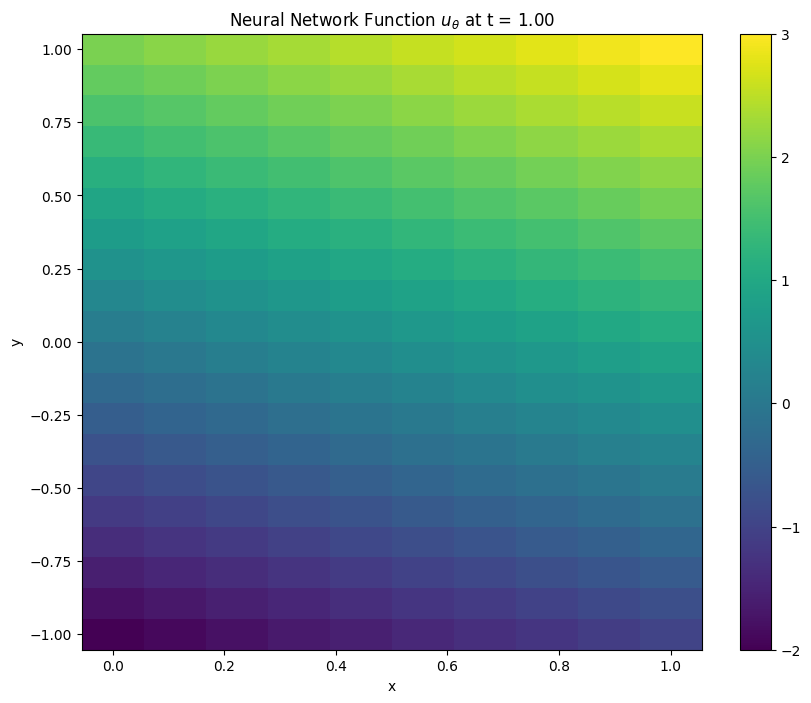

In [70]:
x_min = 0
x_max = 1
M_x = 10
y_min = -1
y_max = 1
M_y = 20
t_max = 1
# 2D plot at t = t_max over (x, y)
x_grid = np.linspace(x_min, x_max, M_x)
y_grid = np.linspace(y_min, y_max, M_y)
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')  # Shapes: (M_x, M_y)
        
t = t_max * np.ones_like(x)
txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
# Evaluate u_theta on the grid points
u_values = txy_points[:,1]+2*txy_points[:,2]
u_values = u_values.reshape(x.shape)  # Reshape to (M_y, M_x)
        
# Create figure for the 2D plot at t_max
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111)
        
# 2D color mesh plot
pcm = ax1.pcolormesh(x_grid, y_grid, u_values.T, shading='nearest', cmap='viridis')
fig.colorbar(pcm, ax=ax1)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')

In [56]:
x_grid.shape

(10,)

In [54]:
x, y = np.meshgrid(x_grid, y_grid)

In [55]:
x.shape

(20, 10)

In [58]:
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')

In [6]:
jnp.maximum(jnp.ones(10), 0)

Array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32)

In [6]:
print(f'{0.000123: .1e}')

 1.2e-04


In [ ]:
ax1.text(center[1], center[0], f'{vals[idx]: .0e}', fontsize=4, color='black', ha='center', va='center', clip_on=True, bbox=dict(facecolor='white', alpha=0.5, pad=1))

In [ ]:
ax1.text(center[1], center[0], f'{vals[idx]: .0e}', fontsize=4, color='black', ha='center', va='center', clip_on=True, bbox=dict(facecolor='white', alpha=0.5, pad=1))